# CaloDiffusion study — GitHub-to-Colab, no Drive assets required

The project code, cached reference showers, pretrained weights, configurations, and geometry
files are fetched from the public GitHub repository into Colab's local `/content` storage.
**You do not need to put datasets or model files on Google Drive first.**

## Start here
1. Upload this notebook using **File → Upload notebook** in Colab.
2. Select **Runtime → Change runtime type → GPU**, then connect.
3. Keep `COLAB_PARTICLES = ("electron",)` and `COLAB_PROFILE = "smoke_light"` initially.
4. Run setup **A–F**. D clones the repository; E checks the actual data and checkpoint files.
5. Run study **Sections 0–5**, stop and inspect the validation checks, then continue in order.
6. Download a completed result archive before ending the runtime (instructions at the bottom).

**Drive is optional.** It is disabled by default in this edition. Setting `USE_GOOGLE_DRIVE = True`
only enables persistent output backups and an optional fallback location for assets. An empty
Drive is fine: the outputs folder will be created. Working assets still come from GitHub.

**Important:** opening a notebook from GitHub does not itself download companion files.
Run setup D and E in the same Colab session as the analysis.

**Default profile:** a small execution test, not adequate statistics for physics claims.
The original diffusion schedule, study algorithms, and numerical validation gates are unchanged.
The cached data are convenience subsets; do not assume they were unseen by checkpoint training.

**Storage:** `/content` and its files disappear when the runtime is deleted. A locally saved ZIP
is not a persistent backup until you download it to your computer or copy it to Drive.
Saving the notebook does not preserve downloaded data, model weights, or Python variables.

**Verification boundary:** the public GitHub listings for the electron HDF5 cache and checkpoint
were inspected. This edition was syntax-checked locally. Live binary downloads and real-checkpoint
GPU execution in Colab have not been performed here; retain the runtime checks below.
Only load checkpoints and replay snapshots from sources you trust.


## A. Choose the first run
These defaults require **no Google Drive mounting and no manual dataset upload**.
Keep one particle and the light profile until the validation checks pass.

The repository README describes committed electron/photon/pion caches and pretrained checkpoints.
Setup D downloads the project subtree; E validates the files at the wrapper's expected paths.
For the first electron run, the key assets are:
```
capstone/calodiffusion/data/calochallenge_ds2.hdf5
capstone/calodiffusion/paper_code/trained_models/dataset2.pth
```

A full Git commit hash can be supplied for a reproducible fresh clone. An existing checkout is
never silently pulled or reset. Back up outputs before choosing a new source version.
Set `USE_GOOGLE_DRIVE=True` only to enable Drive backups; pre-existing Drive assets are not required.


In [1]:
import os, sys, subprocess, shutil, json, re, hashlib, zipfile
from pathlib import Path
from datetime import datetime, timezone

COLAB_PARTICLES = ("electron","photon","pion")
COLAB_PROFILE = "original_smoke"  # smoke_light, original_smoke, research
USE_GOOGLE_DRIVE = False  # Assets are downloaded from GitHub; Drive is optional for outputs.
REPO_URL = "https://github.com/Vishal21501/gen-hep-notebooks.git"
REPO_COMMIT = ""  # Optional full 40-character Git SHA; blank selects main on a NEW clone only.
COLAB_REPO = Path("/content/gen-hep-notebooks")
COLAB_ROOT = COLAB_REPO / "capstone" / "calodiffusion"
DRIVE_RESULTS_BASE = Path("/content/drive/MyDrive/CaloDiffusion_results")
DRIVE_ASSETS = Path("/content/drive/MyDrive/CaloDiffusion_assets")

if not Path('/content').is_dir():
    raise RuntimeError('This edition expects a managed Google Colab runtime with /content.')
if COLAB_PROFILE not in {'smoke_light', 'original_smoke', 'research'}:
    raise ValueError('Unknown COLAB_PROFILE.')
if not COLAB_PARTICLES or not set(COLAB_PARTICLES) <= {'electron', 'photon', 'pion'}:
    raise ValueError('Choose electron, photon, and/or pion.')
if REPO_COMMIT and not re.fullmatch(r'[0-9a-fA-F]{40}', REPO_COMMIT):
    raise ValueError('REPO_COMMIT must be a full Git SHA or an empty string.')
if sys.version_info < (3, 10):
    raise RuntimeError('Python 3.10+ is required.')
# Set before CUDA computations. Do not change precision or sampler settings to bypass gates.
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ['CALODIFF_DEVICE'] = 'cuda'
print('Profile:', COLAB_PROFILE, '| particles:', COLAB_PARTICLES)
print('Local project:', COLAB_ROOT)

Profile: original_smoke | particles: ('electron', 'photon', 'pion')
Local project: /content/gen-hep-notebooks/capstone/calodiffusion


## B. Install missing analysis packages without replacing PyTorch
Keep Colab's installed PyTorch/CUDA combination. This cell installs only packages that are missing
or below the study's minimum requirements; it does not deliberately upgrade an already sufficient
numerical stack. If a package was already imported and needs replacing, restart the session first.
After a package change, restart if Colab requests it and rerun setup from A.

In [2]:
from importlib import metadata as package_metadata
from packaging.requirements import Requirement

# Removed 'ipykernel>=6.25' to avoid raising a RuntimeError for an already loaded active kernel
requirements = [
    'numpy>=1.24', 'scipy>=1.10', 'pandas>=2.0', 'matplotlib>=3.7',
    'h5py>=3.8', 'PyYAML>=6.0', 'scikit-learn>=1.2', 'tqdm>=4.65',
    'einops>=0.6', 'nbformat>=5.9'
]
module_names = {'PyYAML':'yaml', 'scikit-learn':'sklearn'}
missing = []
for spec in requirements:
    req = Requirement(spec)
    try:
        version = package_metadata.version(req.name)
        satisfied = req.specifier.contains(version, prereleases=True)
    except package_metadata.PackageNotFoundError:
        satisfied = False
    if not satisfied:
        imported_name = module_names.get(req.name, req.name.replace('-', '_'))
        if imported_name in sys.modules:
            raise RuntimeError(f'{spec} requires installation, but {imported_name} is already loaded. '
                               'Restart the session, then run setup first.')
        missing.append(spec)
if missing:
    print('Installing:', missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', *missing], check=True)
else:
    print('All required analysis packages meet minimum versions; nothing replaced.')

import torch
import h5py
import numpy as np
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU. Select Runtime > Change runtime type > GPU, then reconnect.')
props = torch.cuda.get_device_properties(0)
probe = torch.ones(1, device='cuda') + 1
torch.cuda.synchronize()
del probe
print('GPU:', props.name, '| total VRAM GiB:', round(props.total_memory / 2**30, 2))
print('Free local disk GiB:', round(shutil.disk_usage('/content').free / 2**30, 2))
COLAB_ENV = dict(python=sys.version, torch=torch.__version__, cuda=torch.version.cuda,
                 gpu=props.name, gpu_memory_bytes=props.total_memory, profile=COLAB_PROFILE)

All required analysis packages meet minimum versions; nothing replaced.
Python: 3.13.15 | PyTorch: 2.11.0+cu130 | CUDA: 13.0
GPU: Tesla T4 | total VRAM GiB: 14.56
Free local disk GiB: 193.32


## C. Optional Drive backups (skipped by default)
With `USE_GOOGLE_DRIVE=False`, this cell makes no authentication request. Continue to setup D.

With `True`, authorize Google's mount prompt to persist result archives in a newly created folder.
Your Drive does not need to contain input data or model weights. Mounting permits notebook code
to access Drive; use it only for a notebook you trust.


In [3]:
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_RESULTS_BASE.mkdir(parents=True, exist_ok=True)
    print('Backups will be copied to:', DRIVE_RESULTS_BASE)
else:
    print('WARNING: Drive backups disabled. /content and all Python state are temporary.')

## D. Obtain the project without a silent source update
The first run clones only the project subtree using Git's sparse checkout. A subsequent execution
reuses the current checkout without pulling new changes. The exact revision is printed and recorded.
Large-file pointers, when present, are handled in the next cell. A clone still needs internet access.

In [4]:
clone_env = dict(os.environ, GIT_LFS_SKIP_SMUDGE='1')
if not COLAB_REPO.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
                    '--branch', 'main', REPO_URL, str(COLAB_REPO)], check=True, env=clone_env)
    subprocess.run(['git', '-C', str(COLAB_REPO), 'sparse-checkout', 'set',
                    'capstone/calodiffusion'], check=True, env=clone_env)
    if REPO_COMMIT:
        subprocess.run(['git', '-C', str(COLAB_REPO), 'fetch', '--depth', '1', 'origin',
                        REPO_COMMIT], check=True, env=clone_env)
        subprocess.run(['git', '-C', str(COLAB_REPO), 'checkout', '--detach', REPO_COMMIT],
                       check=True, env=clone_env)
elif not (COLAB_REPO / '.git').exists():
    raise RuntimeError(f'{COLAB_REPO} exists but is not a Git checkout. Use a new path or a fresh runtime.')

COLAB_GIT_SHA = subprocess.check_output(
    ['git', '-C', str(COLAB_REPO), 'rev-parse', 'HEAD'], text=True).strip()
if REPO_COMMIT and COLAB_GIT_SHA.lower() != REPO_COMMIT.lower():
    raise RuntimeError('Existing checkout differs from REPO_COMMIT. It was not changed. '
                       'Preserve outputs, then use a fresh checkout for the requested revision.')
if not (COLAB_ROOT / 'calodiff_probe.py').is_file():
    raise FileNotFoundError(f'Missing calodiff_probe.py in {COLAB_ROOT}. Inspect the checkout before proceeding.')
COLAB_ENV['git_sha'] = COLAB_GIT_SHA
print('Git revision:', COLAB_GIT_SHA)
print('Project:', COLAB_ROOT)

Git revision: 9694f81f602d1e2cd8c81c2d40aaf41d9b7806fa
Project: /content/gen-hep-notebooks/capstone/calodiffusion


## E. Check the files downloaded from GitHub
The notebook attachment contains code, not the binary dataset or weights. Setup D obtains
those companion files from the repository. This cell checks the selected particle's HDF5,
checkpoint, configuration, and geometry XML.

It attempts Git LFS retrieval when an LFS pointer is present. If GitHub/LFS download fails,
it stops instead of treating the pointer or an error page as real data. Inspect the fetch error;
a missing local file does **not** imply you must first upload it to Drive.

A trusted Drive asset is considered only if you explicitly enabled Drive and supplied that asset.
No different checkpoint or reference dataset is substituted. Loading the model and passing the
study's checks are still required; an initial size check is not checkpoint verification.


In [5]:
ASSET_MAP = {
    'electron': dict(data='data/calochallenge_ds2.hdf5',
                     checkpoint='paper_code/trained_models/dataset2.pth',
                     config='paper_code/configs/config_dataset2.json',
                     xml='paper_code/CaloChallenge/code/binning_dataset_2.xml'),
    'photon': dict(data='data/calochallenge_ds1_photon.hdf5',
                   checkpoint='paper_code/trained_models/dataset1_photon.pth',
                   config='paper_code/configs/config_dataset1_photon.json',
                   xml='paper_code/CaloChallenge/code/binning_dataset_1_photons.xml'),
    'pion': dict(data='data/calochallenge_ds1_pion.hdf5',
                 checkpoint='paper_code/trained_models/dataset1_pion.pth',
                 config='paper_code/configs/config_dataset1_pion.json',
                 xml='paper_code/CaloChallenge/code/binning_dataset_1_pions.xml')
}

def is_lfs_pointer(path):
    path = Path(path)
    if not path.is_file():
        return False
    with path.open('rb') as f:
        return f.read(160).startswith(b'version https://git-lfs.github.com/spec/v1')

def asset_usable(path, kind):
    path = Path(path)
    if not path.is_file() or is_lfs_pointer(path):
        return False
    return bool(h5py.is_hdf5(path)) if kind == 'data' else path.stat().st_size >= 1024

wanted = [(p, kind, ASSET_MAP[p][kind]) for p in COLAB_PARTICLES for kind in ('data', 'checkpoint')]
pointers = [str((COLAB_ROOT / rel).relative_to(COLAB_REPO))
            for _, _, rel in wanted if is_lfs_pointer(COLAB_ROOT / rel)]
if pointers:
    try:
        exists = subprocess.run(['git', 'lfs', 'version'], capture_output=True).returncode == 0
        if not exists:
            subprocess.run(['apt-get', 'update', '-qq'], check=True)
            subprocess.run(['apt-get', 'install', '-y', '-qq', 'git-lfs'], check=True)
        subprocess.run(['git', '-C', str(COLAB_REPO), 'lfs', 'install', '--local'], check=True)
        subprocess.run(['git', '-C', str(COLAB_REPO), 'lfs', 'pull',
                        '--include=' + ','.join(pointers), '--exclude='], check=True)
    except (subprocess.CalledProcessError, OSError) as exc:
        print('Git LFS retrieval failed. Optional Drive fallback is used only when enabled:', exc)

problems = []
for particle, kind, rel in wanted:
    dest = COLAB_ROOT / rel
    if not asset_usable(dest, kind):
        src = DRIVE_ASSETS / rel
        if USE_GOOGLE_DRIVE and asset_usable(src, kind):
            if shutil.disk_usage('/content').free < src.stat().st_size + 256*2**20:
                raise OSError('Insufficient local disk to stage the selected asset safely.')
            dest.parent.mkdir(parents=True, exist_ok=True)
            temp = dest.with_name(dest.name + '.copying')
            shutil.copy2(src, temp)
            if not asset_usable(temp, kind):
                raise IOError(f'Copied asset failed validation: {temp}')
            temp.replace(dest)
            print('Copied trusted Drive asset locally:', dest)
        else:
            problems.append(f'{particle} {kind}: expected {dest}\n  Repository path: capstone/calodiffusion/{rel}')
    if asset_usable(dest, kind):
        print(f'{particle:8s} {kind:10s} {dest.stat().st_size/2**20:9.2f} MiB  {dest.name}')
for particle in COLAB_PARTICLES:
    for kind in ('config', 'xml'):
        if not (COLAB_ROOT / ASSET_MAP[particle][kind]).is_file():
            problems.append(f'Missing {particle} {kind}: {COLAB_ROOT / ASSET_MAP[particle][kind]}')
if problems:
    raise FileNotFoundError('GitHub assets are incomplete in this Colab runtime. Inspect the clone/LFS '
                            'errors in setup D/E and confirm the files exist at the recorded revision. '
                            'Do not bypass this check. No pre-existing Drive dataset is required.\n\n' + '\n\n'.join(problems))

for particle in COLAB_PARTICLES:
    with h5py.File(COLAB_ROOT / ASSET_MAP[particle]['data'], 'r') as f:
        if not {'showers', 'incident_energies'} <= set(f):
            raise KeyError(f'{particle}: expected showers and incident_energies datasets.')
        print(particle, 'HDF5:', {k: f[k].shape for k in ('showers', 'incident_energies')})
print('Selected assets are present. No checkpoint has been loaded by this setup cell.')

electron data           81.14 MiB  calochallenge_ds2.hdf5
electron checkpoint      6.16 MiB  dataset2.pth
photon   data           11.54 MiB  calochallenge_ds1_photon.hdf5
photon   checkpoint      6.22 MiB  dataset1_photon.pth
pion     data           10.60 MiB  calochallenge_ds1_pion.hdf5
pion     checkpoint      6.27 MiB  dataset1_pion.pth
electron HDF5: {'showers': (12000, 6480), 'incident_energies': (12000, 1)}
photon HDF5: {'showers': (12000, 368), 'incident_energies': (12000, 1)}
pion HDF5: {'showers': (12000, 533), 'incident_energies': (12000, 1)}
Selected assets are present. No checkpoint has been loaded by this setup cell.


## F. Package completed results
At section boundaries, saved result files are packaged into a ZIP archive. With Drive disabled,
archives stay under `/content/calo_backup_staging/` and must be downloaded before runtime deletion.
With Drive enabled, archives are copied to Drive and the copied checksum is verified.

These calls are synchronous, not background work, and preserve saved files rather than a live
Python session. The most recent completed archive is `COLAB_LAST_BACKUP`.

To download a completed archive after any stage, run in a new cell:
```python
from google.colab import files as colab_files
colab_files.download(COLAB_LAST_BACKUP)
```
If you need to package files written since the last stage, first run `colab_backup("manual")`.
Cumulative archives take local disk space; manage older copies only after securing a good download.


In [6]:
def colab_file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(4 * 2**20), b''):
            digest.update(chunk)
    return digest.hexdigest()


def colab_backup(stage):
    global COLAB_LAST_BACKUP
    if 'OUT' not in globals() or not Path(OUT).is_dir():
        print('No run output directory yet; nothing to back up.')
        return None
    root = Path(OUT).resolve()
    stage = re.sub(r'[^A-Za-z0-9_.-]+', '_', str(stage))
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    scratch = Path('/content/calo_backup_staging')
    scratch.mkdir(parents=True, exist_ok=True)
    archive = scratch / f'{root.name}_{stage}_{stamp}.zip'
    files_to_save = sorted(p for p in root.rglob('*') if p.is_file())
    needed = sum(p.stat().st_size for p in files_to_save)
    if shutil.disk_usage(scratch).free < needed + 64*2**20:
        raise OSError('Not enough local disk to create a result archive. Preserve or free storage first.')
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=1) as z:
        for path in files_to_save:
            z.write(path, Path(root.name) / path.relative_to(root))
    receipt = dict(stage=stage, run=root.name, created_utc=stamp, sha256=colab_file_sha256(archive),
                   size_bytes=archive.stat().st_size, files=len(files_to_save))
    if USE_GOOGLE_DRIVE:
        dest_dir = DRIVE_RESULTS_BASE / root.name
        dest_dir.mkdir(parents=True, exist_ok=True)
        dest = dest_dir / archive.name
        partial = dest.with_name(dest.name + '.partial')
        shutil.copy2(archive, partial)
        if colab_file_sha256(partial) != receipt['sha256']:
            raise IOError(f'Backup checksum mismatch: {partial}; local archive retained at {archive}.')
        partial.replace(dest)
        dest.with_suffix('.receipt.json').write_text(json.dumps(receipt, indent=2))
        archive.unlink()  # only the redundant staging archive; original output files remain local.
    else:
        dest = archive
        dest.with_suffix('.receipt.json').write_text(json.dumps(receipt, indent=2))
    COLAB_LAST_BACKUP = str(dest)
    print(f'BACKUP SAVED: {dest} ({receipt["size_bytes"]/2**20:.2f} MiB)')
    return dest

print('Backup function ready. It runs only when its cells/calls execute.')

Backup function ready. It runs only when its cells/calls execute.


# Begin the validated study
Run the original sections below in order. Colab setup has already installed dependencies and set
paths. The original install cell remains disabled. Section 1 consumes the settings in setup A.

**First milestone:** complete Sections 0–5 and inspect every gate before proceeding.
**Second milestone:** finish Sections 6–12 and inspect baseline, fidelity, controls, and emergence.
**Third milestone:** run branching and interventions (13–14), then exports/report (16–17).
Section 15 is disabled in the light profile. All sections retain the original schedule and physics
checks; no failed gate should be loosened just to obtain a plot.

# A validated conditional-generation study of CaloDiffusion
## Baseline → response and shape fidelity → conditioning controls → emergence

**Purpose.** Evaluate the existing pretrained checkpoints before deciding whether a model change
or retraining is warranted. Incident energy is an intended input. This notebook asks whether the
generator reproduces the **response fluctuations, spatial structure, and their correlations**
beyond that supplied scale—not whether it reconstructs an unknown incident energy.

**Repository-specific implementation.** This notebook uses `calodiff_probe.py` and the vendored
CaloDiffusion code in `Vishal21501/gen-hep-notebooks/capstone/calodiffusion`. The wrapper and
sampler were inspected for this notebook; your local source hashes are recorded at execution.
No checkpoint is modified, and no generative-model training takes place.

**Execution status of this delivered notebook:** the numerical utilities and control flow are
tested separately with synthetic fixtures. No real-checkpoint results have been pre-populated.
The real-data checks below must pass on your machine before results are scientifically interpreted.

### What is included
1. Environment, source/checkpoint/data manifests, event-level calibration/pilot/test partitions.
2. Native geometry, physical-unit checks, preprocessing round trip, and sampler/replay validation.
3. Standard generation, mean-fraction and scale-only baselines, response/shape/correlation metrics.
4. Correct-versus-mismatched conditioning on held-out noisy inputs, and the two decoding pathways.
5. Per-event emergence, tolerance sensitivity, normalized angular modes, and stochastic continuations.
6. A controlled splice experiment, optional honest CKA/linear-readout diagnostics, and exports.

**Not a substitute for the official benchmark:** the classifier here is a transparent high-level
diagnostic, not the official CaloChallenge classifier or FPD/KPD. Standard HDF5 exports are provided
for subsequent official evaluation. Tiny smoke-mode samples are for checking execution, not claims.

### Before running
Requires Python 3.10 or newer. Place this notebook next to `calodiff_probe.py`, or set `REPO_DIR` below. Use your existing trusted
checkpoints and HDF5 data. The local caches have **unverified checkpoint-training independence**
until you establish their provenance. Splitting a cache here cannot retroactively make it unseen
by the pretrained model. Start with `MODE = "smoke"` and the electron; extend only after the gates pass.

## 0. Install only what is missing
Use the same environment as your original notebook when possible. Install a PyTorch build suitable
for your hardware separately; this notebook does not replace your working CUDA installation.
The optional installation cell is disabled by default. No network operation or repository update
is performed automatically. Restart the kernel after changing numerical packages.

In [7]:
INSTALL_MISSING_PACKAGES = False
if INSTALL_MISSING_PACKAGES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install",
        "numpy", "scipy", "pandas", "matplotlib", "h5py", "PyYAML",
        "scikit-learn", "tqdm", "einops", "nbformat", "ipykernel"])

## 1. Predeclare the study—not the desired answer
Change paths and scientifically justified settings here, before looking at test results.
Smoke mode reduces **events and repetitions**, not the trained 400-step schedule. Arbitrarily
reducing `num_steps` in this legacy sampler is not a validated accelerated sampler.

Electron reference energies are continuous: comparison windows are explicitly labeled, and
generation uses each selected reference event's **actual** energy. Photon/pion energies are
discrete: unavailable requested energies are rejected rather than silently replaced. In particular,
50 GeV is not assumed to be an available dataset-1 reference point.

Calibration events fit the simple baselines. Pilot events support numerical/diagnostic checks and
optional readout training. Test events are reserved for final distributional comparisons. These
partitions concern this study; `REFERENCE_IS_UNSEEN_BY_CHECKPOINT` is a separate provenance claim.

In [8]:
import os, sys, io, json, hashlib, inspect, subprocess, warnings, random, copy, types
from pathlib import Path
from dataclasses import dataclass, asdict, field
from contextlib import contextmanager, redirect_stdout
from datetime import datetime, timezone
from importlib import metadata
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import torch
import h5py
import scipy
from scipy.special import expit
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_DIR = COLAB_ROOT
MODE = "research" if COLAB_PROFILE == "research" else "smoke"
PARTICLES = tuple(COLAB_PARTICLES)
DATA_PATHS = {}  # e.g. {'electron': '/absolute/path/dataset_2_2.hdf5'}
INPUT_UNIT = "MeV"  # Standard CaloChallenge HDF5 files use MeV. Set 'GeV' only with evidence.
REFERENCE_IS_UNSEEN_BY_CHECKPOINT = False
REFERENCE_PROVENANCE = "Local course cache; original event provenance not yet established."
DEVICE_OVERRIDE = "cuda"
RUN_HIGH_LEVEL_CLASSIFIER = COLAB_PROFILE != "smoke_light"
STUDY_VERSION = "1.0"
RUN_OPTIONAL_REPRESENTATION_DIAGNOSTICS = False
ALLOW_EXISTING_RUN = False  # protects against mixing changed settings with an old run directory.
RUN_TAG = f"validated_calo_{MODE}_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')}"

@dataclass
class StudyConfig:
    seed: int = 20261016
    sample_offset: int = 2
    n_calibration: int = 64
    n_pilot: int = 32
    n_test: int = 64
    generation_repeats: int = 2
    batch_size: int = 16
    n_bootstrap: int = 100
    trace_events_per_run: int = 8
    trace_runs: int = 2
    noise_test_events_per_bin: int = 16
    noise_repeats: int = 2
    noise_timesteps: tuple = (1, 20, 80, 160, 240, 320, 397)
    control_events: int = 8
    control_repeats: int = 2
    branch_parent_events: int = 4
    branch_parent_runs: int = 2
    branches_per_parent: int = 3
    branch_update_counts: tuple = (0, 40, 120, 240, 360, 398)
    splice_update_counts: tuple = (0, 120, 240, 360, 398)
    control_energy_pairs: dict = field(default_factory=dict)  # optional {particle: (A_GeV, B_GeV)}
    emerge_rel_tolerances: tuple = (0.05, 0.10, 0.20)
    numeric_atol: float = 2e-6
    numeric_rtol: float = 2e-5
    electron_windows: tuple = ((8.0, 12.0), (40.0, 60.0), (80.0, 120.0))
    discrete_energies: tuple = (8.192, 32.768, 65.536)
    # Fixed radius coordinates come from the XML. Do not invent a longitudinal length.
    radial_unit_label: str = "XML radial-length units"
    z_centers_by_particle: dict = field(default_factory=dict)
    z_unit_label: str = "user-supplied length units"

CFG = StudyConfig()
if MODE == "research":
    CFG = StudyConfig(n_calibration=2000, n_pilot=500, n_test=2000,
        generation_repeats=3, batch_size=64, n_bootstrap=500,
        trace_events_per_run=64, trace_runs=4,
        noise_test_events_per_bin=128, noise_repeats=4,
        control_events=64, control_repeats=3,
        branch_parent_events=16, branch_parent_runs=4, branches_per_parent=8)
elif MODE != "smoke":
    raise ValueError("MODE must be 'smoke' or 'research'.")
assert INPUT_UNIT in ("MeV", "GeV")
assert set(PARTICLES).issubset({"electron", "photon", "pion"}) and len(PARTICLES) > 0
INPUT_TO_GEV = {"MeV": 1e-3, "GeV": 1.0}[INPUT_UNIT]

# Colab execution-only profile: deliberately small; never use for scientific conclusions.
# Override AFTER the original preset is selected and BEFORE manifest/event partitioning.
if COLAB_PROFILE == "smoke_light":
    CFG.n_calibration = 32
    CFG.n_pilot = 16
    CFG.n_test = 32
    CFG.generation_repeats = 1
    CFG.batch_size = 4
    CFG.n_bootstrap = 50
    CFG.trace_events_per_run = 4
    CFG.trace_runs = 1
    CFG.noise_test_events_per_bin = 8
    CFG.noise_repeats = 1
    CFG.control_events = 4
    CFG.control_repeats = 1
    CFG.branch_parent_events = 2
    CFG.branch_parent_runs = 1
    CFG.branches_per_parent = 2
    CFG.branch_update_counts = (0, 120, 240, 360, 398)
    CFG.splice_update_counts = (0, 240, 398)
    CFG.seed = 20261020       # New random draws
    CFG.batch_size = 4        # Keep the previously working batch size
print("Actual study settings:", asdict(CFG))


Actual study settings: {'seed': 20261016, 'sample_offset': 2, 'n_calibration': 64, 'n_pilot': 32, 'n_test': 64, 'generation_repeats': 2, 'batch_size': 16, 'n_bootstrap': 100, 'trace_events_per_run': 8, 'trace_runs': 2, 'noise_test_events_per_bin': 16, 'noise_repeats': 2, 'noise_timesteps': (1, 20, 80, 160, 240, 320, 397), 'control_events': 8, 'control_repeats': 2, 'branch_parent_events': 4, 'branch_parent_runs': 2, 'branches_per_parent': 3, 'branch_update_counts': (0, 40, 120, 240, 360, 398), 'splice_update_counts': (0, 120, 240, 360, 398), 'control_energy_pairs': {}, 'emerge_rel_tolerances': (0.05, 0.1, 0.2), 'numeric_atol': 2e-06, 'numeric_rtol': 2e-05, 'electron_windows': ((8.0, 12.0), (40.0, 60.0), (80.0, 120.0)), 'discrete_energies': (8.192, 32.768, 65.536), 'radial_unit_label': 'XML radial-length units', 'z_centers_by_particle': {}, 'z_unit_label': 'user-supplied length units'}


### Source and environment manifest
The notebook imports your local code; it does not silently switch branches, download weights, or
modify the repository. It records a Git revision when available, source/configuration hashes,
checkpoint hashes, package versions, and the selected event IDs. HDF5 data are validated as HDF5,
so a Git LFS pointer cannot masquerade as data. Use only checkpoints you trust: the upstream
wrapper loads its checkpoint with `torch.load(..., weights_only=False)`.

In [9]:
def find_repo(explicit=None):
    if explicit is not None:
        p = Path(explicit).expanduser().resolve()
        candidates = [p, p / 'capstone' / 'calodiffusion']
    else:
        candidates = []
        for p in [Path.cwd(), *Path.cwd().parents]:
            candidates += [p, p / 'capstone' / 'calodiffusion',
                           p / 'gen-hep-notebooks' / 'capstone' / 'calodiffusion']
    for p in candidates:
        if (p / 'calodiff_probe.py').is_file():
            return p.resolve()
    raise FileNotFoundError("Set REPO_DIR to the folder containing calodiff_probe.py and paper_code/.")

ROOT = find_repo(REPO_DIR)
if DEVICE_OVERRIDE:
    os.environ['CALODIFF_DEVICE'] = DEVICE_OVERRIDE
sys.path.insert(0, str(ROOT))
import calodiff_probe as cp
if cp.DEVICE.type not in ('cpu','cuda'):
    raise NotImplementedError('Replay RNG capture supports CPU/CUDA only; set DEVICE_OVERRIDE accordingly.')
if Path(cp.__file__).resolve() != ROOT / 'calodiff_probe.py':
    raise RuntimeError("A different calodiff_probe is already imported. Restart the kernel.")
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except (NameError, AttributeError):
    pass
OUT = ROOT / 'validated_results' / RUN_TAG
if OUT.exists() and not ALLOW_EXISTING_RUN:
    raise FileExistsError(f"{OUT} exists; use a fresh RUN_TAG to avoid mixing studies.")
for sub in ('tables', 'arrays', 'figures', 'snapshots', 'official_exports'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# Reproducible on the same software/hardware stack; unsupported nondeterministic operations warn.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
if hasattr(torch.backends, 'cuda'):
    torch.backends.cuda.matmul.allow_tf32 = False
if hasattr(torch.backends, 'cudnn'):
    torch.backends.cudnn.allow_tf32 = False

In [10]:
def json_clean(x):
    if isinstance(x, dict): return {str(k): json_clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [json_clean(v) for v in x]
    if isinstance(x, np.ndarray): return json_clean(x.tolist())
    if isinstance(x, np.generic): return json_clean(x.item())
    if isinstance(x, Path): return str(x)
    if isinstance(x, float) and not np.isfinite(x): return None
    return x

def save_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(json_clean(obj), indent=2, allow_nan=False))

def sha256_file(path, block=4 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(block), b''): h.update(b)
    return h.hexdigest()

def named_seed(*parts):
    text = '|'.join(map(str, (CFG.seed, *parts)))
    return int(hashlib.sha256(text.encode()).hexdigest()[:8], 16)

def capture_rng():
    return dict(cpu=torch.random.get_rng_state().clone(),
                cuda=[s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
                numpy=np.random.get_state(), python=random.getstate())

def restore_rng(s):
    torch.random.set_rng_state(s['cpu'])
    if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])
    np.random.set_state(s['numpy']); random.setstate(s['python'])

# Analysis cutoffs in GeV; leave model configuration unchanged.
ANALYSIS_CUT_GEV = {
    "photon": 0.01,   # 10 MeV
    "pion":   0.01,   # 10 MeV
}
@contextmanager
def rng_context(seed=None, state=None):
    if (seed is None) == (state is None):
        raise ValueError("Supply exactly one of seed or state.")
    old = capture_rng()
    try:
        if state is not None:
            restore_rng(state)
        else:
            torch.manual_seed(int(seed)); np.random.seed(int(seed) % 2**32); random.seed(int(seed))
            if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
        yield
    finally:
        restore_rng(old)

@contextmanager
def quiet_legacy():
    # Suppress the legacy per-decode 'dset ...' print, not numerical warnings or exceptions.
    with redirect_stdout(io.StringIO()): yield

GATES = []
def gate(name, ok, **details):
    row = dict(check=name, passed=bool(ok), **json_clean(details)); GATES.append(row)
    save_json(OUT / 'validation_gates.json', GATES)
    if not ok: raise AssertionError(f"Validation failed: {name}. Details: {details}")

def finish_figure(name):
    provenance='checkpoint-unseen reference: user verified' if REFERENCE_IS_UNSEEN_BY_CHECKPOINT else 'reference independence unverified'
    plt.gcf().text(.01,.005,f'{MODE.upper()} | {provenance}',fontsize=8)
    plt.tight_layout(rect=(0,.05,1,1)); plt.savefig(OUT / 'figures' / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show(); plt.close()

SOURCES = {
 'method': 'https://arxiv.org/abs/2308.03876',
 'challenge': 'https://calochallenge.github.io/homepage/',
 'wrapper': 'https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/calodiff_probe.py',
 'sampler': 'https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/paper_code/scripts/CaloDiffu.py',
 'transforms_and_geometry': 'https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/paper_code/scripts/utils.py',
 'cka': 'https://proceedings.mlr.press/v97/kornblith19a.html',
}
try:
    revision = subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'], text=True, stderr=subprocess.DEVNULL).strip()
    dirty = subprocess.check_output(['git','-C',str(ROOT),'status','--porcelain'], text=True, stderr=subprocess.DEVNULL).strip()
except (OSError, subprocess.CalledProcessError):
    revision, dirty = None, 'Git metadata unavailable'
source_paths = [ROOT/'calodiff_probe.py', *sorted((ROOT/'paper_code'/'scripts').glob('*.py')),
                *sorted((ROOT/'paper_code'/'configs').glob('*dataset*.json')),
                *sorted((ROOT/'paper_code'/'CaloChallenge'/'code').glob('*.xml'))]
MANIFEST = dict(run_tag=RUN_TAG, study_version=STUDY_VERSION, mode=MODE, config=asdict(CFG), particles=PARTICLES,
    reference_is_unseen_by_checkpoint=REFERENCE_IS_UNSEEN_BY_CHECKPOINT,
    reference_provenance=REFERENCE_PROVENANCE, input_unit=INPUT_UNIT,
    repository=str(ROOT), revision=revision, git_status=dirty, sources=SOURCES,
    source_sha256={str(p.relative_to(ROOT)):sha256_file(p) for p in source_paths},
    python=sys.version, device=str(cp.DEVICE), packages={},
    created_utc=datetime.now(timezone.utc).isoformat())
for package in ['torch','numpy','scipy','pandas','h5py','PyYAML','scikit-learn','matplotlib']:
    MANIFEST['packages'][package] = metadata.version(package)
    MANIFEST["analysis_cut_GeV_overrides"] = ANALYSIS_CUT_GEV
save_json(OUT/'manifest.json', MANIFEST)
print('Repository:', ROOT, '\nDevice:', cp.DEVICE, '\nOutput:', OUT)
if not REFERENCE_IS_UNSEEN_BY_CHECKPOINT:
    warnings.warn('EXPLORATORY REFERENCE: independence from checkpoint training is unverified. Do not call this an independent benchmark.')
if MODE == 'smoke': warnings.warn('SMOKE MODE: small samples; numerical checks only, not physics conclusions.')
if cp.DEVICE.type == 'cpu': warnings.warn('Generation and repeated continuations may be very slow on CPU. Run section by section; prefer your existing GPU environment.')
S=cp.NSTEPS-CFG.sample_offset
baseline_calls=len(PARTICLES)*len(CFG.electron_windows)*CFG.generation_repeats*int(np.ceil(CFG.n_test/CFG.batch_size))*S
print(f'Baseline alone: approximately {baseline_calls:,} reverse-step batch calls; branching and controls add further calls. Smoke mode does not shorten the diffusion schedule.')

Repository: /content/gen-hep-notebooks/capstone/calodiffusion 
Device: cuda 
Output: /content/gen-hep-notebooks/capstone/calodiffusion/validated_results/validated_calo_smoke_20261019T151143722314Z
Baseline alone: approximately 28,656 reverse-step batch calls; branching and controls add further calls. Smoke mode does not shorten the diffusion schedule.


/tmp/ipykernel_692/4011875642.py:100: UserWarning: EXPLORATORY REFERENCE: independence from checkpoint training is unverified. Do not call this an independent benchmark.
  warnings.warn('EXPLORATORY REFERENCE: independence from checkpoint training is unverified. Do not call this an independent benchmark.')
/tmp/ipykernel_692/4011875642.py:101: UserWarning: SMOKE MODE: small samples; numerical checks only, not physics conclusions.
  if MODE == 'smoke': warnings.warn('SMOKE MODE: small samples; numerical checks only, not physics conclusions.')


In [11]:
save_json(OUT / "colab_setup.json", COLAB_ENV)
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(OUT / "pip_freeze.txt").write_text(freeze)
print("Study output directory:", OUT)

Study output directory: /content/gen-hep-notebooks/capstone/calodiffusion/validated_results/validated_calo_smoke_20261019T151143722314Z


In [12]:
colab_backup("manifest")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_manifest_20261019T151201483250Z.zip (0.01 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_manifest_20261019T151201483250Z.zip')

## 2. Inspect reference data and split complete events
Only the energy column is scanned before selecting rows; large shower arrays are loaded in
selected batches. Inputs remain in their **native voxel order**. A stable file fingerprint and
original HDF5 row number form the event ID. There is no random split of adjacent diffusion frames.
The three energy strata are independent within this study; no unseen energy is invented.

A scale-only baseline needs at least as many calibration donors as test events. This notebook
samples donors without replacement within each energy stratum; it does not treat repeated donors
as independent events. Reuse across target strata is documented, and statistics are stratified.

In [13]:
@dataclass
class ReferenceData:
    path: Path
    energy: np.ndarray
    fingerprint: str
    n_voxels: int

@dataclass
class EventBatch:
    native: np.ndarray
    energy: np.ndarray
    ids: np.ndarray

@dataclass
class EnergyStratum:
    label: str
    nominal: float
    lo: float
    hi: float
    exact: bool
    partitions: dict

REFERENCES, STRATA, CHECKPOINTS = {}, {}, {}
for particle in PARTICLES:
    config = cp._cfg(particle)
    p = Path(DATA_PATHS.get(particle, cp.PARTICLES[particle]['data'])).expanduser().resolve()
    if not p.exists(): raise FileNotFoundError(f'Missing reference data: {p}')
    if not h5py.is_hdf5(p): raise ValueError(f'{p} is not HDF5; check for Git LFS pointer files.')
    with h5py.File(p, 'r') as f:
        if not {'showers','incident_energies'}.issubset(f):
            raise KeyError('Expected showers and incident_energies datasets.')
        energy = np.asarray(f['incident_energies'][:], dtype=np.float64).reshape(-1) * INPUT_TO_GEV
        shape = f['showers'].shape
    nvox = int(np.prod(shape[1:]))
    gate(f'{particle}: data shape', shape[0] == len(energy) and nvox == config['SHAPE_ORIG'][-1], shape=shape)
    gate(f'{particle}: incident energies', np.all(np.isfinite(energy)) and np.all(energy > 0))
    gate(f'{particle}: configured energy range',
         energy.min() >= config['EMIN'] * (1-1e-5) and energy.max() <= config['EMAX'] * (1+1e-5),
         observed_min=float(energy.min()), observed_max=float(energy.max()))
    # Full HDF5 hash is intentionally used: expensive once for a large file, but unambiguous.
    fingerprint = sha256_file(p)
    REFERENCES[particle] = ReferenceData(p, energy, fingerprint, nvox)
    ckpt = ROOT/'paper_code'/'trained_models'/cp.PARTICLES[particle]['ckpt']
    if not ckpt.is_file(): raise FileNotFoundError(f'Missing checkpoint: {ckpt}')
    if ckpt.stat().st_size < 1024: raise ValueError(f'Checkpoint looks like a pointer or incomplete file: {ckpt}')
    CHECKPOINTS[particle] = dict(path=str(ckpt), sha256=sha256_file(ckpt))
    choices = []
    if particle == 'electron':
        for lo, hi in CFG.electron_windows:
            choices.append((f'{lo:g}-{hi:g}GeV', np.sqrt(lo*hi), lo, hi, False,
                            np.flatnonzero((energy >= lo) & (energy < hi))))
    else:
        for target in CFG.discrete_energies:
            idx = np.flatnonzero(np.isclose(energy, target, rtol=2e-5, atol=1e-7))
            if len(idx) == 0:
                available = np.unique(np.round(energy, 6))
                raise ValueError(f'{particle}: {target} GeV unavailable. Observed energies: {available}')
            actual = float(np.median(energy[idx]))
            choices.append((f'{target:g}GeV', actual, actual, actual, True, idx))
    entries, rows, used = [], [], set()
    required = CFG.n_calibration + CFG.n_pilot + CFG.n_test
    if CFG.n_calibration < CFG.n_test:
        raise ValueError('n_calibration must be >= n_test for unique scale-only donors.')
    for label, nominal, lo, hi, exact, idx in choices:
        if used.intersection(idx.tolist()): raise ValueError('Energy strata overlap; define disjoint ranges.')
        used.update(idx.tolist())
        if len(idx) < required:
            raise ValueError(f'{particle}/{label}: {len(idx)} available, {required} required. Reduce event counts explicitly or provide more data.')
        rng = np.random.default_rng(named_seed('partition',particle,label))
        selected = rng.permutation(idx)[:required]
        a, b = CFG.n_calibration, CFG.n_calibration + CFG.n_pilot
        splits = dict(calibration=selected[:a], pilot=selected[a:b], test=selected[b:])
        entries.append(EnergyStratum(label, nominal, lo, hi, exact, splits))
        for split, ids in splits.items():
            rows.extend(dict(particle=particle, stratum=label, partition=split, row=int(i),
                             energy_GeV=float(energy[i]), event_id=f'{fingerprint}:{i}') for i in ids)
    STRATA[particle] = entries
    pd.DataFrame(rows).to_csv(OUT/'tables'/f'{particle}_event_partitions.csv', index=False)
    print(particle, 'events:', len(energy), 'voxels:', nvox,
          'energy range:', (float(energy.min()),float(energy.max())))
MANIFEST['checkpoints'] = CHECKPOINTS
MANIFEST['reference_files'] = {p:dict(path=str(v.path),sha256=v.fingerprint,n_events=len(v.energy)) for p,v in REFERENCES.items()}
MANIFEST["analysis_cut_GeV_overrides"] = ANALYSIS_CUT_GEV
save_json(OUT/'manifest.json', MANIFEST)

electron events: 12000 voxels: 6480 energy range: (1.0007108764648438, 999.56425)
photon events: 12000 voxels: 368 energy range: (0.256, 4194.304)
pion events: 12000 voxels: 533 energy range: (0.256, 4194.304)


In [14]:
def read_events(ref: ReferenceData, indices) -> EventBatch:
    idx = np.asarray(indices, dtype=np.int64)
    if idx.ndim != 1 or len(idx) == 0 or len(np.unique(idx)) != len(idx):
        raise ValueError('Provide a nonempty list of unique event indices.')
    order = np.argsort(idx)
    with h5py.File(ref.path, 'r') as f:
        raw = np.asarray(f['showers'][idx[order]], dtype=np.float64)
    raw = raw[np.argsort(order)].reshape(len(idx), -1) * INPUT_TO_GEV
    if not np.isfinite(raw).all() or (raw < 0).any():
        raise ValueError('Nonfinite or negative reference deposits; inspect data rather than silently clipping.')
    return EventBatch(raw, ref.energy[idx].copy(),
                      np.array([f'{ref.fingerprint}:{i}' for i in idx]))

In [15]:
colab_backup("reference_partitions")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_reference_partitions_20261019T151232250675Z.zip (0.02 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_reference_partitions_20261019T151232250675Z.zip')

## 3. Define response and shape in native detector coordinates
For nonempty showers, `e_i = E_inc * R * s_i`, where `R = sum(e_i)/E_inc` and
`s_i = e_i/sum(e_i)`. No constraint `sum(e_i) = E_inc` is imposed.

Occupancy is the fraction of **native detector voxels** strictly above a fixed threshold. Both
generated and reference samples use the same threshold. Radii are XML bin centers, not radial-bin
indices; `r_rms` and `r_sigma` are distinct quantities. The XML supplies no longitudinal lengths,
so depth is explicitly an **active-layer ordinal**, unless verified physical centers are supplied.
This is a within-geometry measurement, not an isolated particle-type comparison.

Radial-bin centers approximate the location of a deposit inside its cell; this cannot recover
sub-voxel structure. Empty showers are kept with zero response/occupancy and undefined normalized
shape. Invalid fractions are not replaced by fake zeros; their counts are reported.

In [16]:
@dataclass
class NativeGeometry:
    particle: str
    layer_ids: np.ndarray
    layer_slices: list
    n_angles: list
    radial_edges: list
    layer_ordinal: np.ndarray
    radius: np.ndarray
    angle: np.ndarray
    physical_z: np.ndarray | None = None

    @property
    def n_voxels(self): return len(self.radius)
    @property
    def n_layers(self): return len(self.layer_ids)


def load_geometry(particle, root=ROOT) -> NativeGeometry:
    filename = {'electron':'binning_dataset_2.xml', 'photon':'binning_dataset_1_photons.xml',
                'pion':'binning_dataset_1_pions.xml'}[particle]
    path = Path(root)/'paper_code'/'CaloChallenge'/'code'/filename
    element = next((el for el in ET.parse(path).getroot() if el.attrib.get('name') == particle), None)
    if element is None: raise ValueError(f'{particle} not found in {path}')
    ids, slices, counts, edges, ordinals, radii, angles = [], [], [], [], [], [], []
    offset = 0
    for layer in element:
        r = np.fromstring(layer.attrib['r_edges'], sep=',')
        na = int(layer.attrib['n_bin_alpha'])
        if len(r) < 2: continue
        if not np.all(np.diff(r) > 0) or na < 1: raise ValueError('Invalid native binning.')
        nr = len(r)-1; nv = na*nr; ordinal = len(ids)
        ids.append(int(layer.attrib['id'])); slices.append(slice(offset,offset+nv)); offset += nv
        counts.append(na); edges.append(r)
        ordinals.extend([ordinal]*nv)
        radii.extend(np.tile(0.5*(r[:-1]+r[1:]), na))
        angles.extend(np.repeat(-np.pi + (np.arange(na)+0.5)*2*np.pi/na, nr))
    z = None
    if particle in CFG.z_centers_by_particle:
        centers = np.asarray(CFG.z_centers_by_particle[particle], dtype=float)
        if centers.shape != (len(ids),) or not np.isfinite(centers).all():
            raise ValueError('Supply one finite physical z center for each active layer.')
        z = centers[np.asarray(ordinals,dtype=int)]
    return NativeGeometry(particle,np.array(ids),slices,counts,edges,np.array(ordinals),
                          np.array(radii),np.array(angles),z)

GEOMETRY = {p:load_geometry(p) for p in PARTICLES}
for p,g in GEOMETRY.items():
    gate(f'{p}: XML voxel count',g.n_voxels == REFERENCES[p].n_voxels)
    save_json(OUT/f'{p}_geometry.json', dict(layer_ids=g.layer_ids,n_angles=g.n_angles,
        radial_edges=g.radial_edges, radial_unit_label=CFG.radial_unit_label,
        depth_coordinate='active-layer ordinal' if g.physical_z is None else CFG.z_unit_label))


def threshold_native(native, ecut):
    a = np.asarray(native, dtype=np.float64)
    if a.ndim != 2 or not np.isfinite(a).all(): raise ValueError('Expected a finite (events, native voxels) array.')
    # Negative inverse-logit excursions lie below a positive physical threshold, just as upstream.
    if ecut <= 0: raise ValueError('This study requires an explicit positive native-cell threshold.')
    return np.where(a < ecut, 0.0, a)


def native_observables(native, energy, geom: NativeGeometry, ecut) -> pd.DataFrame:
    ecut = ANALYSIS_CUT_GEV.get(geom.particle, ecut)
    a = threshold_native(native, ecut)
    E = np.asarray(energy,dtype=float).reshape(-1)
    if a.shape != (len(E),geom.n_voxels) or np.any(E <= 0): raise ValueError('Energy/geometry shape mismatch.')
    total = a.sum(axis=1); valid = total > 0
    inv = np.divide(1.,total,out=np.full_like(total,np.nan),where=valid)
    mean_r = (a @ geom.radius)*inv
    second_r = (a @ (geom.radius**2))*inv
    d = dict(energy_GeV=E, deposited_GeV=total, response=total/E,
        nhits=(a > ecut).sum(axis=1), occupancy=(a > ecut).mean(axis=1),
        empty=(~valid).astype(int), depth_layer=(a @ geom.layer_ordinal)*inv,
        r_mean=mean_r, r_rms=np.sqrt(np.maximum(second_r,0)),
        r_sigma=np.sqrt(np.maximum(second_r-mean_r**2,0)),
        x_centroid=(a @ (geom.radius*np.cos(geom.angle)))*inv,
        y_centroid=(a @ (geom.radius*np.sin(geom.angle)))*inv)
    layer_energy = np.stack([a[:,sl].sum(axis=1) for sl in geom.layer_slices],axis=1)
    for j in range(geom.n_layers):
        d[f'layer_fraction_{j}'] = layer_energy[:,j]*inv
    if geom.physical_z is not None: d['depth_physical'] = (a @ geom.physical_z)*inv
    # Follow the primer: spectral diagnostics only for the regular electron geometry.
    if geom.particle == 'electron':
        na = geom.n_angles[0]; nr = len(geom.radial_edges[0])-1
        phi = a.reshape(len(a),geom.n_layers,na,nr).sum(axis=(1,3))
        coeff = np.fft.rfft(phi,axis=1)
        for m in (1,4): d[f'angular_m{m}'] = np.abs(coeff[:,m])*inv
    return pd.DataFrame(d)

OBSERVABLES = ['deposited_GeV','response','occupancy','depth_layer','r_rms','r_sigma']
LABELS = dict(deposited_GeV='Deposited energy (GeV)',response='Response: E_dep / E_inc',
              occupancy='Native-cell occupancy',depth_layer='Mean active-layer ordinal',
              r_rms=f'RMS radius ({CFG.radial_unit_label})',
              r_sigma=f'Radial standard deviation ({CFG.radial_unit_label})',
              angular_m1='Normalized angular amplitude |A1| / A0',
              angular_m4='Normalized angular amplitude |A4| / A0')

## 4. Reuse the original transform, with an audited stable inverse
All supported checkpoints use `logit-norm`. Encoding calls the repository implementation.
For decoding, the same inverse algebra is evaluated in float64 with `scipy.special.expit` rather
than `exp(z)/(1+exp(z))`, avoiding overflow in high-noise predictions. This is a numerical
implementation change, **not** a new normalization or a change of the generative checkpoint.
It must agree with the repository decoder on finite validation examples before use.

Unthresholded decoded values are retained only for the conversion-path control. Physics observables
always apply the documented threshold. No voxel fractions are forced to sum to one.

In [17]:
MODELS = {}
def get_model(particle):
    # Cache at most one real model at a time. All results below live on CPU/disk.
    if particle not in MODELS:
        MODELS.clear()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        with quiet_legacy(): model = cp.load_model(particle)
        if model.config['SHOWERMAP'] != 'logit-norm' or not model.config['logE']:
            raise NotImplementedError('This audited adapter supports the supplied logit-norm/logE checkpoints only.')
        if model.training_obj != 'noise_pred' or not model.discrete_time or model.cold_diffu:
            raise NotImplementedError('This notebook targets the supplied discrete, noise-prediction, non-cold checkpoints.')
        model.eval()
        for parameter in model.parameters(): parameter.requires_grad_(False)
        MODELS[particle] = model
    return MODELS[particle]


def encode_native(model, native, energy):
    cfg = model.config
    native = np.asarray(native,dtype=np.float32).reshape(len(energy),-1)
    e = np.asarray(energy,dtype=np.float32).reshape(-1,1)
    f = native/(float(cfg['MAXDEP'])*e)
    if not np.isfinite(f).all() or (f < 0).any() or (f >= 1).any():
        raise ValueError('Reference voxel outside the valid logit domain. Investigate rather than masking it.')
    with quiet_legacy():
        encoded = cp.utils.preprocess_shower(native.copy(),e,shape=cfg['SHAPE_PAD'],
            showerMap=cfg['SHOWERMAP'],dataset_num=cfg['DATASET_NUM'],
            orig_shape=model._orig_shape,ecut=cfg['ECUT'],max_deposit=cfg['MAXDEP'])
    x = torch.as_tensor(encoded,dtype=torch.float32,device=cp.DEVICE)
    return x.reshape(len(e),*model._data_shape)


def decode_native(model, x, energy, *, apply_cut=True):
    arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
    arr = np.asarray(arr,dtype=np.float64).reshape(len(energy),-1)
    if not np.isfinite(arr).all(): raise ValueError('Nonfinite model-space sample: do not hide a sampler failure.')
    cfg = model.config
    dataset_key = cfg['DATASET_NUM'] + (10 if model._orig_shape and cfg['DATASET_NUM'] <= 1 else 0)
    params = cp.utils.dataset_params[dataset_key]
    logits = arr*params['logit_std'] + params['logit_mean']
    fractions = (expit(logits)-1e-6)/(1-2e-6)
    native = fractions * float(cfg['MAXDEP']) * np.asarray(energy,dtype=float).reshape(-1,1)
    if native.shape[1] != int(cfg['SHAPE_ORIG'][-1]):
        raise ValueError('Unexpected model/native dimensions; unsupported geometry path.')
    return threshold_native(native,cfg['ECUT']) if apply_cut else native


def physical_regular_grid(model, native):
    native = np.asarray(native,dtype=np.float32)
    if model.NN_embed is None:
        return native.reshape(len(native),*model.config['SHAPE_PAD'][2:])
    gc = model.NN_embed.gc
    return gc.convert(gc.reshape(torch.from_numpy(native))).detach().cpu().numpy()


def audit_transforms(particle):
    model = get_model(particle); geom = GEOMETRY[particle]
    indices = np.concatenate([s.partitions['pilot'][:4] for s in STRATA[particle]])
    batch = read_events(REFERENCES[particle],indices)
    encoded_energy=cp.encode_energy(particle,batch.energy).detach().cpu().numpy()
    restored_energy=cp._e_to_gev(encoded_energy,model.config)
    gate(f'{particle}: energy-condition round trip',np.allclose(restored_energy,batch.energy,rtol=2e-6,atol=1e-7))
    x = encode_native(model,batch.native,batch.energy)
    with rng_context(seed=named_seed('forward_noise_audit',particle)):
        eps=torch.randn_like(x); ti=cp.NSTEPS//2
        xt,_=cp.noise_at(model,x,t=ti,noise=eps)
        # These are the supplied schedule coefficients, not a new schedule.
        expected_xt=model.sqrt_alphas_cumprod[ti]*x+model.sqrt_one_minus_alphas_cumprod[ti]*eps
        gate(f'{particle}: forward-noise formula',torch.allclose(xt,expected_xt,rtol=1e-6,atol=1e-7))
    stable = decode_native(model,x,batch.energy)
    expected = threshold_native(batch.native,model.config['ECUT'])
    rel_l1 = np.abs(stable-expected).sum(axis=1)/np.maximum(expected.sum(axis=1),1e-12)
    gate(f'{particle}: preprocessing round trip',np.all(rel_l1 < 5e-4), max_relative_L1=float(rel_l1.max()))
    with quiet_legacy():
        legacy = np.asarray(cp.to_physical(model,x,batch.energy)).reshape(len(batch.energy),-1)
    delta = np.abs(stable-legacy).sum(axis=1)/np.maximum(expected.sum(axis=1),1e-12)
    gate(f'{particle}: stable/legacy inverse agreement',np.isfinite(legacy).all() and np.all(delta < 5e-4),
         max_relative_L1=float(delta.max()))
    grid = physical_regular_grid(model,stable)
    grid_sum = grid.reshape(len(grid),-1).sum(axis=1,dtype=np.float64)
    gate(f'{particle}: rebinning energy conservation',
         np.allclose(grid_sum,stable.sum(axis=1),rtol=2e-5,atol=1e-8))
    native_obs = native_observables(stable,batch.energy,geom,model.config['ECUT'])
    audit = pd.DataFrame(dict(event_id=batch.ids,roundtrip_relative_L1=rel_l1,
        decoder_relative_L1=delta, raw_deposited_GeV=batch.native.sum(axis=1),
        thresholded_deposited_GeV=stable.sum(axis=1),native_hits=native_obs['nhits'],
        regular_grid_hits=(grid.reshape(len(grid),-1)>model.config['ECUT']).sum(axis=1)))
    audit.to_csv(OUT/'tables'/f'{particle}_transform_audit.csv',index=False)
    return audit

for p in PARTICLES: display(audit_transforms(p).head())

,event_id,roundtrip_relative_L1,decoder_relative_L1,raw_deposited_GeV,thresholded_deposited_GeV,native_hits,regular_grid_hits
0,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,4.708956e-07,4.440312e-07,10.340779,10.340775,529,529
1,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,5.004863e-07,4.785648e-07,6.404469,6.404466,423,423
2,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,4.750637e-07,4.527276e-07,7.873658,7.873654,476,476
3,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,5.175576e-07,4.467595e-07,9.009282,9.009277,540,540
4,bf73fcfa2269b3e0e0a24d0bccdeb052369fdd5ead2690...,4.843264e-07,4.445840e-07,41.026205,41.026185,1413,1413


,event_id,roundtrip_relative_L1,decoder_relative_L1,raw_deposited_GeV,thresholded_deposited_GeV,native_hits,regular_grid_hits
0,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,5.155455e-07,4.441513e-07,7.970106,7.970102,175,921
1,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,5.872268e-07,4.855164e-07,8.091527,8.091522,172,908
2,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,5.551097e-07,4.287643e-07,8.326603,8.326599,184,762
3,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,5.247864e-07,4.278761e-07,8.001782,8.001778,173,745
4,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,5.392476e-07,4.503200e-07,31.725471,31.725454,260,965


,event_id,roundtrip_relative_L1,decoder_relative_L1,raw_deposited_GeV,thresholded_deposited_GeV,native_hits,regular_grid_hits
0,3b947455ce76178708b85364f108273ece694e7dbade28...,2.542122e-07,1.111099e-07,3.738095,3.738094,51,518
1,3b947455ce76178708b85364f108273ece694e7dbade28...,2.305644e-07,1.902932e-07,7.173421,7.173420,54,502
2,3b947455ce76178708b85364f108273ece694e7dbade28...,2.986793e-07,2.082042e-07,4.862395,4.862394,63,363
3,3b947455ce76178708b85364f108273ece694e7dbade28...,2.995614e-07,1.803377e-07,6.303112,6.303110,75,377
4,3b947455ce76178708b85364f108273ece694e7dbade28...,2.919509e-07,1.846673e-07,28.444221,28.444214,149,911


In [18]:
colab_backup("transforms")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_transforms_20261019T151242713903Z.zip (0.03 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_transforms_20261019T151242713903Z.zip')

## 5. Validate the standard sampler and continuation before using interventions
The main baseline calls `cp.sample` unchanged. For tracing, a temporary wrapper around the
**existing `model.p_sample`** records observables and sparse snapshots, then returns the same
state to `cp.sample`. We do not reimplement the DDPM update equation.

Every snapshot stores its actual `next_t`, number of completed updates, and post-update RNG state.
The initial snapshot is before the first update. A terminal snapshot has `next_t = -1` and needs
no further calls. This removes the earlier frame/timestep ambiguity. Snapshots are local trusted
artifacts; do not unpickle arbitrary snapshot files downloaded from elsewhere.

Three gates are mandatory: seeded reproducibility, instrumentation neutrality, and an unchanged
continuation reproducing the original final **tensor**, not merely a similar batch median.
Exact equivalence is expected on the same deterministic stack; numerical tolerances are logged.

In [19]:
@dataclass
class Snapshot:
    x: torch.Tensor  # CPU tensor
    next_t: int
    completed_updates: int
    rng: dict

@dataclass
class TraceResult:
    final: np.ndarray
    times: np.ndarray
    observables: pd.DataFrame
    snapshots: dict
    features: np.ndarray | None = None


def standard_generate(model, energy, seed):
    E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
    with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
        result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
    a = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
    if not np.isfinite(a).all(): raise ValueError('Nonfinite standard sample.')
    return a


def traced_generate(model, energy, seed, snapshot_counts=(), capture_features=False):
    energy = np.asarray(energy,dtype=float); particle=model._particle
    E = cp.encode_energy(particle,energy); total_steps=cp.NSTEPS-CFG.sample_offset
    counts = set(int(v) for v in snapshot_counts)
    if any(v<0 or v>total_steps for v in counts): raise ValueError('Snapshot count outside sampling schedule.')
    original = model.p_sample; had_instance_method = 'p_sample' in model.__dict__
    previous = model.__dict__.get('p_sample')
    snapshots, records, times, features = {}, [], [], []
    handle = None
    if capture_features:
        def feature_hook(module, inputs, output):
            features.append(output.detach().mean(dim=tuple(range(2,output.ndim))).cpu().numpy())
        handle = model.model.mid_block2.register_forward_hook(feature_hook)

    def wrapped(x, E_arg, t, *args, **kwargs):
        if args: raise RuntimeError('Unexpected positional p_sample extras; audit upstream API.')
        ti = int(t[0].item()); completed=len(times)
        if not torch.all(t == ti): raise ValueError('Mixed-timestep sampler call unsupported.')
        expected = total_steps-1-completed
        if ti != expected: raise RuntimeError(f'Unexpected schedule: got {ti}, expected {expected}.')
        if completed == 0 and 0 in counts:
            snapshots[0] = Snapshot(x.detach().cpu().clone(),ti,0,capture_rng())
        wants_debug=bool(kwargs.get('debug',False)); kwargs['debug']=True
        xprev,xhat0 = original(x,E_arg,t,**kwargs)
        completed += 1; times.append(ti)
        if completed in counts:
            snapshots[completed] = Snapshot(xprev.detach().cpu().clone(),ti-1,completed,capture_rng())
        native = decode_native(model,xhat0,energy)
        obs = native_observables(native,energy,GEOMETRY[particle],model.config['ECUT'])
        obs['frame'] = completed-1; obs['timestep']=ti
        obs['completed_updates']=completed; obs['event_in_batch']=np.arange(len(energy))
        records.append(obs)
        return (xprev,xhat0) if wants_debug else xprev

    model.p_sample = wrapped
    try:
        with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
            result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
    finally:
        if had_instance_method: model.p_sample=previous
        else: delattr(model,'p_sample')
        if handle is not None: handle.remove()
    final = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
    if len(times)!=total_steps: raise RuntimeError('Wrong number of sampler updates.')
    feat = np.stack(features) if capture_features else None
    if feat is not None and feat.shape[0]!=len(times): raise RuntimeError('Hook/step alignment failed.')
    return TraceResult(final,np.array(times),pd.concat(records,ignore_index=True),snapshots,feat)


def resume_native(model, snapshot: Snapshot, energy, *, fresh_seed=None):
    E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
    device=next(model.parameters()).device; dtype=next(model.parameters()).dtype
    x=snapshot.x.to(device=device,dtype=dtype).clone()
    if x.shape[0]!=len(E): raise ValueError('Snapshot/energy batch size mismatch.')
    context = rng_context(state=snapshot.rng) if fresh_seed is None else rng_context(seed=fresh_seed)
    with context, torch.inference_mode():
        for ti in range(snapshot.next_t,-1,-1):
            t=torch.full((len(E),),ti,device=device,dtype=torch.long)
            # Native reverse step includes the correct t=0 branch and RNG consumption.
            x=model.p_sample(x,E,t,noise=None,sample_algo='ddpm',debug=False)
    result=x.detach().cpu().numpy()
    if not np.isfinite(result).all(): raise ValueError('Nonfinite continuation.')
    return result


def sampler_audit(particle):
    model=get_model(particle); energy=np.full(2,STRATA[particle][1].nominal)
    seed=named_seed('sampler_audit',particle); steps=cp.NSTEPS-CFG.sample_offset
    a=standard_generate(model,energy,seed); b=standard_generate(model,energy,seed)
    gate(f'{particle}: seeded sampler reproducibility',np.allclose(a,b,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
         max_abs=float(np.max(np.abs(a-b))))
    stable_final=decode_native(model,a,energy)
    with quiet_legacy():
        legacy_final=np.asarray(cp.to_physical(model,a,energy)).reshape(len(energy),-1)
    difference=np.abs(stable_final-legacy_final).sum(axis=1)/np.maximum(stable_final.sum(axis=1),1e-12)
    gate(f'{particle}: generated-final decoder agreement',np.isfinite(legacy_final).all() and np.all(difference<5e-4),
         max_relative_L1=float(difference.max()))
    checkpoints=[0,steps//2,steps-1,steps]
    trace=traced_generate(model,energy,seed,checkpoints,capture_features=True)
    gate(f'{particle}: tracing and hook neutrality',np.allclose(a,trace.final,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
         max_abs=float(np.max(np.abs(a-trace.final))))
    for n in checkpoints:
        resumed=resume_native(model,trace.snapshots[n],energy)
        gate(f'{particle}: unchanged replay at update {n}',
             np.allclose(resumed,trace.final,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
             next_t=trace.snapshots[n].next_t,max_abs=float(np.max(np.abs(resumed-trace.final))))
    return trace

for p in PARTICLES:
    _audit_trace=sampler_audit(p)
    print(p, 'sampler/trace/replay gates passed.')
del _audit_trace

electron sampler/trace/replay gates passed.
photon sampler/trace/replay gates passed.
pion sampler/trace/replay gates passed.


In [20]:
colab_backup("sampler_checks")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151455937556Z.zip (0.03 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151455937556Z.zip')

In [21]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

# Read the validation record for this run.
if "OUT" not in globals():
    raise RuntimeError(
        "The study session is not initialized. Run sections 0–5 in order."
    )

gate_file = Path(OUT) / "validation_gates.json"
if not gate_file.is_file():
    raise FileNotFoundError(f"Validation log not found: {gate_file}")

records = json.loads(gate_file.read_text())
if not records:
    raise RuntimeError("The validation log is empty.")

checks = pd.DataFrame(records)
display(checks[["check", "passed"]])

# These are the transform and sampler checks defined in your notebook.
required_suffixes = [
    "energy-condition round trip",
    "forward-noise formula",
    "preprocessing round trip",
    "stable/legacy inverse agreement",
    "rebinning energy conservation",
    "seeded sampler reproducibility",
    "generated-final decoder agreement",
    "tracing and hook neutrality",
]

steps = cp.NSTEPS - CFG.sample_offset
required_suffixes += [
    f"unchanged replay at update {n}"
    for n in [0, steps // 2, steps - 1, steps]
]

required = {
    f"{particle}: {name}"
    for particle in PARTICLES
    for name in required_suffixes
}

missing = sorted(required - set(checks["check"]))
failed = checks.loc[~checks["passed"].eq(True)]

if missing:
    print("MISSING CHECKS:")
    print("\n".join(missing))

if not failed.empty:
    print("FAILED CHECKS:")
    display(failed)

if missing or not failed.empty:
    raise RuntimeError(
        "STOP: required checks are missing or a logged gate failed. "
        "Inspect the details above before proceeding."
    )

print("PASS: all required transform/sampler checks are present.")
print("PASS: every recorded validation gate passed.")
print("Validation log:", gate_file)

,check,passed
0,electron: data shape,True
1,electron: incident energies,True
2,electron: configured energy range,True
3,photon: data shape,True
4,photon: incident energies,True
5,photon: configured energy range,True
6,pion: data shape,True
7,pion: incident energies,True
8,pion: configured energy range,True
9,electron: XML voxel count,True


PASS: all required transform/sampler checks are present.
PASS: every recorded validation gate passed.
Validation log: /content/gen-hep-notebooks/capstone/calodiffusion/validated_results/validated_calo_smoke_20261019T151143722314Z/validation_gates.json


In [22]:
colab_backup("sampler_checks")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151504454080Z.zip (0.03 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151504454080Z.zip')

In [23]:
import zipfile

backup = colab_backup("sampler_checks")
if backup is None:
    raise RuntimeError("No backup was created.")

backup = Path(backup)
if not backup.is_file() or backup.stat().st_size == 0:
    raise RuntimeError(f"Backup is missing or empty: {backup}")

with zipfile.ZipFile(backup, "r") as archive:
    damaged_member = archive.testzip()
    if damaged_member is not None:
        raise RuntimeError(f"Damaged file inside backup: {damaged_member}")

    log_member = f"{Path(OUT).name}/validation_gates.json"
    saved_records = json.loads(archive.read(log_member))
    current_records = json.loads(gate_file.read_text())

    if saved_records != current_records:
        raise RuntimeError("Backup does not contain the current validation log.")

print("PASS: backup archive is readable and contains the current validation log.")
print("Backup location:", backup)
print(f"Backup size: {backup.stat().st_size / 2**20:.2f} MiB")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151507408266Z.zip (0.03 MiB)
PASS: backup archive is readable and contains the current validation log.
Backup location: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_sampler_checks_20261019T151507408266Z.zip
Backup size: 0.03 MiB


In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Pause here on your first run
Confirm every sampler/transform gate passed and a backup was saved. A validation failure is
not fixed by a faster GPU or larger statistics. Inspect the failure, source version, units, and
precision before proceeding. Once satisfied, continue to Section 6.

## 6. Reproduce the ordinary conditional-generation baseline
Generate at the test sample's exact incident energies, even inside a finite-width electron window.
Repeated seeds provide generation-run stability checks. Reference events are not duplicated in the
reference table just because generation is repeated. There is **no eventwise Geant4 truth match**:
a target reference ID records the condition used, not the physical shower the generator must reproduce.

Save both observables and native energies. Arrays let you recompute thresholds and derived metrics
without rerunning the generator. Official exports use MeV and native voxel order.

In [24]:
Fidelity = {}  # particle -> stratum -> method -> dataframe
NATIVE_BANK = {}  # (particle, stratum, method, run) -> file path

def add_identity(df, particle, stratum, method, ids, run=-1, target_ids=None):
    df=df.copy(); df['particle']=particle; df['stratum']=stratum; df['method']=method
    df['event_id']=np.asarray(ids); df['run']=run
    df['target_id']=np.asarray(target_ids if target_ids is not None else ids)
    return df


def save_native_bank(particle,label,method,run,native,energy,ids):
    path=OUT/'arrays'/f'{particle}_{label}_{method}_run{run}.npz'
    np.savez_compressed(path,native=np.asarray(native,dtype=np.float32),energy=np.asarray(energy),event_id=np.asarray(ids))
    NATIVE_BANK[(particle,label,method,run)]=path
    return path


def generate_chunks(model, energy, seed_base):
    chunks=[]
    for start in range(0,len(energy),CFG.batch_size):
        stop=min(start+CFG.batch_size,len(energy))
        z=standard_generate(model,energy[start:stop],named_seed(seed_base,'chunk',start))
        chunks.append(decode_native(model,z,energy[start:stop]))
    return np.concatenate(chunks)

for particle in PARTICLES:
    model=get_model(particle); geom=GEOMETRY[particle]; ecut=model.config['ECUT']
    Fidelity[particle]={}
    for s in STRATA[particle]:
        batch=read_events(REFERENCES[particle],s.partitions['test'])
        ref=threshold_native(batch.native,ecut)
        tables={'reference':add_identity(native_observables(ref,batch.energy,geom,ecut),
                 particle,s.label,'reference',batch.ids)}
        save_native_bank(particle,s.label,'reference',-1,ref,batch.energy,batch.ids)
        runs=[]
        for run in range(CFG.generation_repeats):
            generated=generate_chunks(model,batch.energy,named_seed('baseline',particle,s.label,run))
            ids=np.array([f'gen:{particle}:{s.label}:{run}:{j}' for j in range(len(batch.energy))])
            runs.append(add_identity(native_observables(generated,batch.energy,geom,ecut),
                         particle,s.label,'generator',ids,run,batch.ids))
            save_native_bank(particle,s.label,'generator',run,generated,batch.energy,ids)
        tables['generator']=pd.concat(runs,ignore_index=True)
        Fidelity[particle][s.label]=tables
        print('Generated',particle,s.label,'at',len(batch.energy),'matched energies per seed.')

Generated electron 8-12GeV at 64 matched energies per seed.
Generated electron 40-60GeV at 64 matched energies per seed.
Generated electron 80-120GeV at 64 matched energies per seed.
Generated photon 8.192GeV at 64 matched energies per seed.
Generated photon 32.768GeV at 64 matched energies per seed.
Generated photon 65.536GeV at 64 matched energies per seed.
Generated pion 8.192GeV at 64 matched energies per seed.
Generated pion 32.768GeV at 64 matched energies per seed.
Generated pion 65.536GeV at 64 matched energies per seed.


In [25]:
colab_backup("generation")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_generation_20261019T153025118732Z.zip (4.65 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_generation_20261019T153025118732Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Explicit simple controls: mean-fraction and scale-only showers
The **mean-fraction baseline** fits the calibration average of `e_i/E_inc` within each energy
stratum, then multiplies it by each test energy. This can match an average response while missing
fluctuations. It is not a realistic stochastic generator.

The **scale-only baseline** draws native calibration showers from the middle energy stratum and
applies `e'_i = e_i * E_target/E_source`. It retains each donor's response and shape before the common
threshold is reapplied. This is the concrete null behind the phrase 'just rescaling'. For continuous
energies its donor sample is a clearly labeled source window, not an exact monoenergetic distribution.

A uniform-native-voxel control distributes the calibration mean response uniformly across native
cells; it tests how much an apparently stable geometric moment can follow from binning alone.
All baselines use calibration data only. Their confidence intervals below are conditional on the
fitted template/donor collection; a full training-sample uncertainty study would refit across
calibration resamples. The donor map is saved so cross-stratum reuse is visible.

In [26]:
for particle in PARTICLES:
    model=get_model(particle); geom=GEOMETRY[particle]; ecut=model.config['ECUT']
    source_s=STRATA[particle][1]
    source=read_events(REFERENCES[particle],source_s.partitions['calibration'])
    donor_order=np.random.default_rng(named_seed('scale_donors',particle)).permutation(len(source.energy))
    for s in STRATA[particle]:
        cal=read_events(REFERENCES[particle],s.partitions['calibration'])
        target=read_events(REFERENCES[particle],s.partitions['test'])
        mean_fraction=(cal.native/cal.energy[:,None]).mean(axis=0)
        mean_native=threshold_native(target.energy[:,None]*mean_fraction[None,:],ecut)
        donors=donor_order[:len(target.energy)]
        scale_native=threshold_native(source.native[donors]*(target.energy/source.energy[donors])[:,None],ecut)
        uniform_fraction=np.mean(cal.native.sum(axis=1)/cal.energy)/geom.n_voxels
        uniform_native=threshold_native(np.full((len(target.energy),geom.n_voxels),uniform_fraction)*target.energy[:,None],ecut)
        for method,a in [('mean_fraction',mean_native),('scale_only',scale_native),('uniform_native',uniform_native)]:
            ids=np.array([f'{method}:{particle}:{s.label}:{i}' for i in range(len(a))])
            frame=add_identity(native_observables(a,target.energy,geom,ecut),
                particle,s.label,method,ids,target_ids=target.ids)
            if method=='scale_only': frame['donor_id']=source.ids[donors]
            Fidelity[particle][s.label][method]=frame
            save_native_bank(particle,s.label,method,-1,a,target.energy,ids)
        pd.DataFrame(dict(target_id=target.ids,donor_id=source.ids[donors],
            target_energy=target.energy,source_energy=source.energy[donors],
            factor=target.energy/source.energy[donors])).to_csv(
                OUT/'tables'/f'{particle}_{s.label}_scale_donors.csv',index=False)

for p in PARTICLES:
    all_tables=pd.concat([v for methods in Fidelity[p].values() for v in methods.values()],ignore_index=True)
    all_tables.to_csv(OUT/'tables'/f'{p}_all_fidelity_observables.csv',index=False)

In [27]:
colab_backup("simple_baselines")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_simple_baselines_20261019T153041993846Z.zip (10.65 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_simple_baselines_20261019T153041993846Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Response, shape, and correlation fidelity—with uncertainty
Inspect distributions, not only their means. The tables include standard deviation, quantiles,
empty-shower frequency, 1-Wasserstein distance (W1), and the two-sample KS **statistic**. KS p-values
are deliberately not used as an automatic acceptance criterion, especially for discrete occupancy.
W1 retains the units of the observable. A reference-versus-reference split gives a finite-sample
context, not a universal tolerance; it has fewer events and is not an exactly size-matched null.

Bootstrap intervals are conditional on the chosen energy strata and fixed baseline fits. For
generator comparisons the bootstrap clusters by target condition ID, keeping repeated generations
at the same selected energy together. It does **not** assume eventwise truth pairing.
Independent seed results are also saved. No single statistic automatically proves physical fidelity.

In [28]:
def finite_values(x):
    a=np.asarray(x,dtype=float).ravel(); return a[np.isfinite(a)]

def bootstrap_mean(values, seed, n_boot=None):
    a=finite_values(values)
    if len(a)<2: return (float(np.mean(a)) if len(a) else np.nan, np.nan,np.nan)
    rng=np.random.default_rng(seed); b=n_boot or CFG.n_bootstrap
    draws=np.array([rng.choice(a,len(a),replace=True).mean() for _ in range(b)])
    return float(a.mean()),*np.quantile(draws,[.025,.975]).tolist()

def distribution_stats(a):
    a=finite_values(a)
    if len(a)==0: return dict(n_valid=0,mean=np.nan,std=np.nan,q05=np.nan,q50=np.nan,q95=np.nan,q99=np.nan)
    q=np.quantile(a,[.05,.5,.95,.99])
    return dict(n_valid=len(a),mean=float(a.mean()),std=float(a.std(ddof=1)) if len(a)>1 else np.nan,
                q05=q[0],q50=q[1],q95=q[2],q99=q[3])

def resample_rows(df, rng):
    if df['method'].iloc[0]=='generator':
        groups=list(df.groupby('target_id',sort=False).indices.values())
        return np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
    return rng.integers(0,len(df),len(df))


def bootstrap_summary_intervals(df,column,seed):
    rng=np.random.default_rng(seed); draws=[]
    for _ in range(CFG.n_bootstrap):
        a=finite_values(df.iloc[resample_rows(df,rng)][column])
        if len(a)>1: draws.append([a.mean(),a.std(ddof=1),*np.quantile(a,[.05,.5,.95,.99])])
    names=['mean','std','q05','q50','q95','q99']
    if not draws:return {name+suffix:np.nan for name in names for suffix in ('_lo','_hi')}
    bounds=np.quantile(draws,[.025,.975],axis=0)
    return {name+suffix:bounds[j,i] for i,name in enumerate(names) for j,suffix in enumerate(('_lo','_hi'))}


def spearman_checked(a,b):
    ok=np.isfinite(a)&np.isfinite(b);a=np.asarray(a)[ok];b=np.asarray(b)[ok]
    if len(a)<3:return np.nan
    if np.ptp(a)<=1e-12*max(1.,abs(a.mean())) or np.ptp(b)<=1e-12*max(1.,abs(b.mean())):return np.nan
    return float(stats.spearmanr(a,b).statistic)


def bootstrap_correlation(df,x,y,seed):
    rng=np.random.default_rng(seed);vals=[]
    a,b=df[x].to_numpy(),df[y].to_numpy()
    for _ in range(CFG.n_bootstrap):
        idx=resample_rows(df,rng);r=spearman_checked(a[idx],b[idx])
        if np.isfinite(r): vals.append(r)
    lo,hi=np.quantile(vals,[.025,.975]) if len(vals)>1 else (np.nan,np.nan)
    return dict(spearman=spearman_checked(a,b),rho_lo=lo,rho_hi=hi,n_valid=int((np.isfinite(a)&np.isfinite(b)).sum()))


def compare_distribution(ref_df, other_df, column, seed):
    x=finite_values(ref_df[column]); y=finite_values(other_df[column])
    if len(x)<2 or len(y)<2: return dict(w1=np.nan,w1_lo=np.nan,w1_hi=np.nan,ks=np.nan)
    w1=stats.wasserstein_distance(x,y); ks=stats.ks_2samp(x,y).statistic
    rng=np.random.default_rng(seed); ds=[]
    if other_df['method'].iloc[0]=='generator':
        ids=ref_df['event_id'].tolist()
        rx=ref_df.set_index('event_id')[column].to_dict()
        groups={k:g[column].to_numpy() for k,g in other_df.groupby('target_id',sort=False)}
        if set(ids)!=set(groups): raise ValueError('Reference/generation condition IDs do not match.')
        for _ in range(CFG.n_bootstrap):
            take=rng.choice(len(ids),len(ids),replace=True)
            xb=finite_values([rx[ids[i]] for i in take])
            yb=finite_values(np.concatenate([groups[ids[i]] for i in take]))
            if len(xb) and len(yb): ds.append(stats.wasserstein_distance(xb,yb))
    else:
        for _ in range(CFG.n_bootstrap):
            ds.append(stats.wasserstein_distance(rng.choice(x,len(x),replace=True),rng.choice(y,len(y),replace=True)))
    lo,hi=np.quantile(ds,[.025,.975]) if ds else (np.nan,np.nan)
    return dict(w1=w1,w1_lo=lo,w1_hi=hi,ks=ks)

SUMMARY_ROWS, DISTANCE_ROWS, CORRELATION_ROWS = [], [], []
for p in PARTICLES:
    for label,methods in Fidelity[p].items():
        ref=methods['reference']
        cols=OBSERVABLES + (['angular_m1','angular_m4'] if p=='electron' else [])
        for method,df in methods.items():
            for col in cols:
                SUMMARY_ROWS.append(dict(particle=p,stratum=label,method=method,observable=col,
                    n_rows=len(df),n_nonfinite=int((~np.isfinite(df[col])).sum()),**distribution_stats(df[col]),
                    **bootstrap_summary_intervals(df,col,named_seed('summary_ci',p,label,method,col))))
                if method!='reference':
                    DISTANCE_ROWS.append(dict(particle=p,stratum=label,method=method,observable=col,
                        **compare_distribution(ref,df,col,named_seed('w1',p,label,method,col))))
            # Correlations are conditional on the stratum, not pooled over a broad energy range.
            for x,y in [('response','occupancy'),('response','depth_layer'),('response','r_rms'),('occupancy','r_rms')]:
                CORRELATION_ROWS.append(dict(particle=p,stratum=label,method=method,x=x,y=y,
                    **bootstrap_correlation(df,x,y,named_seed('rho_ci',p,label,method,x,y))))
        for col in cols:
            vals=finite_values(ref[col]); mid=len(vals)//2
            if mid>=2:
                DISTANCE_ROWS.append(dict(particle=p,stratum=label,method='reference_half_split',observable=col,
                    w1=stats.wasserstein_distance(vals[:mid],vals[mid:]),w1_lo=np.nan,w1_hi=np.nan,
                    ks=stats.ks_2samp(vals[:mid],vals[mid:]).statistic))
        # Replicate-level metrics keep run stability distinct from event bootstrap uncertainty.
        run_rows=[]
        for run,g in methods['generator'].groupby('run'):
            for col in cols:
                a,b=finite_values(ref[col]),finite_values(g[col])
                run_rows.append(dict(run=int(run),observable=col,**distribution_stats(b),
                    w1=stats.wasserstein_distance(a,b) if len(a) and len(b) else np.nan))
        pd.DataFrame(run_rows).to_csv(OUT/'tables'/f'{p}_{label}_generation_run_stability.csv',index=False)

SUMMARY=pd.DataFrame(SUMMARY_ROWS); DISTANCES=pd.DataFrame(DISTANCE_ROWS); CORRELATIONS=pd.DataFrame(CORRELATION_ROWS)
SUMMARY.to_csv(OUT/'tables'/'fidelity_summary.csv',index=False)
DISTANCES.to_csv(OUT/'tables'/'fidelity_distances.csv',index=False)
CORRELATIONS.to_csv(OUT/'tables'/'fidelity_correlations.csv',index=False)
display(SUMMARY.query("observable == 'response'"))
display(DISTANCES.query("observable == 'response'"))

,particle,stratum,method,observable,n_rows,n_nonfinite,n_valid,mean,std,q05,...,std_lo,std_hi,q05_lo,q05_hi,q50_lo,q50_hi,q95_lo,q95_hi,q99_lo,q99_hi
1,electron,8-12GeV,reference,response,64,0,64,0.766360,9.972413e-02,0.611008,...,8.448471e-02,1.136921e-01,0.542534,0.667202,0.734428,0.809153,0.881139,0.947513,0.904959,0.950830
9,electron,8-12GeV,generator,response,128,0,128,0.756134,1.023231e-01,0.600586,...,8.930426e-02,1.148834e-01,0.548640,0.640554,0.726525,0.780655,0.894416,0.946842,0.928494,0.970561
17,electron,8-12GeV,mean_fraction,response,64,0,64,0.787138,2.117563e-05,0.787106,...,1.807500e-05,2.376555e-05,0.787097,0.787110,0.787129,0.787146,0.787161,0.787177,0.787172,0.787177
25,electron,8-12GeV,scale_only,response,64,0,64,0.779011,4.291142e-02,0.711484,...,3.551614e-02,4.798557e-02,0.688689,0.725848,0.769807,0.787183,0.836456,0.866553,0.848522,0.875399
33,electron,8-12GeV,uniform_native,response,64,0,64,0.787304,1.666802e-16,0.787304,...,1.419214e-16,1.903214e-16,0.787304,0.787304,0.787304,0.787304,0.787304,0.787304,0.787304,0.787304
41,electron,40-60GeV,reference,response,64,0,64,0.780326,4.803354e-02,0.689745,...,4.080201e-02,5.587218e-02,0.658276,0.715754,0.776125,0.801282,0.827819,0.860175,0.842776,0.862847
49,electron,40-60GeV,generator,response,128,0,128,0.767455,5.558545e-02,0.691199,...,4.869986e-02,6.559602e-02,0.663960,0.702930,0.750857,0.771313,0.838837,0.883809,0.851693,0.955687
57,electron,40-60GeV,mean_fraction,response,64,0,64,0.779001,3.712115e-06,0.778995,...,3.365312e-06,3.918925e-06,0.778995,0.778996,0.778998,0.779003,0.779006,0.779006,0.779006,0.779006
65,electron,40-60GeV,scale_only,response,64,0,64,0.779020,4.291137e-02,0.711491,...,3.461197e-02,4.962213e-02,0.687791,0.727858,0.768288,0.790880,0.830607,0.867586,0.849181,0.875400
73,electron,40-60GeV,uniform_native,response,64,0,64,0.779020,1.377609e-16,0.779020,...,1.105579e-16,1.713644e-16,0.779020,0.779020,0.779020,0.779020,0.779020,0.779020,0.779020,0.779020


,particle,stratum,method,observable,w1,w1_lo,w1_hi,ks
1,electron,8-12GeV,generator,response,0.013884,0.013702,0.040457,0.125000
9,electron,8-12GeV,mean_fraction,response,0.082098,0.066876,0.096073,0.546875
17,electron,8-12GeV,scale_only,response,0.048246,0.034641,0.066957,0.265625
25,electron,8-12GeV,uniform_native,response,0.082131,0.069797,0.097139,0.546875
33,electron,8-12GeV,reference_half_split,response,0.023244,NaN,NaN,0.250000
41,electron,40-60GeV,generator,response,0.017729,0.010376,0.028017,0.265625
49,electron,40-60GeV,mean_fraction,response,0.038088,0.032525,0.045702,0.625000
57,electron,40-60GeV,scale_only,response,0.010972,0.008753,0.021643,0.171875
65,electron,40-60GeV,uniform_native,response,0.038086,0.030173,0.045840,0.625000
73,electron,40-60GeV,reference_half_split,response,0.025802,NaN,NaN,0.375000


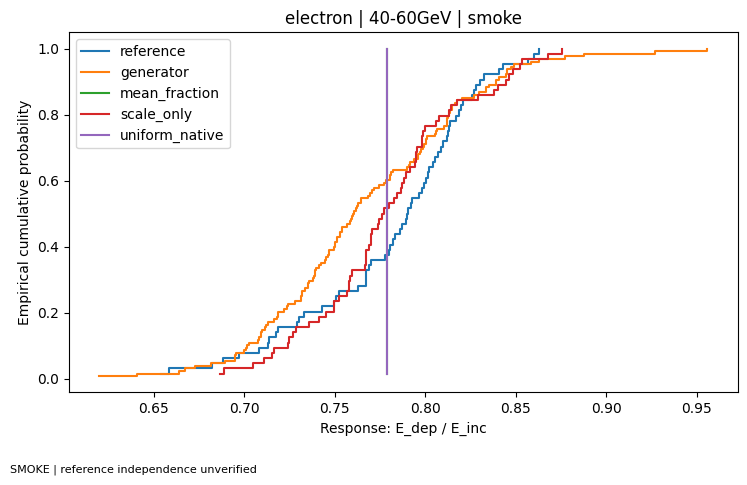

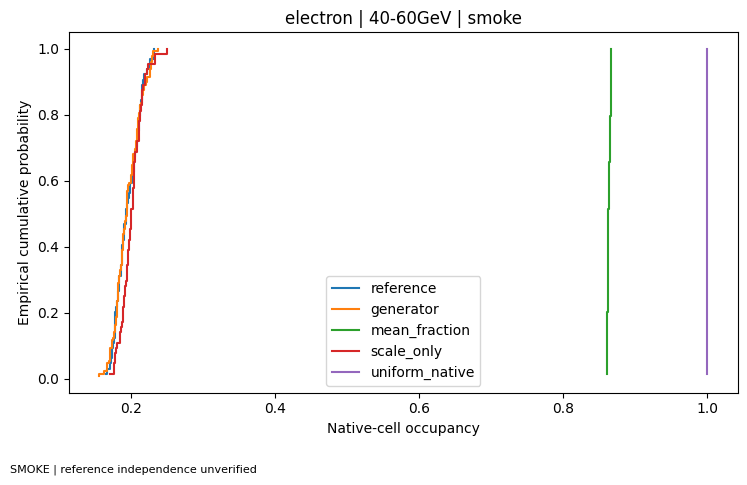

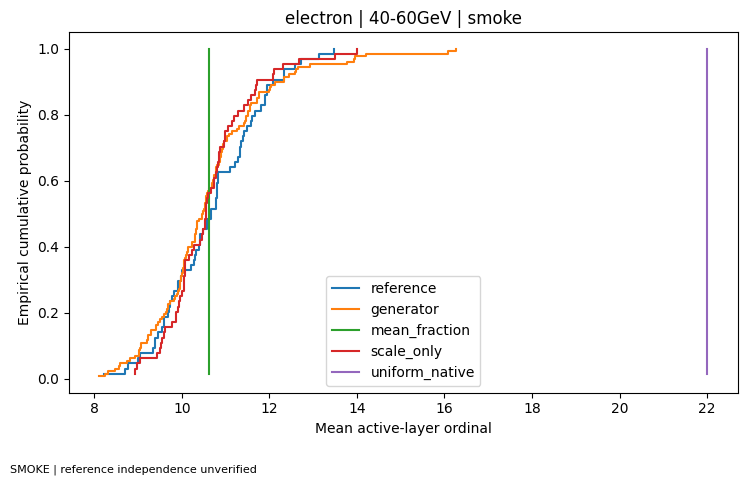

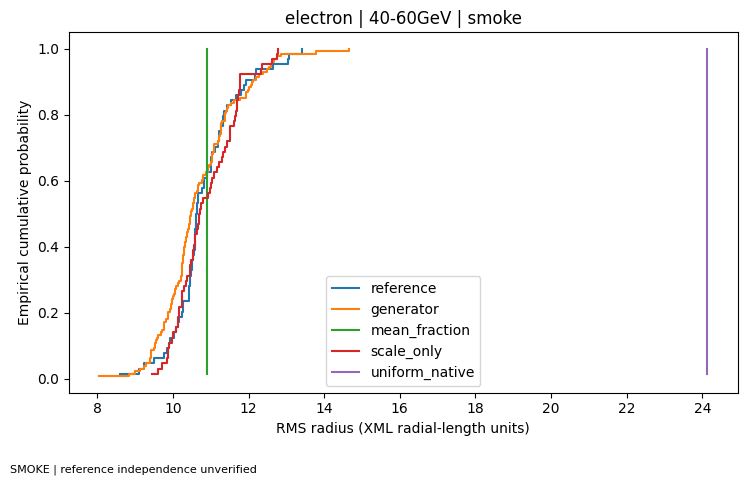

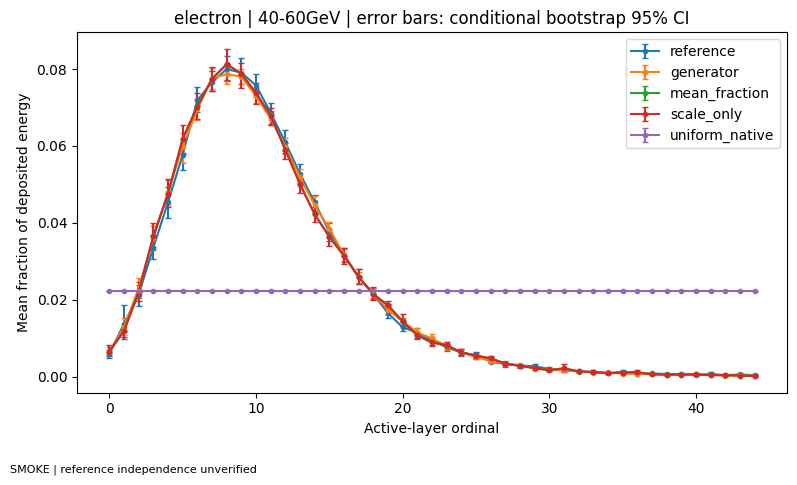

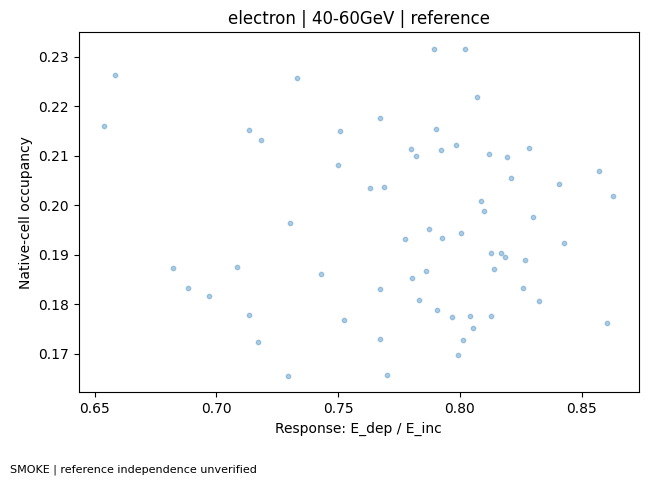

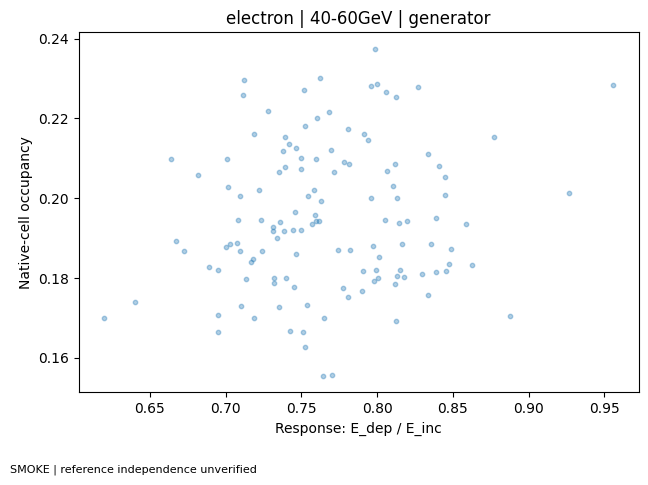

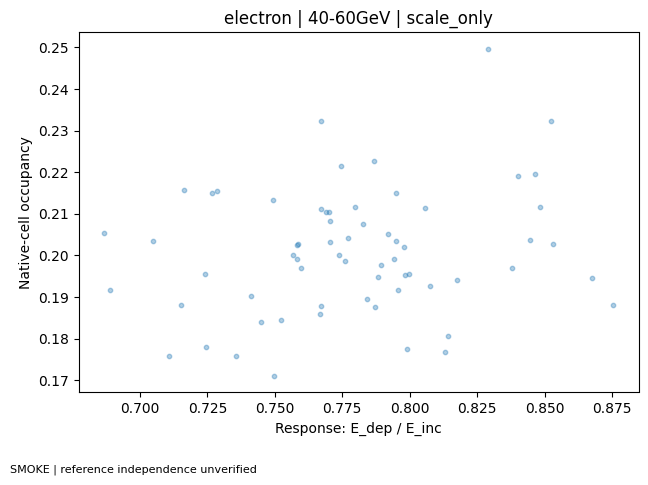

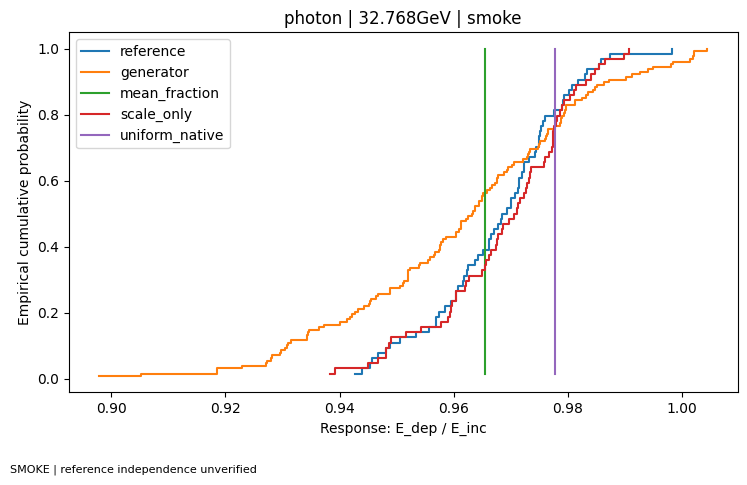

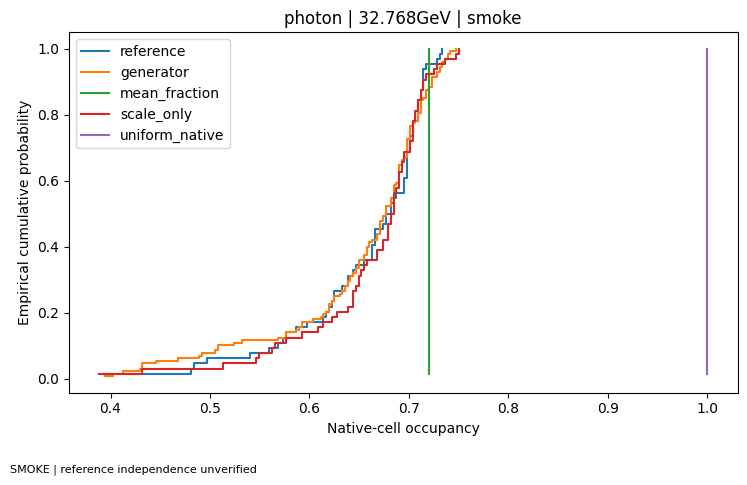

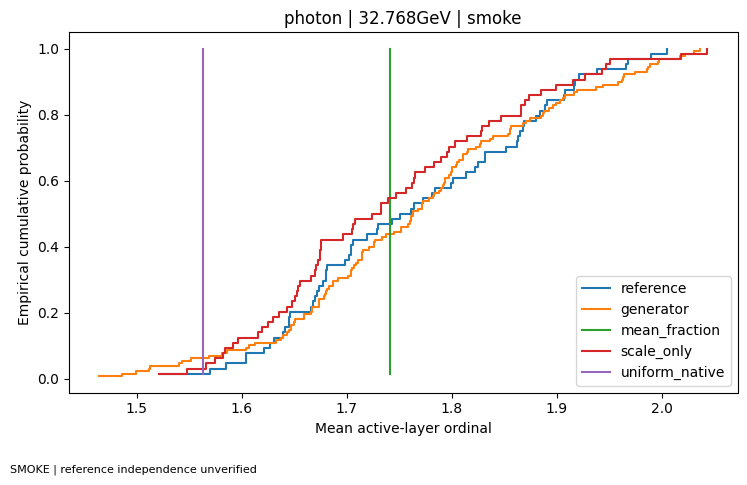

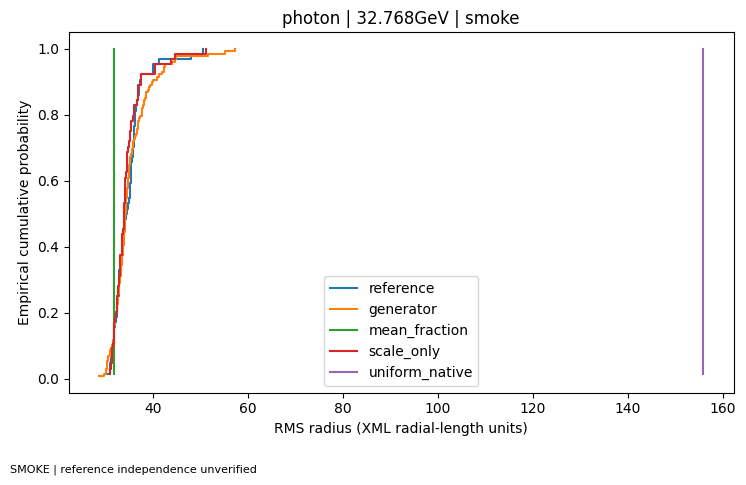

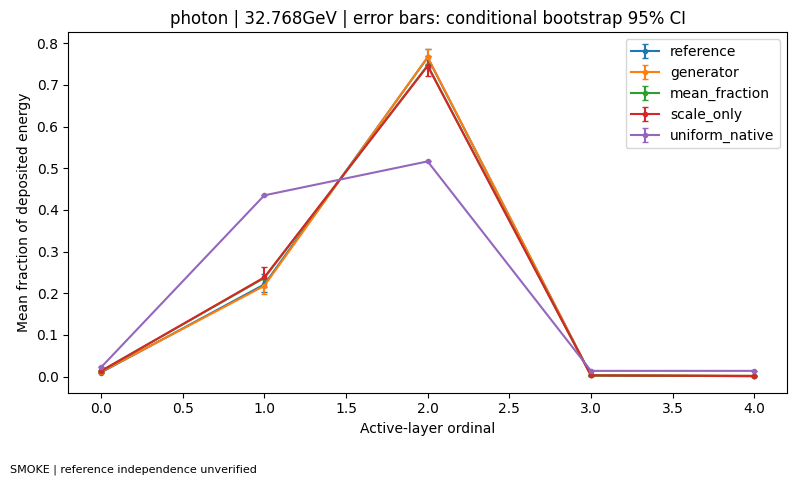

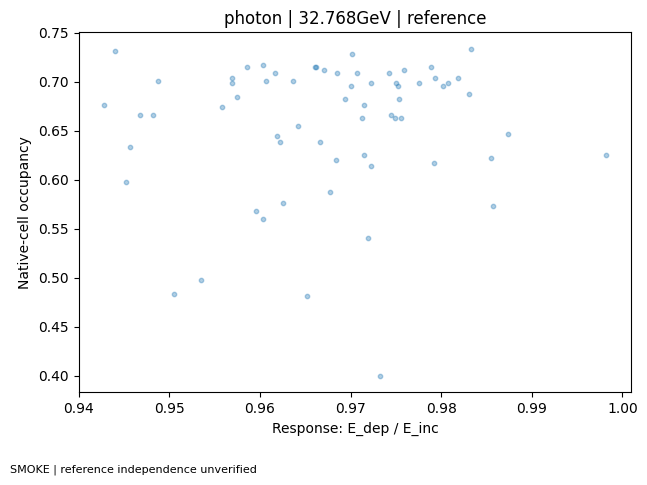

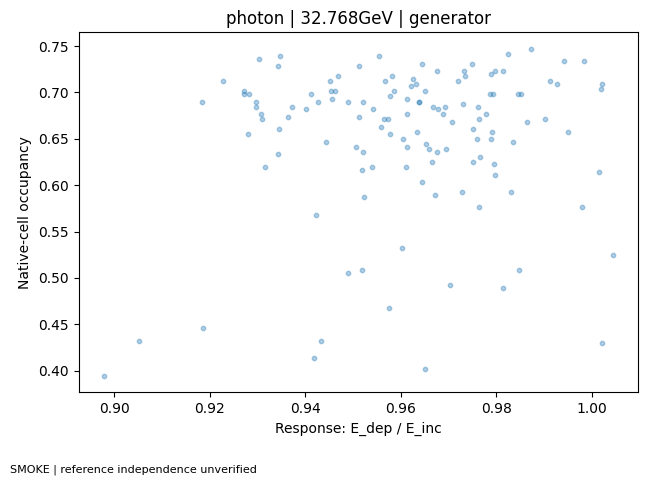

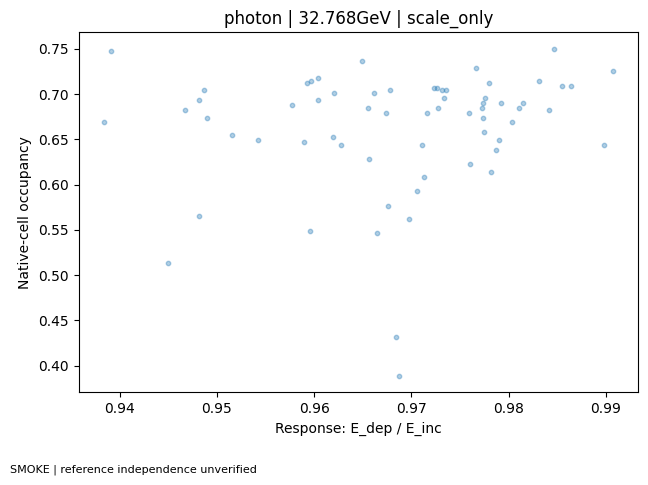

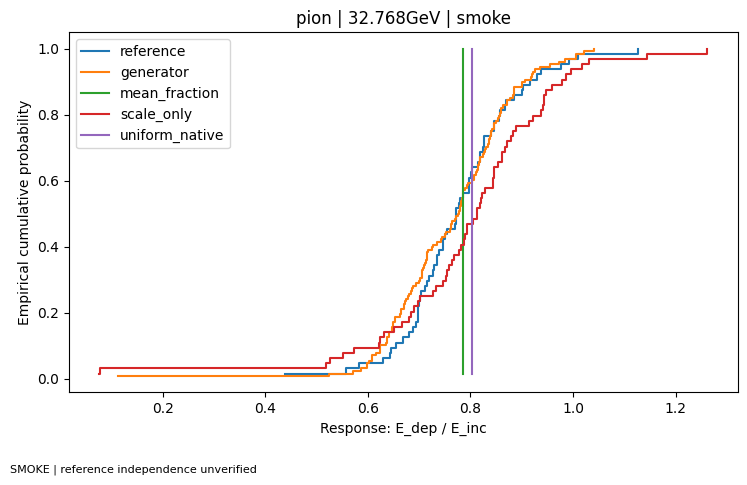

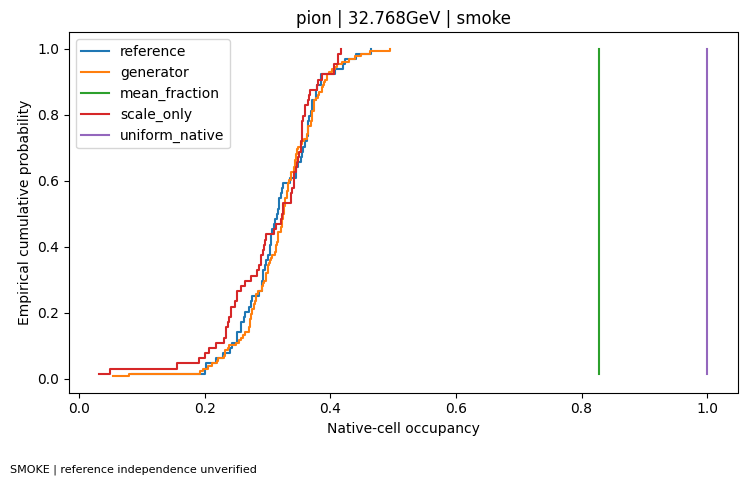

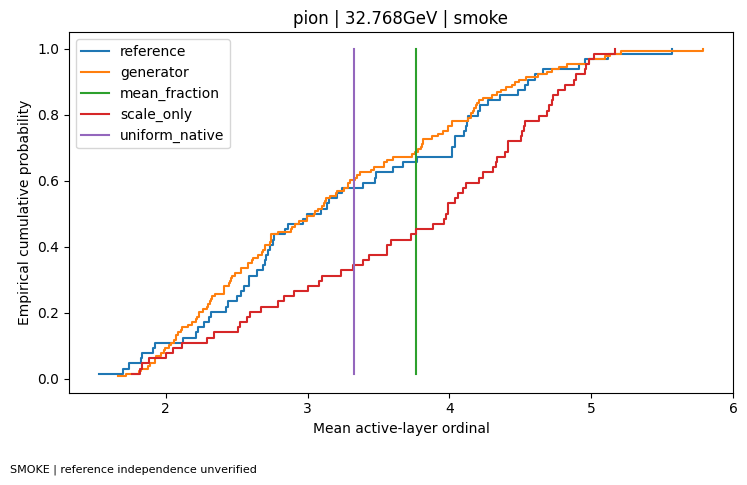

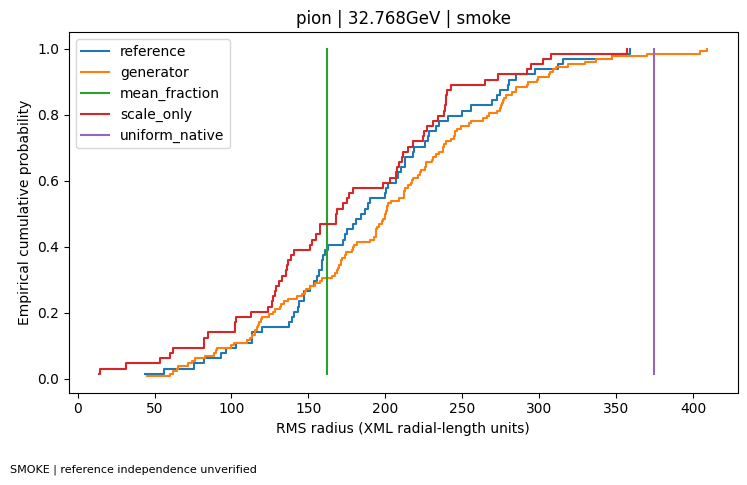

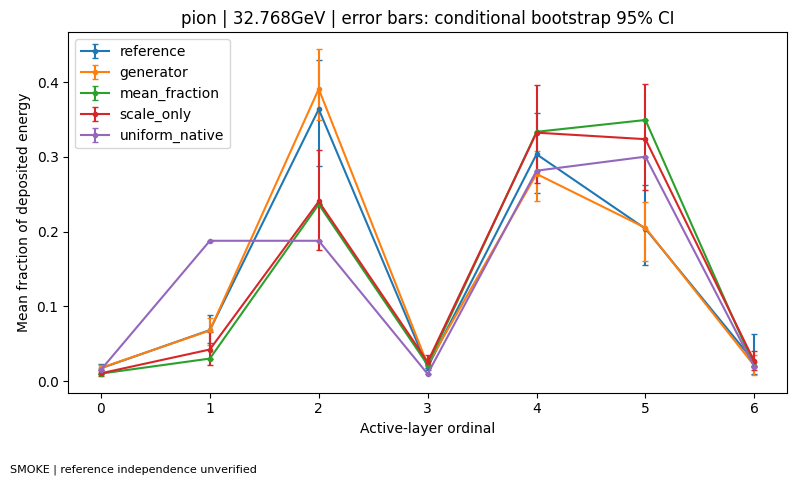

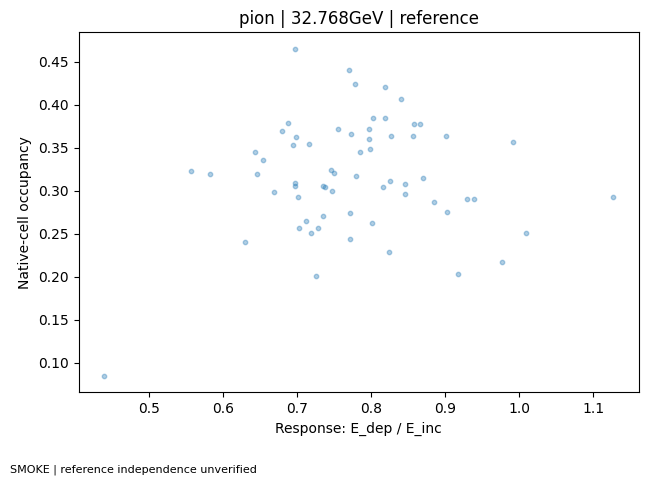

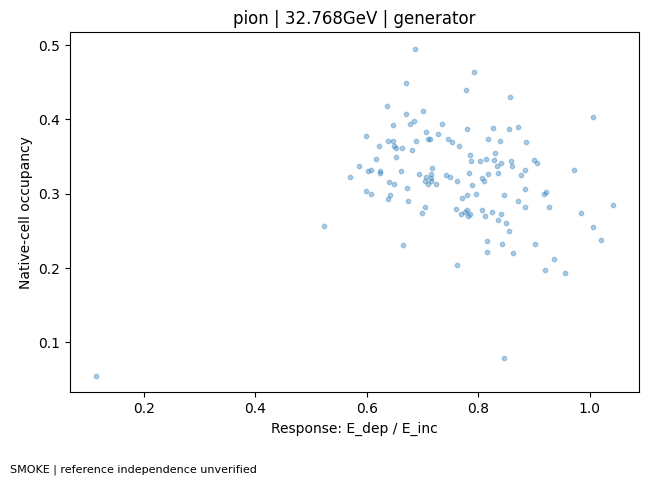

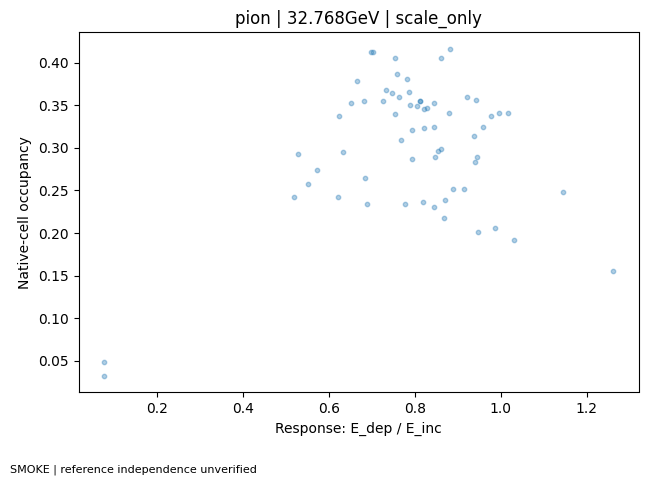

In [29]:
def plot_fidelity(particle,label,columns=('response','occupancy','depth_layer','r_rms')):
    methods=Fidelity[particle][label]
    for col in columns:
        fig,ax=plt.subplots(figsize=(7.5,4.8))
        for method,df in methods.items():
            a=np.sort(finite_values(df[col]))
            if len(a): ax.step(a,np.arange(1,len(a)+1)/len(a),where='post',label=method)
        ax.set(xlabel=LABELS.get(col,col),ylabel='Empirical cumulative probability',
               title=f'{particle} | {label} | {MODE}')
        ax.legend(); finish_figure(f'{particle}_{label}_{col}_ecdf')
    frac_cols=[f'layer_fraction_{j}' for j in range(GEOMETRY[particle].n_layers)]
    fig,ax=plt.subplots(figsize=(8,4.8))
    for method,df in methods.items():
        a=df[frac_cols].to_numpy(); good=np.isfinite(a).all(axis=1); a=a[good]
        if not len(a): continue
        mean=a.mean(axis=0);clean=df.loc[good].reset_index(drop=True)
        rng=np.random.default_rng(named_seed('layer_ci',particle,label,method))
        draws=np.array([a[resample_rows(clean,rng)].mean(axis=0) for _ in range(CFG.n_bootstrap)])
        lo,hi=np.quantile(draws,[.025,.975],axis=0)
        ax.errorbar(np.arange(a.shape[1]),mean,yerr=np.maximum(np.vstack([mean-lo,hi-mean]),0),label=method,marker='.',capsize=2)
    ax.set(xlabel='Active-layer ordinal',ylabel='Mean fraction of deposited energy',
           title=f'{particle} | {label} | error bars: conditional bootstrap 95% CI')
    ax.legend(); finish_figure(f'{particle}_{label}_layer_fractions')
    for method in ('reference','generator','scale_only'):
        df=methods[method]
        fig,ax=plt.subplots(figsize=(6.5,4.8))
        ax.scatter(df['response'],df['occupancy'],s=10,alpha=.35)
        ax.set(xlabel=LABELS['response'],ylabel=LABELS['occupancy'],title=f'{particle} | {label} | {method}')
        finish_figure(f'{particle}_{label}_{method}_response_vs_occupancy')

# Plot one selected stratum first; all strata's numbers are already saved.
for p in PARTICLES: plot_fidelity(p,STRATA[p][1].label)

In [30]:
colab_backup("fidelity")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_fidelity_20261019T153207593332Z.zip (12.09 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_fidelity_20261019T153207593332Z.zip')

In [31]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Optional high-level classifier diagnostic—not the official classifier
A classifier can detect joint discrepancies missed by single-observable plots. Features here are
response, shape, layer fractions, and the known incident energy. Its architecture is fixed in code;
no checkpoint selection or tuning uses the classifier test set. Reference and generated examples
that share a target condition ID remain in the same partition, including all generator repeats.

This diagnostic partitions the study's test pool again for discriminator training/validation/test;
only the last partition determines its final AUC. No generator weights are trained on those rows.
The AUC is compared with a label-permutation control. AUC near 0.5 is not a proof of equality:
this classifier has limited features and statistical power. Its result is not directly comparable
to the published CaloChallenge AUC/FPD/KPD. Missing-feature indicators are included rather than
silently dropping empty showers. The interval resamples target-ID clusters in the held-out portion.

In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

def classifier_test(particle):
    pairs=[]
    for label,methods in Fidelity[particle].items():
        for method,target in [('reference',0),('generator',1)]:
            df=methods[method].copy(); df['class_label']=target; pairs.append(df)
    data=pd.concat(pairs,ignore_index=True)
    columns=['response','occupancy','depth_layer','r_rms','r_sigma'] + [
        f'layer_fraction_{j}' for j in range(GEOMETRY[particle].n_layers)]
    data['log_energy']=np.log(data['energy_GeV']); columns=['log_energy']+columns
    split_map={}
    rng=np.random.default_rng(named_seed('classifier_split',particle))
    for label,g in data.groupby('stratum'):
        ids=rng.permutation(g['target_id'].unique()); a=int(.6*len(ids)); b=int(.8*len(ids))
        if min(a,b-a,len(ids)-b)<4: raise ValueError('Too few independent target IDs for classifier train/validation/test.')
        for name,sub in [('train',ids[:a]),('validation',ids[a:b]),('test',ids[b:])]:
            split_map.update({k:name for k in sub})
    data['partition']=data['target_id'].map(split_map)
    X=data[columns].replace([np.inf,-np.inf],np.nan).to_numpy(); y=data['class_label'].to_numpy()
    train=data['partition'].eq('train').to_numpy(); val=data['partition'].eq('validation').to_numpy(); test=data['partition'].eq('test').to_numpy()
    def fit_score(labels):
        clf=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
            HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,l2_regularization=1.,
                early_stopping=False,random_state=named_seed('classifier',particle)))
        counts=np.bincount(labels[train],minlength=2)
        weight=np.array([len(labels[train])/(2*counts[v]) for v in labels[train]])
        clf.fit(X[train],labels[train],histgradientboostingclassifier__sample_weight=weight)
        return clf,clf.predict_proba(X)[:,1]
    clf,score=fit_score(y)
    auc=roc_auc_score(y[test],score[test]); val_auc=roc_auc_score(y[val],score[val])
    keys=data.loc[test,'target_id'].to_numpy(); ytest=y[test]; stest=score[test]
    groups=[np.flatnonzero(keys==k) for k in np.unique(keys)]; draws=[]
    for _ in range(CFG.n_bootstrap):
        inds=np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
        if len(np.unique(ytest[inds]))==2: draws.append(roc_auc_score(ytest[inds],stest[inds]))
    lo,hi=np.quantile(draws,[.025,.975])
    shuffled=y.copy()
    for name in ('train','validation','test'):
        mask=data['partition'].eq(name).to_numpy(); shuffled[mask]=rng.permutation(shuffled[mask])
    _,null_score=fit_score(shuffled)
    null_auc=roc_auc_score(shuffled[test],null_score[test])
    report=dict(particle=particle,validation_auc=val_auc,test_auc=auc,auc_lo=lo,auc_hi=hi,
                shuffled_label_test_auc=null_auc,features=columns,n_test_rows=int(test.sum()),
                n_test_condition_clusters=len(groups))
    data['score']=score
    data[['event_id','target_id','partition','class_label','score']].to_csv(
        OUT/'tables'/f'{particle}_classifier_predictions.csv',index=False)
    save_json(OUT/f'{particle}_high_level_classifier.json',report)
    return report

if RUN_HIGH_LEVEL_CLASSIFIER:
    CLASSIFIER_REPORTS=[classifier_test(p) for p in PARTICLES]
    display(pd.DataFrame(CLASSIFIER_REPORTS).drop(columns='features'))
else:
    CLASSIFIER_REPORTS=[]

,particle,validation_auc,test_auc,auc_lo,auc_hi,shuffled_label_test_auc,n_test_rows,n_test_condition_clusters
0,electron,0.585470,0.560815,0.456895,0.689645,0.461210,117,39
1,photon,0.505917,0.568705,0.486818,0.660084,0.424721,117,39
2,pion,0.486522,0.512821,0.424417,0.624564,0.510848,117,39


In [33]:
colab_backup("classifier")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_classifier_20261019T153349085442Z.zip (12.13 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_classifier_20261019T153349085442Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Does the correct energy condition help held-out denoising?
Encode reference showers using their **true** energies and the original preprocessing. For each
timestep, add a known noise tensor and compare the noise-prediction error under (a) the correct
energy, and (b) energies taken from other selected strata. The noisy shower, noise realization,
and preprocessing energy remain identical across the two calls. There is no GeV decoder in this test.

`t=0` is excluded: the inspected upstream `noise_image` special-cases it by returning clean data,
which would make a naive noise-target comparison misleading. Timesteps are homogeneous in a batch,
avoiding its `t[0]` special-case ambiguity. This measures condition usefulness for the implemented
denoising task, not physical generation under a deliberately wrong condition.

Repeated noises are averaged **within each event** before confidence intervals; adjacent rows are
not treated as independent showers. A nonzero prediction change and a positive error penalty are
distinct outputs. A weak effect at one timestep does not establish that the network ignores energy.

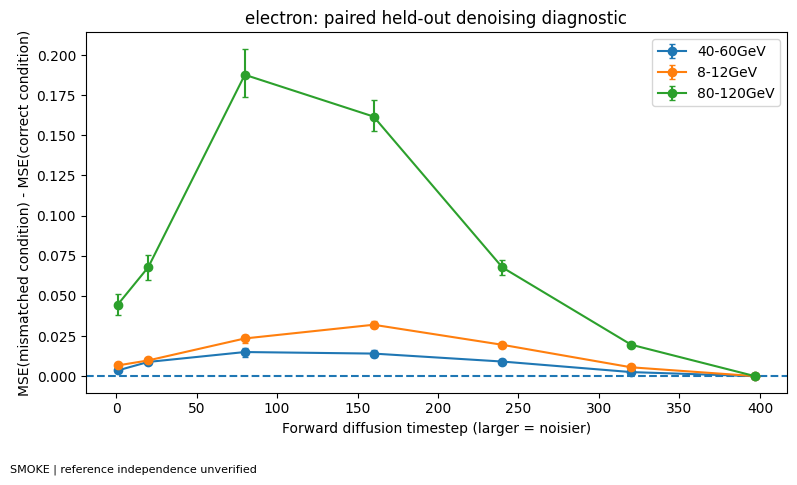

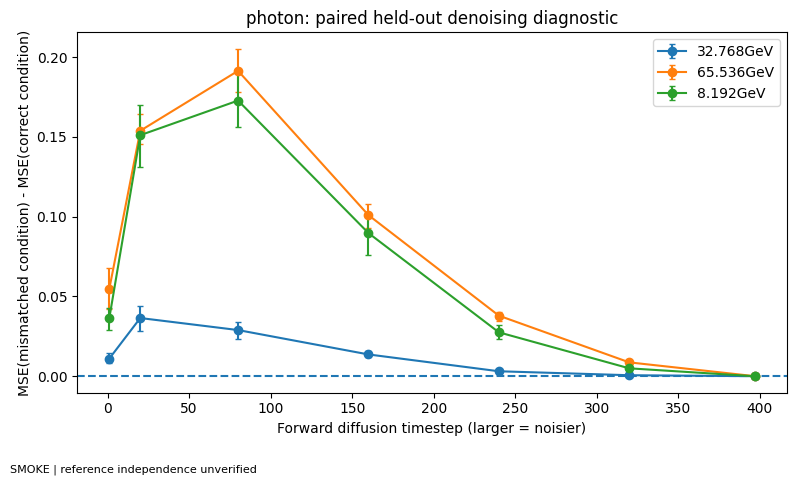

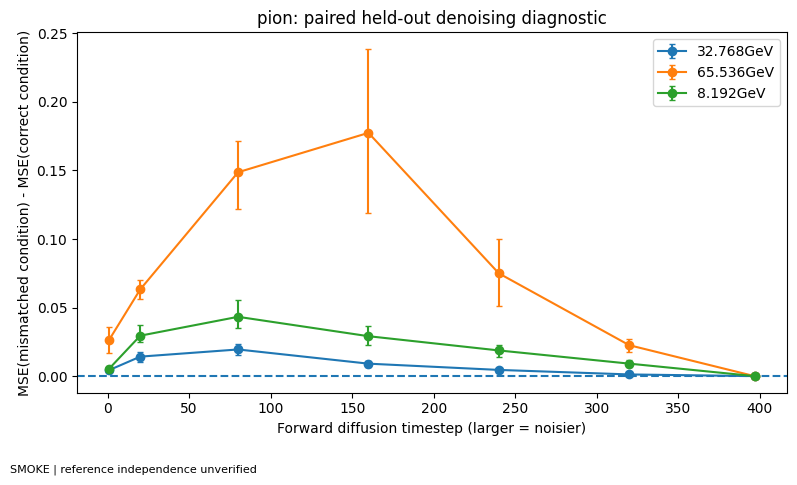

In [34]:
def conditioning_denoising_test(particle):
    model=get_model(particle); n=CFG.noise_test_events_per_bin
    if n>CFG.n_pilot: raise ValueError('Increase pilot events or reduce noise_test_events_per_bin.')
    batches=[read_events(REFERENCES[particle],s.partitions['pilot'][:n]) for s in STRATA[particle]]
    raw=np.concatenate([b.native for b in batches]); true_E=np.concatenate([b.energy for b in batches])
    ids=np.concatenate([b.ids for b in batches]); labels=np.repeat([s.label for s in STRATA[particle]],n)
    rows=[]
    for repeat in range(CFG.noise_repeats):
        # Rotate complete energy strata, then randomize within each donor stratum.
        rng=np.random.default_rng(named_seed('wrong_energy',particle,repeat))
        wrong_E=np.concatenate([rng.permutation(batches[(j+1)%len(batches)].energy) for j in range(len(batches))])
        if np.any(np.isclose(wrong_E,true_E,rtol=1e-5)): raise ValueError('Condition replacement accidentally left an energy unchanged.')
        for t in CFG.noise_timesteps:
            if not 1<=t<cp.NSTEPS: raise ValueError('Denoising test requires integer 1 <= t < NSTEPS.')
            for start in range(0,len(raw),CFG.batch_size):
                stop=min(start+CFG.batch_size,len(raw)); sl=slice(start,stop)
                x=encode_native(model,raw[sl],true_E[sl])
                with rng_context(seed=named_seed('known_noise',particle,repeat,t,start)),torch.inference_mode():
                    eps=torch.randn_like(x)
                    xt,actual_eps=cp.noise_at(model,x,t=t,noise=eps)
                    pred_true=cp.predict_noise(model,xt,cp.encode_energy(particle,true_E[sl]),t=t)
                    pred_wrong=cp.predict_noise(model,xt,cp.encode_energy(particle,wrong_E[sl]),t=t)
                dims=tuple(range(1,x.ndim))
                mse_true=((pred_true-actual_eps)**2).mean(dim=dims).cpu().numpy()
                mse_wrong=((pred_wrong-actual_eps)**2).mean(dim=dims).cpu().numpy()
                pred_delta=((pred_wrong-pred_true)**2).mean(dim=dims).sqrt().cpu().numpy()
                for k,event in enumerate(ids[sl]):
                    rows.append(dict(event_id=event,stratum=labels[start+k],repeat=repeat,timestep=t,
                        true_energy=true_E[start+k],wrong_energy=wrong_E[start+k],mse_correct=mse_true[k],
                        mse_mismatched=mse_wrong[k],delta_mse=mse_wrong[k]-mse_true[k],prediction_rms_change=pred_delta[k]))
    df=pd.DataFrame(rows); df.to_csv(OUT/'tables'/f'{particle}_denoising_conditioning_events.csv',index=False)
    ev=df.groupby(['event_id','stratum','timestep'],as_index=False)[['mse_correct','mse_mismatched','delta_mse','prediction_rms_change']].mean()
    summaries=[]
    for (label,t),g in ev.groupby(['stratum','timestep']):
        mean,lo,hi=bootstrap_mean(g['delta_mse'],named_seed('denoise_ci',particle,label,t))
        summaries.append(dict(stratum=label,timestep=t,delta_mse=mean,lo=lo,hi=hi,
            mse_correct=g['mse_correct'].mean(),mse_mismatched=g['mse_mismatched'].mean(),
            prediction_rms_change=g['prediction_rms_change'].mean(),n_events=len(g)))
    summary=pd.DataFrame(summaries); summary.to_csv(OUT/'tables'/f'{particle}_denoising_conditioning_summary.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,4.8))
    for label,g in summary.groupby('stratum'):
        g=g.sort_values('timestep')
        ax.errorbar(g['timestep'],g['delta_mse'],yerr=np.maximum(np.vstack([g['delta_mse']-g['lo'],g['hi']-g['delta_mse']]),0),
                    label=label,marker='o',capsize=2)
    ax.axhline(0,linestyle='--'); ax.set(xlabel='Forward diffusion timestep (larger = noisier)',
        ylabel='MSE(mismatched condition) - MSE(correct condition)',title=f'{particle}: paired held-out denoising diagnostic')
    ax.legend(); finish_figure(f'{particle}_conditioning_denoising')
    return summary

DENOISING_SUMMARIES={p:conditioning_denoising_test(p) for p in PARTICLES}

In [35]:
colab_backup("conditioning")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_conditioning_20261019T153416477387Z.zip (12.45 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_conditioning_20261019T153416477387Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Separate the network-condition pathway from the decoder-energy pathway
The four cases are A/A, B/A, A/B, and B/B, where the first entry is the energy passed to the
denoiser and the second is the energy passed to the decoder. A/A and B/B are ordinary generation;
mixed cases are diagnostics. Both network generations use the **same initial and future random
draws** by resetting the same seed for the same batch shape.

Before thresholding, fixed latent output decoded at B should scale by B/A. After thresholding,
response and occupancy can change nonlinearly because cells cross the common cut. This expected
scaling is not a failure criterion. Report raw paired effects, not a ratio with a small A/B denominator.
This initial-condition control is less difficult to interpret than a late, large energy splice.
Defaults use the middle/high selected energies; set control_energy_pairs to test smaller changes.
Off-grid control energies are allowed for diagnostics, but are not claimed to have exact reference truth.

In [36]:
def control_pair(particle):
    A,B=CFG.control_energy_pairs.get(particle,(STRATA[particle][1].nominal,STRATA[particle][2].nominal))
    cfg=cp._cfg(particle)
    if not (cfg['EMIN']<=A<=cfg['EMAX'] and cfg['EMIN']<=B<=cfg['EMAX']) or A==B:
        raise ValueError('Control energies must be distinct and within the supported range.')
    return float(A),float(B)


def pathway_controls(particle):
    model=get_model(particle); g=GEOMETRY[particle]; ecut=model.config['ECUT']
    A,B=control_pair(particle)
    ea=np.full(CFG.control_events,A); eb=np.full(CFG.control_events,B); frames=[]; effects=[]
    for run in range(CFG.control_repeats):
        seed=named_seed('pathways',particle,run)
        za=standard_generate(model,ea,seed); zb=standard_generate(model,eb,seed)
        uncut_a=decode_native(model,za,ea,apply_cut=False)
        uncut_b=decode_native(model,za,eb,apply_cut=False)
        gate(f'{particle}: fixed-latent decode scaling run {run}',
             np.allclose(uncut_b,uncut_a*(B/A),rtol=1e-10,atol=1e-10))
        variants={}
        for tag,z,condition,decode in [('AA',za,ea,ea),('BA',zb,eb,ea),('AB',za,ea,eb),('BB',zb,eb,eb)]:
            obs=native_observables(decode_native(model,z,decode),decode,g,ecut)
            # In diagnostic mixed cases, response's denominator is the DECODE energy; expose both.
            obs['network_energy_GeV']=condition; obs['decode_energy_GeV']=decode
            obs['case']=tag; obs['run']=run; obs['event']=np.arange(len(decode))
            variants[tag]=obs; frames.append(obs)
        for contrast,left,right in [('network_at_A','BA','AA'),('decode_at_A','AB','AA'),
                                    ('combined','BB','AA'),('network_at_B','BB','AB')]:
            for col in OBSERVABLES:
                delta=variants[left][col].to_numpy()-variants[right][col].to_numpy()
                effects.extend(dict(run=run,event=i,contrast=contrast,observable=col,delta=v) for i,v in enumerate(delta))
    data=pd.concat(frames,ignore_index=True); effect=pd.DataFrame(effects)
    data.to_csv(OUT/'tables'/f'{particle}_energy_pathway_cases.csv',index=False)
    effect.to_csv(OUT/'tables'/f'{particle}_energy_pathway_paired_effects.csv',index=False)
    rows=[]
    for (contrast,col),x in effect.groupby(['contrast','observable']):
        mean,lo,hi=bootstrap_mean(x['delta'],named_seed('pathways_ci',particle,contrast,col))
        rows.append(dict(contrast=contrast,observable=col,mean_effect=mean,lo=lo,hi=hi))
    summary=pd.DataFrame(rows);summary.to_csv(OUT/'tables'/f'{particle}_energy_pathway_summary.csv',index=False)
    return summary

PATHWAY_SUMMARIES={p:pathway_controls(p) for p in PARTICLES}
for p,df in PATHWAY_SUMMARIES.items(): display(df.query("observable in ['deposited_GeV','response','occupancy']"))

,contrast,observable,mean_effect,lo,hi
0,combined,deposited_GeV,3.767055e+01,3.710472e+01,3.851249e+01
2,combined,occupancy,9.973958e-02,9.636164e-02,1.036244e-01
5,combined,response,1.089020e-03,-6.515991e-03,1.149790e-02
6,decode_at_A,deposited_GeV,3.756386e+01,3.637342e+01,3.859296e+01
8,decode_at_A,occupancy,7.716049e-05,3.351659e-05,1.253858e-04
11,decode_at_A,response,1.233253e-07,5.401738e-08,1.850523e-07
12,network_at_A,deposited_GeV,5.331867e-02,-3.737669e-01,4.654297e-01
14,network_at_A,occupancy,9.929591e-02,9.609375e-02,1.026326e-01
17,network_at_A,response,1.088363e-03,-5.868034e-03,9.294010e-03
18,network_at_B,deposited_GeV,1.066897e-01,-6.367678e-01,1.017791e+00


,contrast,observable,mean_effect,lo,hi
0,combined,deposited_GeV,31.874978,31.641489,32.246044
2,combined,occupancy,0.076766,0.069608,0.083148
5,combined,response,0.004589,0.001324,0.008725
6,decode_at_A,deposited_GeV,31.979669,31.659199,32.261107
8,decode_at_A,occupancy,0.074728,0.068954,0.080358
11,decode_at_A,response,0.006187,0.005632,0.006787
12,network_at_A,deposited_GeV,-0.079874,-0.185342,0.041092
14,network_at_A,occupancy,-0.009341,-0.019451,-0.002458
17,network_at_A,response,-0.002438,-0.005388,0.000646
18,network_at_B,deposited_GeV,-0.104691,-0.362181,0.157902


,contrast,observable,mean_effect,lo,hi
0,combined,deposited_GeV,28.037600,25.312747,31.608194
2,combined,occupancy,0.148335,0.123086,0.167824
5,combined,response,0.031545,-0.000803,0.067359
6,decode_at_A,deposited_GeV,26.426711,24.703647,28.514642
8,decode_at_A,occupancy,0.058865,0.049165,0.069609
11,decode_at_A,response,0.006964,0.005535,0.008048
12,network_at_A,deposited_GeV,0.766990,-0.128987,1.898477
14,network_at_A,occupancy,0.079386,0.063130,0.097936
17,network_at_A,response,0.023407,-0.005789,0.050758
18,network_at_B,deposited_GeV,1.610890,-0.394997,3.153946


In [37]:
colab_backup("energy_pathways")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_energy_pathways_20261019T153652226018Z.zip (12.53 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_energy_pathways_20261019T153652226018Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Emergence: what stabilizes, for which individual shower?
Inspect the physical observables of each clean estimate `xhat_0`, not the noisy state `x_t`.
The tracer labels both frame and actual diffusion timestep. Each event is compared with its own
eventual **standard-sampler output**. Population-median curves are also shown, but are not called
individual lock-in. Response and deposited energy at fixed incident energy are not independent tests.

A scalar is within tolerance when `abs(current - final) <= atol + rtol*abs(final)`. All subsequent
measured frames must remain in that band. Nonfinite curves are invalid; a crossing too close to the
endpoint has insufficient follow-up and is reported as such. Tolerance scans are descriptive
robustness checks, not opportunities to choose the most attractive ordering.

The trajectory/reference W1 curve is a **separate** comparison, using the pilot reference showers
whose energies were supplied to these generations. It measures fidelity along the trajectory;
convergence toward the generator's own endpoint cannot substitute for that comparison.

For the electron, normalized angular modes `|A_m|/A_0` are tracked alongside—not equated to—depth
and occupancy. The FFT is angular, and `A_0` is total energy. Layer fractions characterize longitudinal
shape. No intermediate state is interpreted as a physical stage of particle transport.

In [38]:
def sustained_lock(values, target, rtol, atol, min_tail=5):
    a=np.asarray(values,dtype=float)
    if a.ndim!=1 or len(a)==0 or not np.isfinite(a).all() or not np.isfinite(target):
        return np.nan,'invalid'
    if rtol<0 or atol<0 or min_tail<1: raise ValueError('Invalid tolerance/min_tail.')
    bad=np.flatnonzero(np.abs(a-target) > atol+rtol*abs(target))
    start=int(bad[-1]+1) if len(bad) else 0
    if start>=len(a): return np.nan,'not_observed'
    if len(a)-start<min_tail: return np.nan,'insufficient_tail'
    return float(start),'observed'


def observable_atol(column, energy, geom):
    # Prespecified floors: occupancy gets one native voxel; layer/radius have labeled units.
    if column=='deposited_GeV': return 0.005*energy
    if column=='response': return 0.005
    if column=='occupancy': return 1.0/geom.n_voxels
    if column=='depth_layer': return 0.05
    if column in ('r_rms','r_sigma'): return 0.001*float(geom.radius.max())
    if column.startswith('angular_'): return 0.005
    return 1e-5

EMERGENCE, EMERGENCE_FINALS, EMERGENCE_REFERENCE, FEATURE_BANK = {}, {}, {}, {}
LOCK_ROWS, STEP_DISTANCE_ROWS = [], []
for particle in PARTICLES:
    model=get_model(particle); geom=GEOMETRY[particle]; ecut=model.config['ECUT']; s=STRATA[particle][1]
    total_needed=CFG.trace_events_per_run*CFG.trace_runs
    if total_needed>CFG.n_pilot:
        raise ValueError('Increase n_pilot or reduce trace events/runs; emergence uses disjoint pilot conditions.')
    all_traces, finals, matched_refs, features=[],[],[],[]
    cols=OBSERVABLES + (['angular_m1','angular_m4'] if particle=='electron' else [])
    for run in range(CFG.trace_runs):
        start=run*CFG.trace_events_per_run; idx=s.partitions['pilot'][start:start+CFG.trace_events_per_run]
        ref=read_events(REFERENCES[particle],idx)
        trace=traced_generate(model,ref.energy,named_seed('emergence',particle,run),
            snapshot_counts=(),capture_features=RUN_OPTIONAL_REPRESENTATION_DIAGNOSTICS)
        obs=trace.observables.copy(); obs['run']=run
        event_ids=np.array([f'trace:{particle}:{run}:{j}' for j in range(len(ref.energy))])
        obs['event_id']=event_ids[obs['event_in_batch'].to_numpy()]
        obs['target_id']=ref.ids[obs['event_in_batch'].to_numpy()]
        final=native_observables(decode_native(model,trace.final,ref.energy),ref.energy,geom,ecut)
        final['event_id']=event_ids; final['target_id']=ref.ids; final['run']=run
        truth=native_observables(ref.native,ref.energy,geom,ecut)
        truth['target_id']=ref.ids; truth['run']=run
        all_traces.append(obs); finals.append(final); matched_refs.append(truth)
        arr=obs[cols].to_numpy().reshape(len(trace.times),len(ref.energy),len(cols))
        content=dict(times=trace.times,observables=np.array(cols),values=arr,energy=ref.energy,
            event_id=event_ids,target_id=ref.ids,native_final=decode_native(model,trace.final,ref.energy))
        if trace.features is not None:
            content['features']=trace.features; features.append(trace.features)
        np.savez_compressed(OUT/'arrays'/f'{particle}_emergence_run{run}.npz',**content)
        for j in range(len(ref.energy)):
            for ci,col in enumerate(cols):
                for rtol in CFG.emerge_rel_tolerances:
                    atol=observable_atol(col,ref.energy[j],geom)
                    frame,status=sustained_lock(arr[:,j,ci],float(final.iloc[j][col]),rtol,atol,min_tail=5)
                    LOCK_ROWS.append(dict(particle=particle,run=run,event_id=event_ids[j],observable=col,
                        rtol=rtol,atol=atol,lock_frame=frame,
                        completed_updates=frame+1 if np.isfinite(frame) else np.nan,
                        timestep=trace.times[int(frame)] if np.isfinite(frame) else np.nan,status=status))
        # Layer-fraction total variation gives a shape-level measure beyond a single depth scalar.
        layer_cols=[f'layer_fraction_{i}' for i in range(geom.n_layers)]
        la=obs[layer_cols].to_numpy().reshape(len(trace.times),len(ref.energy),geom.n_layers)
        lf=final[layer_cols].to_numpy()
        tv=.5*np.abs(la-lf[None,:,:]).sum(axis=2)
        np.savez_compressed(OUT/'arrays'/f'{particle}_layer_shape_emergence_run{run}.npz',
                            total_variation_to_final=tv,event_id=event_ids,times=trace.times)
    EMERGENCE[particle]=pd.concat(all_traces,ignore_index=True)
    EMERGENCE_FINALS[particle]=pd.concat(finals,ignore_index=True)
    EMERGENCE_REFERENCE[particle]=pd.concat(matched_refs,ignore_index=True)
    if features: FEATURE_BANK[particle]=np.concatenate(features,axis=1)
    EMERGENCE[particle].to_csv(OUT/'tables'/f'{particle}_emergence_events.csv.gz',index=False,compression='gzip')
    for frame,g in EMERGENCE[particle].groupby('frame',sort=True):
        for col in cols:
            a,b=finite_values(EMERGENCE_REFERENCE[particle][col]),finite_values(g[col])
            STEP_DISTANCE_ROWS.append(dict(particle=particle,frame=int(frame),timestep=int(g['timestep'].iloc[0]),observable=col,
                w1_to_matched_reference=stats.wasserstein_distance(a,b) if len(a) and len(b) else np.nan,
                nonfinite_count=int((~np.isfinite(g[col])).sum())))

LOCKS=pd.DataFrame(LOCK_ROWS); STEP_DISTANCES=pd.DataFrame(STEP_DISTANCE_ROWS)
LOCKS.to_csv(OUT/'tables'/'event_lockins_tolerance_scan.csv',index=False)
STEP_DISTANCES.to_csv(OUT/'tables'/'trajectory_reference_distances.csv',index=False)
LOCK_SUMMARY=LOCKS.groupby(['particle','observable','rtol'],as_index=False).agg(
    median_completed_updates=('completed_updates','median'),
    q10=('completed_updates',lambda a:a.quantile(.1)),q90=('completed_updates',lambda a:a.quantile(.9)),
    n_observed=('status',lambda a:int((a=='observed').sum())),n_total=('status','size'))
LOCK_SUMMARY.to_csv(OUT/'tables'/'event_lockin_summary.csv',index=False)
display(LOCK_SUMMARY.query('rtol == 0.1'))

,particle,observable,rtol,median_completed_updates,q10,q90,n_observed,n_total
1,electron,angular_m1,0.1,366.0,331.5,379.5,16,16
4,electron,angular_m4,0.1,363.5,342.0,386.0,16,16
7,electron,deposited_GeV,0.1,307.0,286.5,319.5,16,16
10,electron,depth_layer,0.1,112.0,70.5,143.0,16,16
13,electron,occupancy,0.1,304.0,300.0,311.5,16,16
16,electron,r_rms,0.1,250.5,228.0,262.5,16,16
19,electron,r_sigma,0.1,238.5,221.0,257.0,16,16
22,electron,response,0.1,307.0,286.5,319.5,16,16
25,photon,deposited_GeV,0.1,263.0,250.5,299.0,16,16
28,photon,depth_layer,0.1,5.5,3.0,19.5,16,16


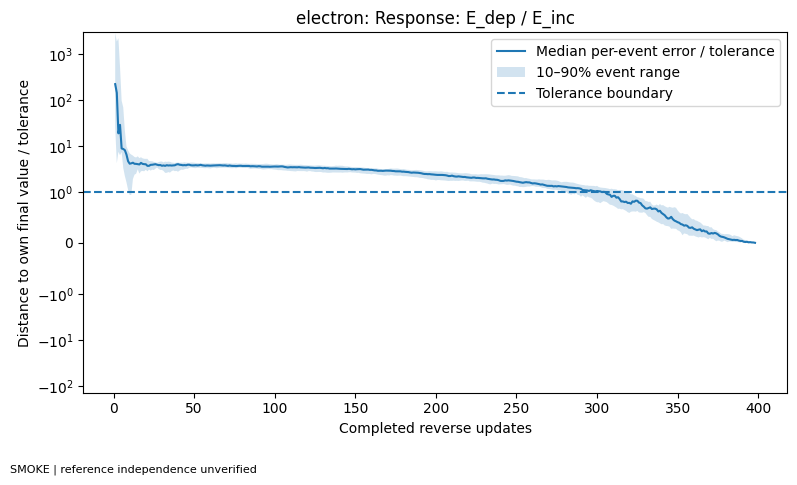

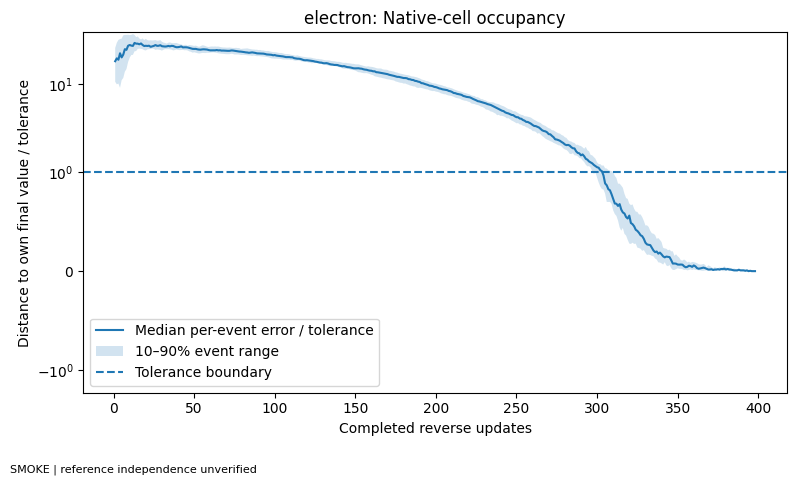

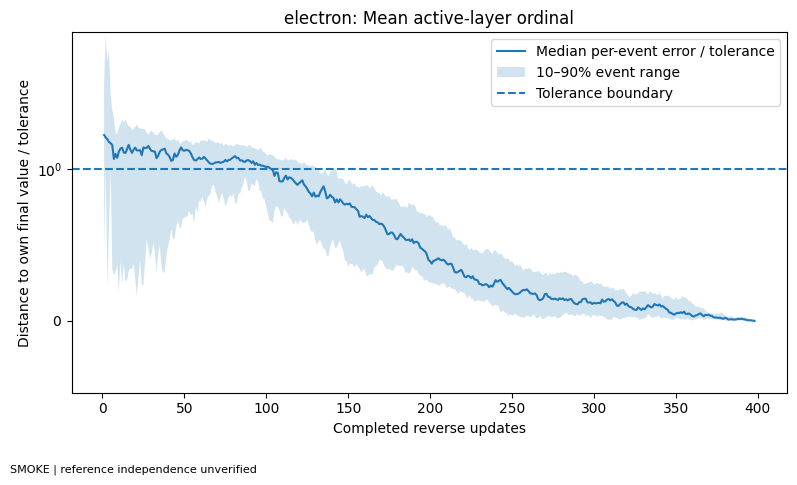

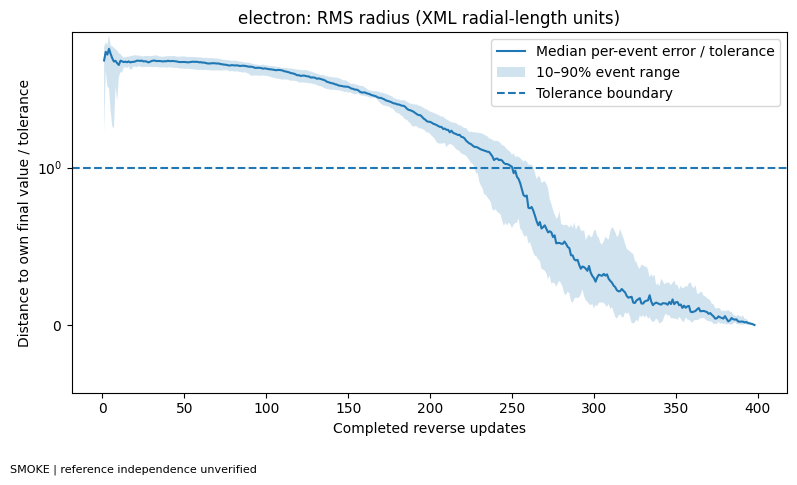

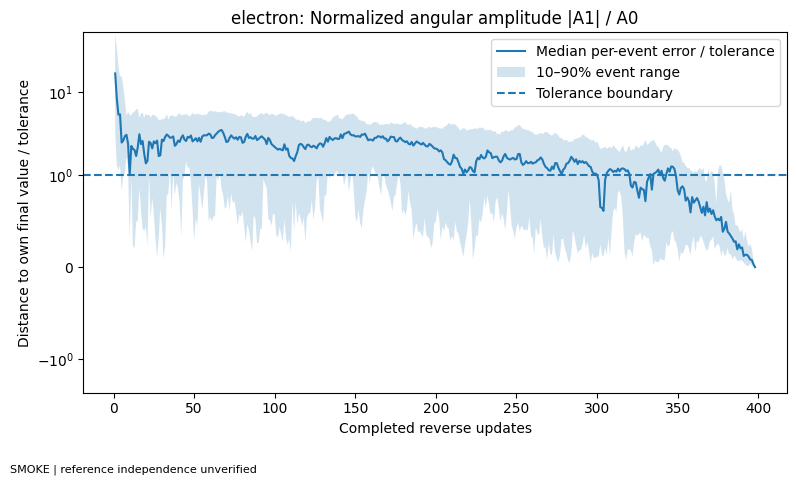

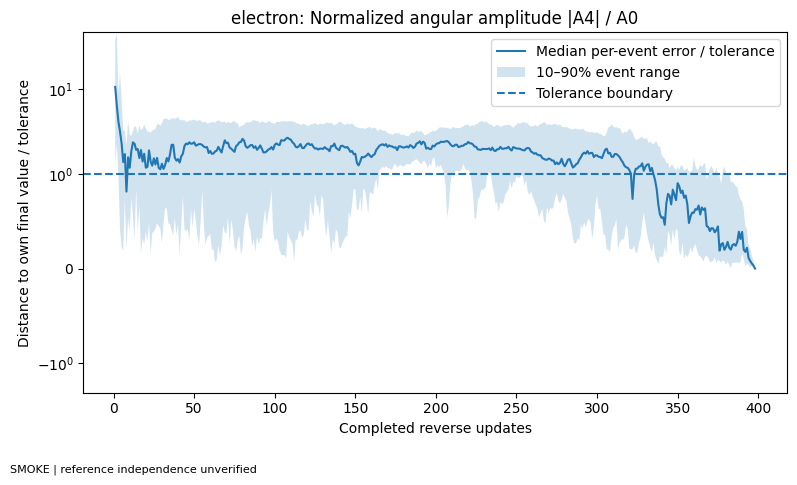

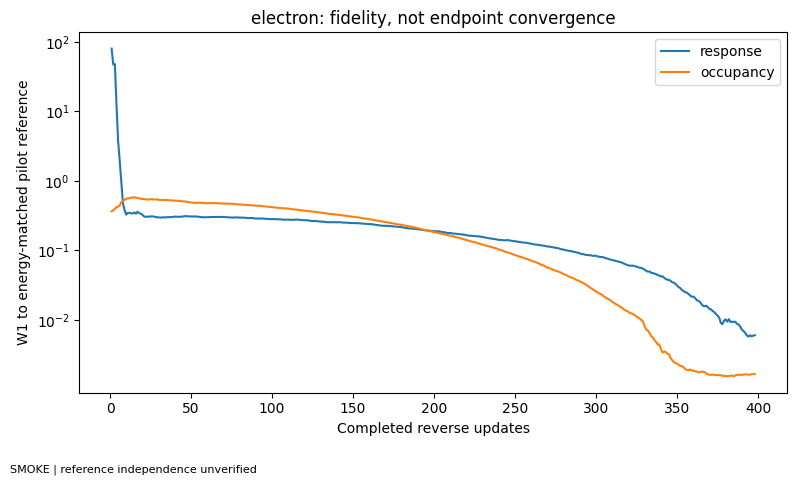

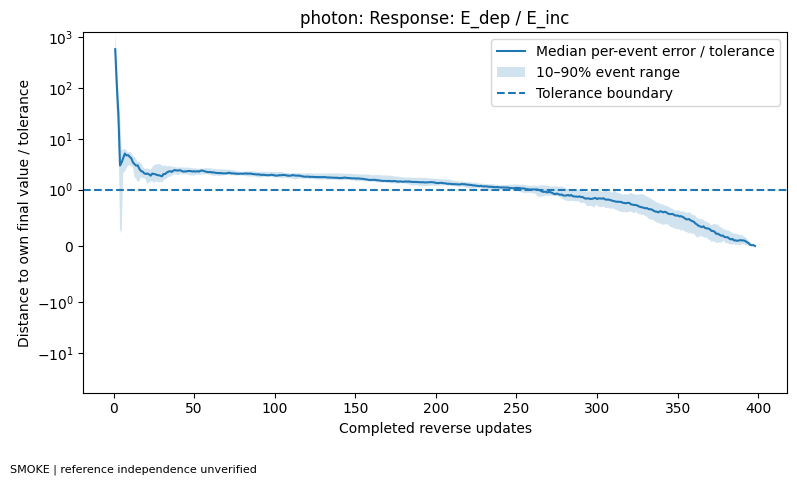

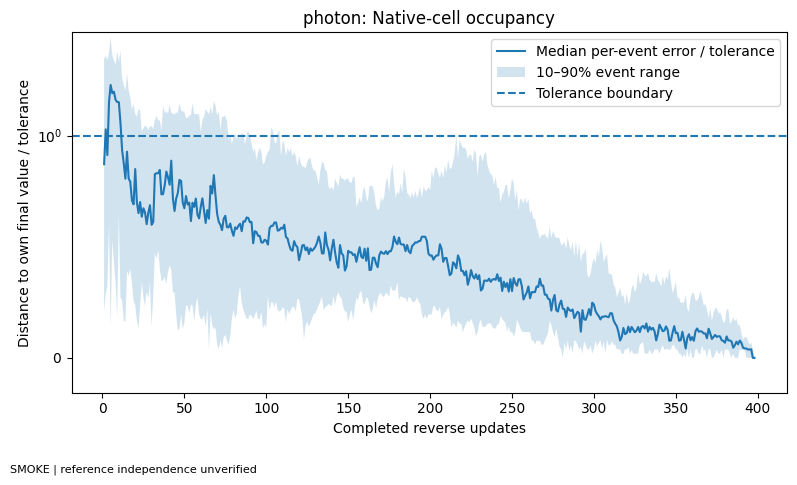

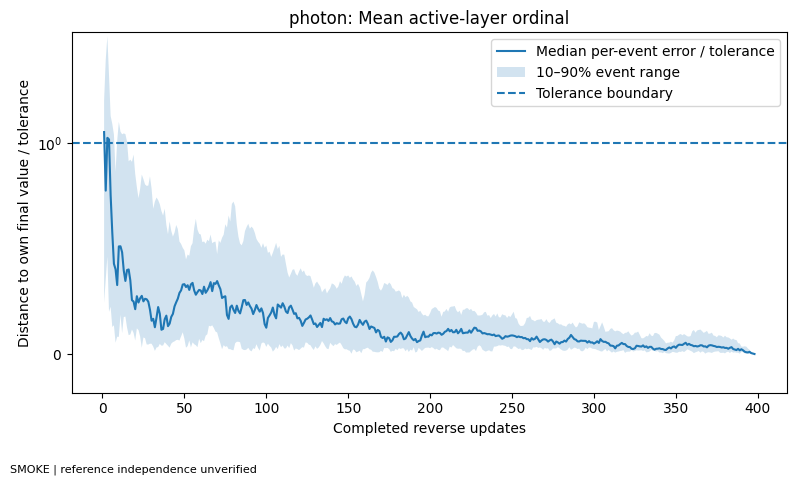

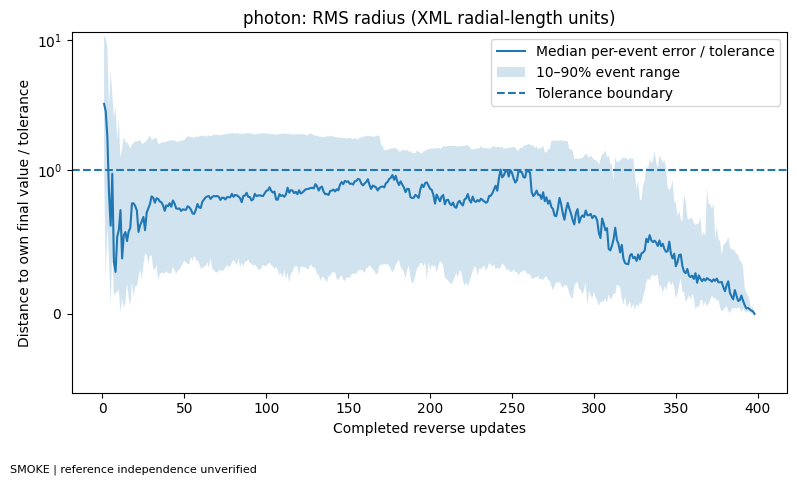

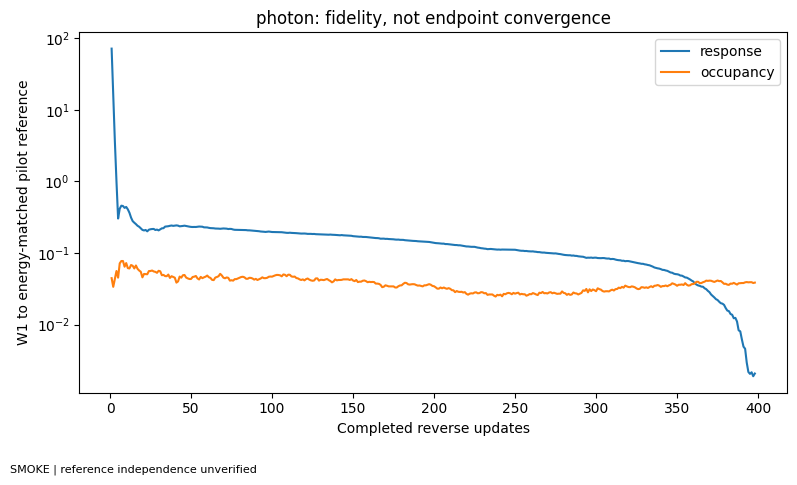

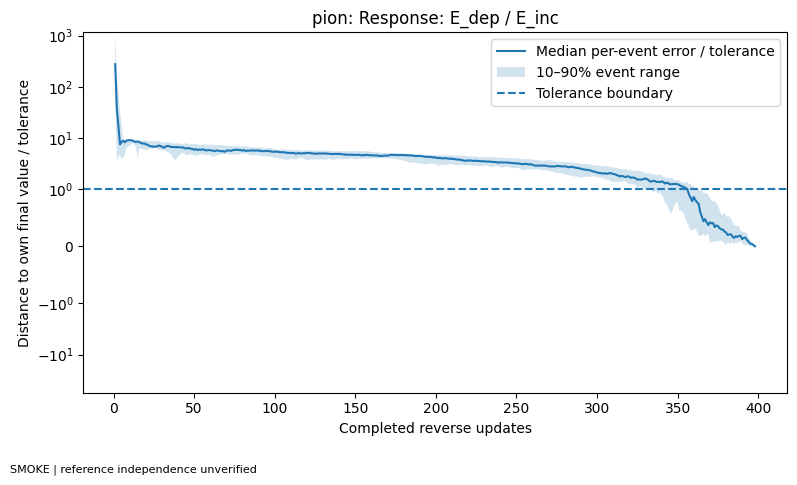

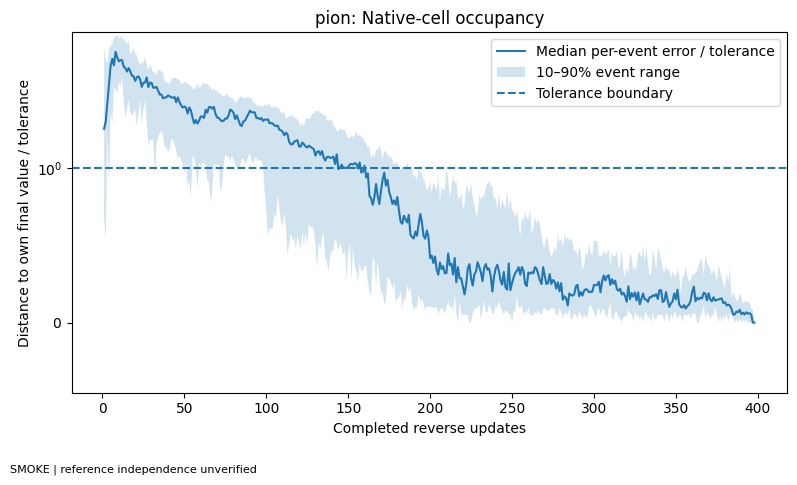

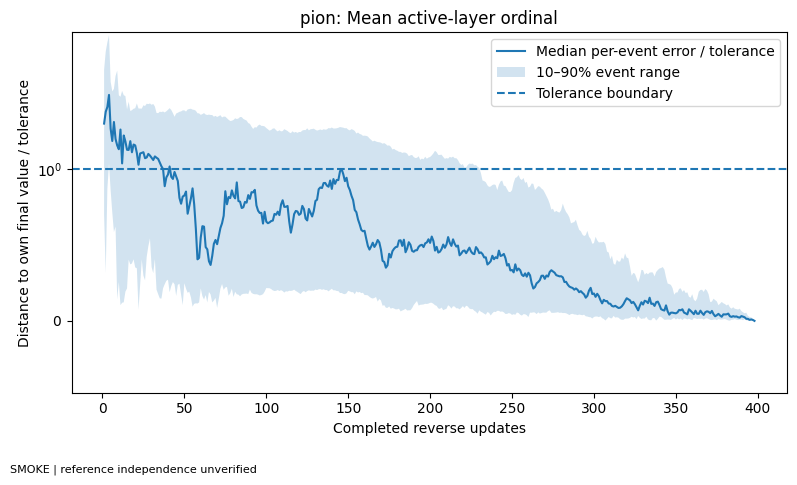

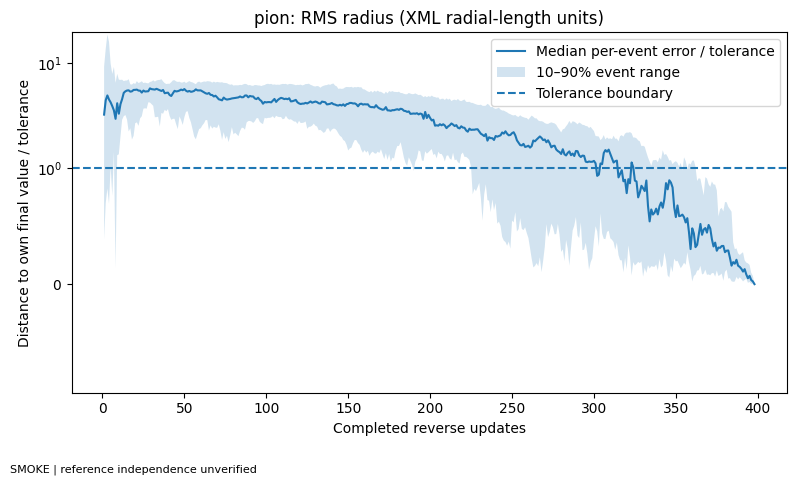

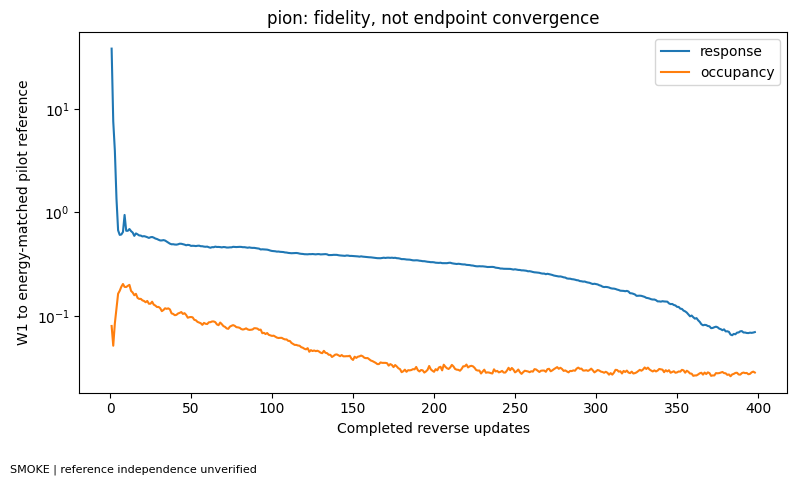

In [39]:
for p in PARTICLES:
    df=EMERGENCE[p]; final=EMERGENCE_FINALS[p].set_index('event_id')
    columns=['response','occupancy','depth_layer','r_rms'] + (['angular_m1','angular_m4'] if p=='electron' else [])
    for col in columns:
        target=df['event_id'].map(final[col]).to_numpy(dtype=float)
        atol=np.array([observable_atol(col,e,GEOMETRY[p]) for e in df['energy_GeV']])
        error=np.abs(df[col].to_numpy()-target)/(atol+.1*np.abs(target))
        work=pd.DataFrame(dict(frame=df['frame'],error=error))
        q=work.groupby('frame')['error'].quantile([.1,.5,.9]).unstack()
        fig,ax=plt.subplots(figsize=(8,4.8))
        ax.plot(q.index+1,q[.5],label='Median per-event error / tolerance')
        ax.fill_between(q.index+1,q[.1],q[.9],alpha=.2,label='10–90% event range')
        ax.axhline(1.,linestyle='--',label='Tolerance boundary')
        ax.set_yscale('symlog',linthresh=1.)
        ax.set(xlabel='Completed reverse updates',ylabel='Distance to own final value / tolerance',
               title=f'{p}: {LABELS.get(col,col)}')
        ax.legend(); finish_figure(f'{p}_{col}_emergence_error')
    fig,ax=plt.subplots(figsize=(8,4.8))
    for col in ('response','occupancy'):
        g=STEP_DISTANCES[(STEP_DISTANCES.particle==p)&(STEP_DISTANCES.observable==col)]
        ax.plot(g['frame']+1,g['w1_to_matched_reference'],label=col)
    ax.set_yscale('symlog',linthresh=.01)
    ax.set(xlabel='Completed reverse updates',ylabel='W1 to energy-matched pilot reference',title=f'{p}: fidelity, not endpoint convergence')
    ax.legend();finish_figure(f'{p}_trajectory_reference_W1')

In [40]:
colab_backup("emergence")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_emergence_20261019T153851389812Z.zip (20.11 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_emergence_20261019T153851389812Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Remaining uncertainty: branch from the same state without changing energy
At selected points, keep the intermediate state and energy fixed but draw independent future
sampler noise. For each parent state estimate the variance of the final observable across branches.
Average these conditional variances across **independent parent showers**, and compare them with
the ordinary model's marginal variance at the same fixed energy.

This asks which final properties remain stochastic given the state. It is not a measurement of
parameter learning. At the terminal state all branches coincide by construction; even the last
deterministic update has zero future-noise variance. That does not imply intermediate predictions
have already reached their final values. Interpret this alongside the emergence curves.

Branches from one parent are **not** independent parents. Confidence intervals below resample
complete parents; branch counts and parent counts are both reported. Variance ratios are not
clipped to [0,1]; finite-sample estimates can exceed one. Near-zero marginal variance yields an
undefined ratio rather than an inflated susceptibility.

electron: branch parent batch 1/2
electron: branch parent batch 2/2


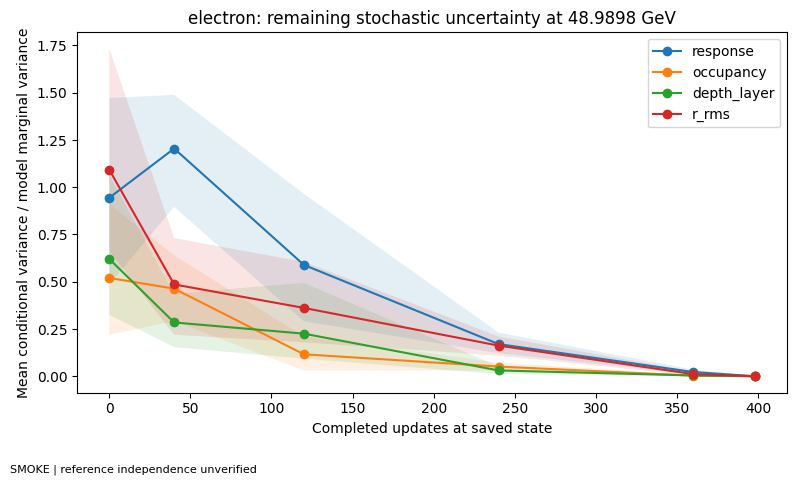

photon: branch parent batch 1/2
photon: branch parent batch 2/2


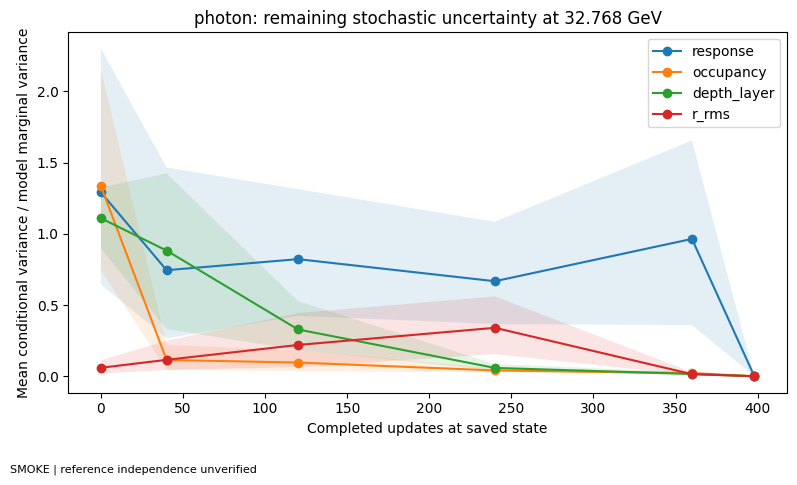

pion: branch parent batch 1/2
pion: branch parent batch 2/2


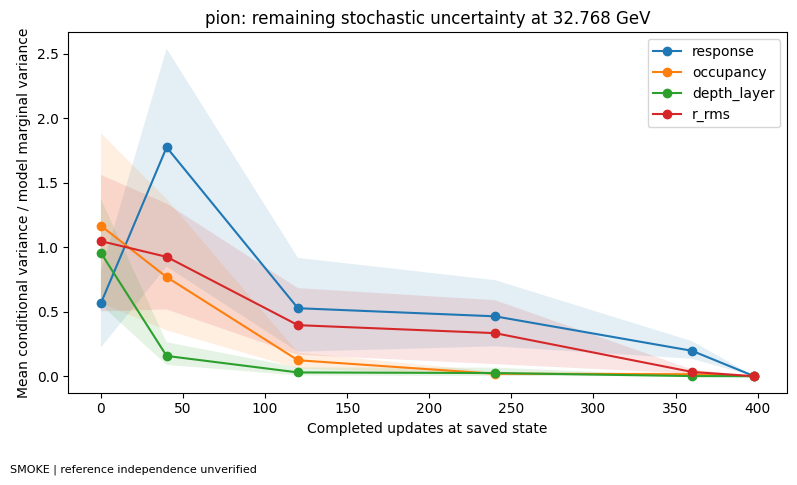

In [41]:
def save_snapshot_collection(path,snapshots,energy,particle):
    payload=dict(particle=particle,energy=np.asarray(energy),checkpoint=CHECKPOINTS[particle],
        snapshots={int(k):dict(x=v.x,next_t=v.next_t,completed_updates=v.completed_updates,rng=v.rng)
                   for k,v in snapshots.items()})
    torch.save(payload,path)


def load_trusted_snapshots(path, particle, *, trust_local_file=False):
    """Reload snapshots created by THIS study; requires the same checkpoint and RNG backend.

    PyTorch pickle loading can execute code. Never enable this for an untrusted file.
    """
    if not trust_local_file:
        raise ValueError('Explicitly set trust_local_file=True only for your own study artifact.')
    data=torch.load(path,map_location='cpu',weights_only=False)
    if data['particle']!=particle or data['checkpoint']['sha256']!=CHECKPOINTS[particle]['sha256']:
        raise ValueError('Snapshot/checkpoint provenance mismatch.')
    result={int(k):Snapshot(v['x'],int(v['next_t']),int(v['completed_updates']),v['rng'])
            for k,v in data['snapshots'].items()}
    return np.asarray(data['energy']),result


def branch_study(particle):
    model=get_model(particle); geom=GEOMETRY[particle]; ecut=model.config['ECUT']
    energy=STRATA[particle][1].nominal; e=np.full(CFG.branch_parent_events,energy)
    steps=cp.NSTEPS-CFG.sample_offset
    checkpoints=sorted(set(CFG.branch_update_counts))
    if any(k>steps for k in checkpoints): raise ValueError('Branch checkpoint beyond schedule.')
    records=[]
    for run in range(CFG.branch_parent_runs):
        print(f'{particle}: branch parent batch {run+1}/{CFG.branch_parent_runs}')
        tr=traced_generate(model,e,named_seed('branch_parent',particle,run),checkpoints)
        save_snapshot_collection(OUT/'snapshots'/f'{particle}_branch_parents_run{run}.pt',tr.snapshots,e,particle)
        for completed,snap in tr.snapshots.items():
            for branch in range(CFG.branches_per_parent):
                z=resume_native(model,snap,e,fresh_seed=named_seed('branch_future',particle,run,completed,branch))
                obs=native_observables(decode_native(model,z,e),e,geom,ecut)
                obs['parent_id']=[f'{particle}:{run}:{j}' for j in range(len(e))]
                obs['parent_run']=run; obs['branch']=branch; obs['completed_updates']=completed;obs['next_t']=snap.next_t
                records.append(obs)
    df=pd.concat(records,ignore_index=True)
    df.to_csv(OUT/'tables'/f'{particle}_branch_final_observables.csv',index=False)
    marginal_energy=np.full(max(CFG.n_test,CFG.branch_parent_events*CFG.branch_parent_runs),energy)
    marginal_native=generate_chunks(model,marginal_energy,named_seed('branch_marginal',particle))
    marginal=native_observables(marginal_native,marginal_energy,geom,ecut)
    marginal.to_csv(OUT/'tables'/f'{particle}_branch_marginal_reference_model.csv',index=False)
    rows=[]
    for completed,grp in df.groupby('completed_updates'):
        for col in OBSERVABLES:
            per_parent=grp.groupby('parent_id')[col].agg(['var','count'])
            good=per_parent['count'].eq(CFG.branches_per_parent)&np.isfinite(per_parent['var'])
            variances=per_parent.loc[good,'var'].to_numpy()
            mean,lo,hi=bootstrap_mean(variances,named_seed('branch_ci',particle,completed,col))
            marg=finite_values(marginal[col]); mv=np.var(marg,ddof=1) if len(marg)>1 else np.nan
            valid_scale=np.isfinite(mv) and mv>1e-14
            rows.append(dict(completed_updates=int(completed),observable=col,
                conditional_variance=mean,conditional_variance_lo=lo,conditional_variance_hi=hi,
                marginal_variance=mv,variance_fraction=mean/mv if valid_scale else np.nan,
                lo=lo/mv if valid_scale else np.nan,hi=hi/mv if valid_scale else np.nan,
                n_valid_parents=int(good.sum()),n_parents=len(per_parent),branches_per_parent=CFG.branches_per_parent))
    summary=pd.DataFrame(rows);summary.to_csv(OUT/'tables'/f'{particle}_branch_variance_summary.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,4.8))
    for col in ('response','occupancy','depth_layer','r_rms'):
        g=summary[summary.observable==col].sort_values('completed_updates')
        ax.plot(g['completed_updates'],g['variance_fraction'],marker='o',label=col)
        ax.fill_between(g['completed_updates'],g['lo'],g['hi'],alpha=.12)
    ax.set(xlabel='Completed updates at saved state',ylabel='Mean conditional variance / model marginal variance',
           title=f'{particle}: remaining stochastic uncertainty at {energy:g} GeV')
    ax.legend();finish_figure(f'{particle}_branch_remaining_variance')
    return summary

BRANCH_SUMMARIES={p:branch_study(p) for p in PARTICLES}

In [42]:
colab_backup("branching")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_branching_20261019T155112771746Z.zip (21.93 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_branching_20261019T155112771746Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Controlled causal splice: paired continuation, fixed decoding, both directions
This is a **stress/attribution test**, not automatically a test of the trained model's normal task.
At each saved state, resume under A and under B with identical future random numbers; decode each
continuation at A and B. AA is the unchanged continuation from that very same state—not an unrelated
pure-A sample. This separates network, conversion, combined, and interaction contributions.

The network effect at the terminal state should be zero: there are no denoiser calls left. The
conversion effect can remain nonzero, and that is expected. The native sampler carries all timestep
logic. No first-crossing 'causal lock-in' number is manufactured. A large mid-trajectory condition
switch can put the saved state off the new condition's usual trajectory; the resulting behavior
cannot on its own establish failure on ordinary generation.

Raw paired differences and event/run IDs are saved. Repeat with smaller nearby energy changes as
a follow-up; dataset-1 ordinary-fidelity comparisons should still use available reference energies.

electron: up splice batch 1/2
electron: up splice batch 2/2
electron: down splice batch 1/2
electron: down splice batch 2/2


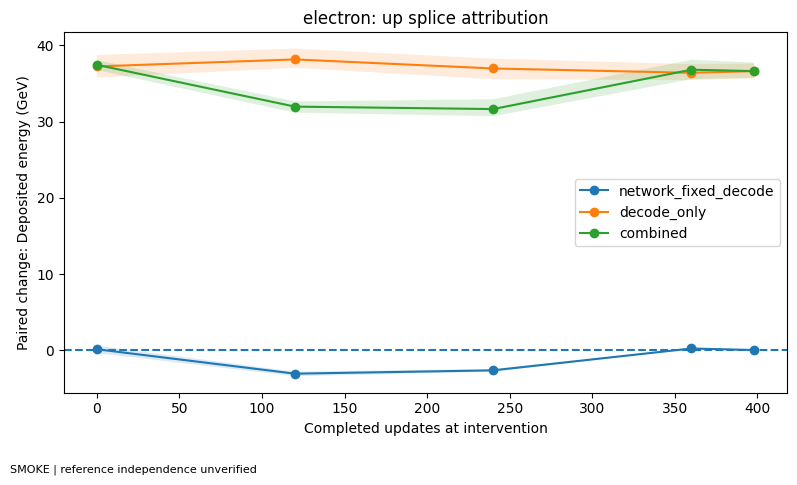

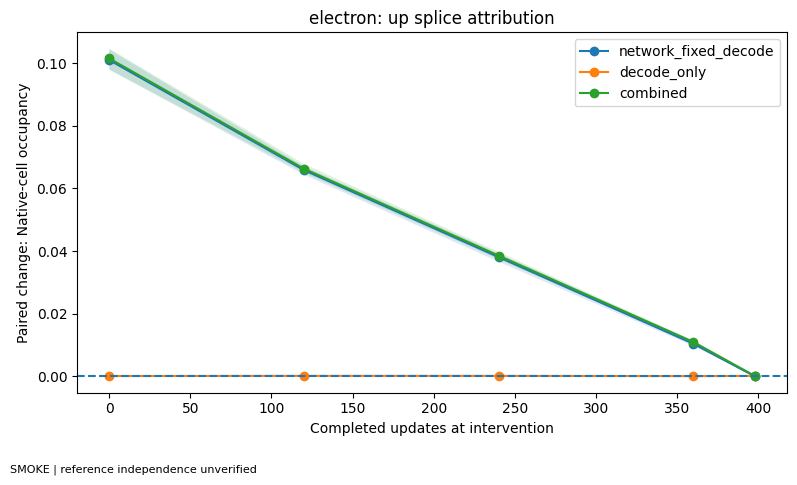

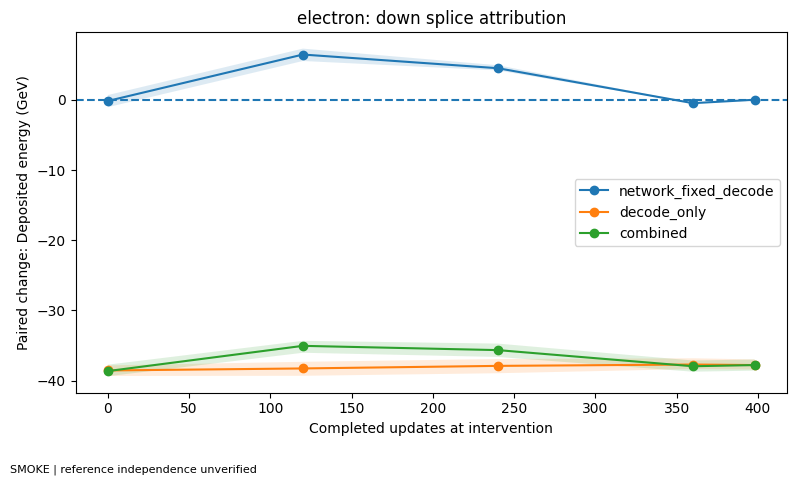

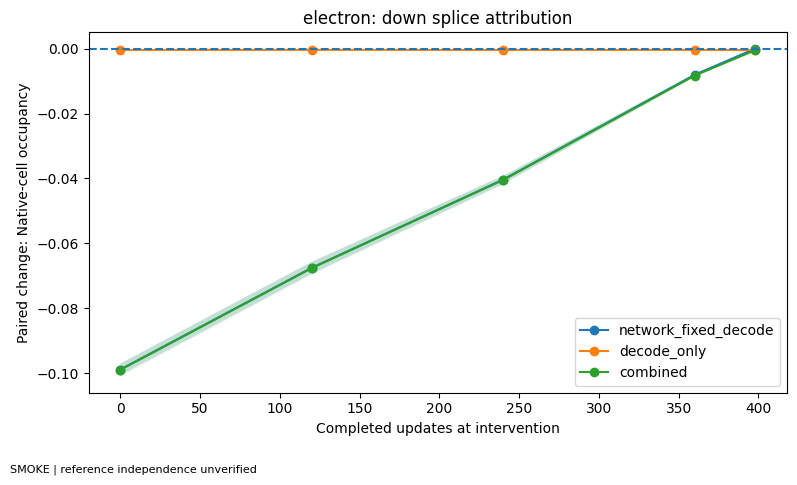

photon: up splice batch 1/2
photon: up splice batch 2/2
photon: down splice batch 1/2
photon: down splice batch 2/2


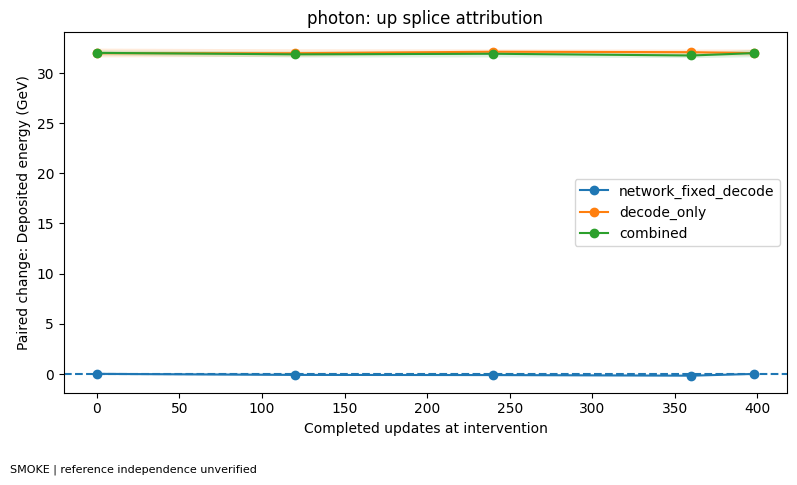

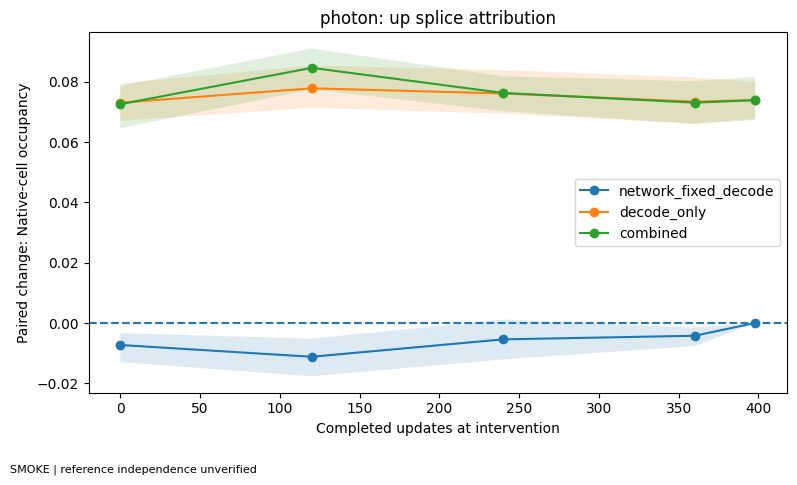

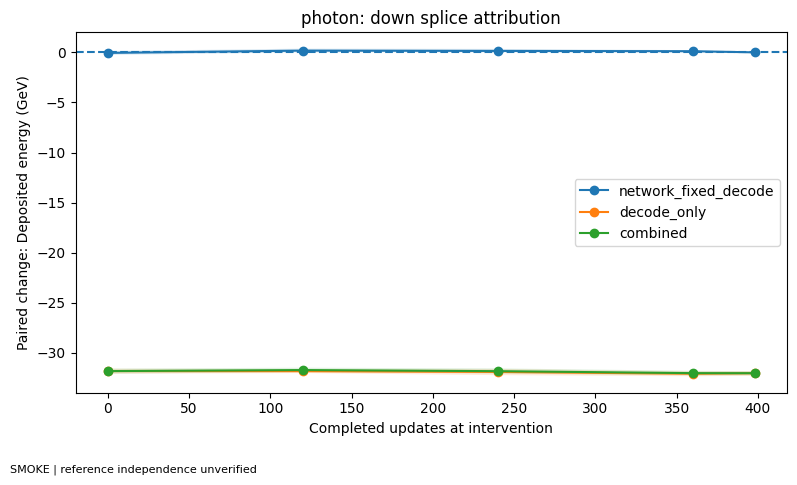

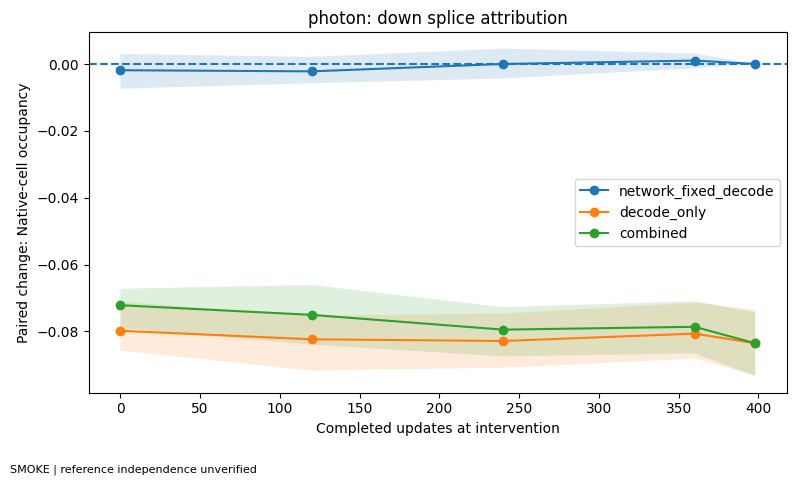

pion: up splice batch 1/2
pion: up splice batch 2/2
pion: down splice batch 1/2
pion: down splice batch 2/2


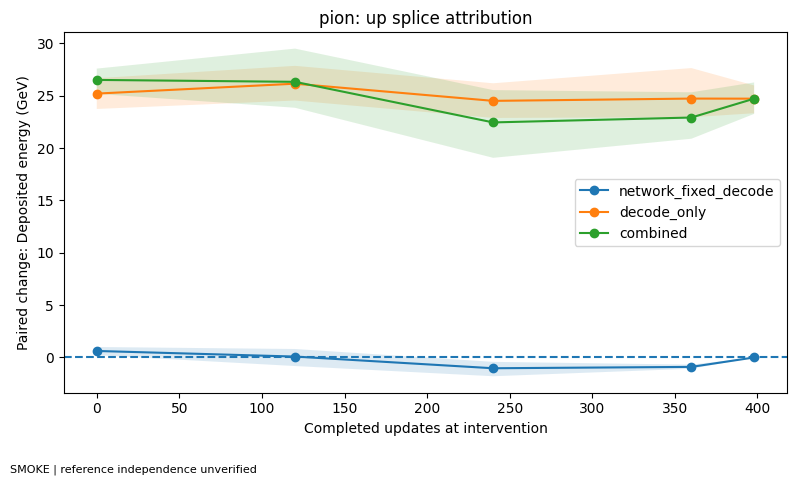

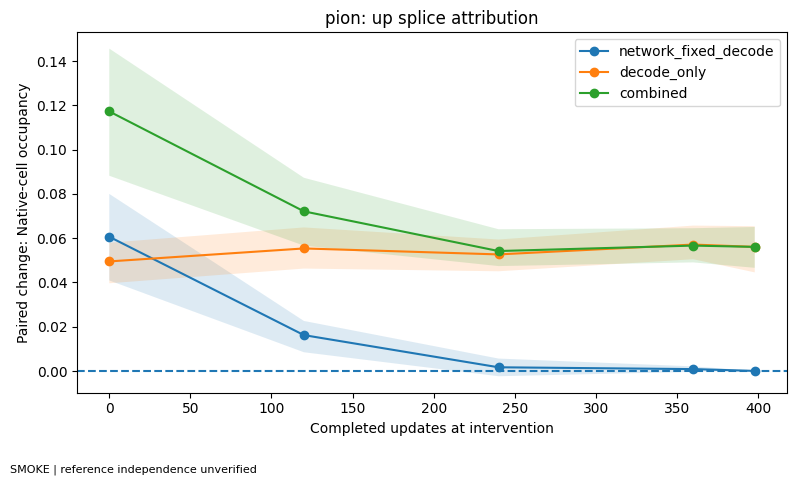

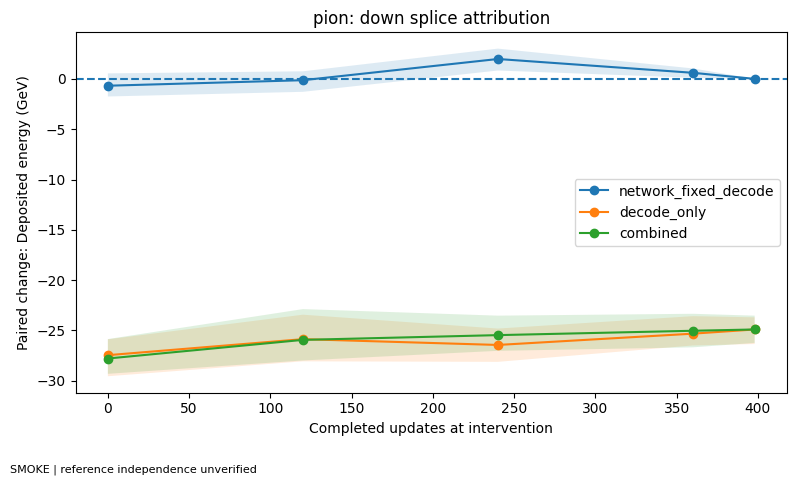

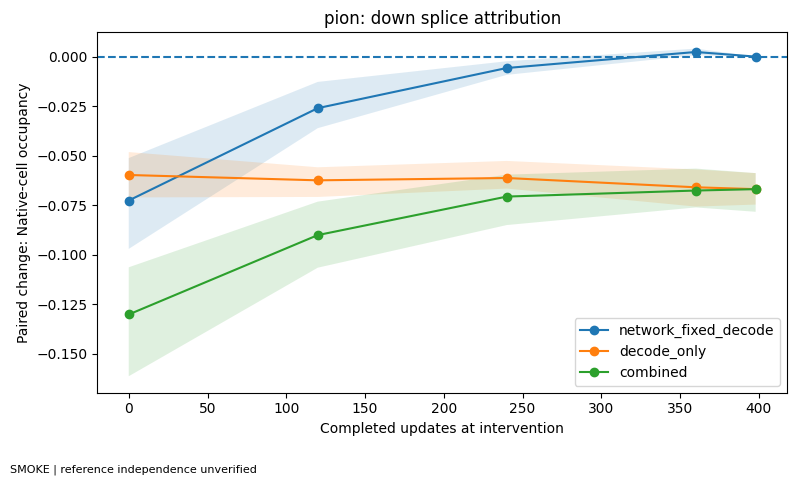

In [43]:
def controlled_splice(particle):
    model=get_model(particle); geom=GEOMETRY[particle]; ecut=model.config['ECUT']
    low,high=sorted(control_pair(particle))
    rows=[]
    for direction,A,B in [('up',low,high),('down',high,low)]:
        ea=np.full(CFG.control_events,A);eb=np.full(CFG.control_events,B)
        for run in range(CFG.control_repeats):
            print(f'{particle}: {direction} splice batch {run+1}/{CFG.control_repeats}')
            trace=traced_generate(model,ea,named_seed('splice_parent',particle,direction,run),CFG.splice_update_counts)
            for completed,snap in trace.snapshots.items():
                future=named_seed('splice_paired_future',particle,direction,run,completed)
                za=resume_native(model,snap,ea,fresh_seed=future)
                zb=resume_native(model,snap,eb,fresh_seed=future)
                cases={}
                for tag,z,decode in [('AA',za,ea),('BA',zb,ea),('AB',za,eb),('BB',zb,eb)]:
                    cases[tag]=native_observables(decode_native(model,z,decode),decode,geom,ecut)
                for col in OBSERVABLES:
                    aa,ba,ab,bb=[cases[k][col].to_numpy() for k in ('AA','BA','AB','BB')]
                    effects={'network_fixed_decode':ba-aa,'decode_only':ab-aa,'combined':bb-aa,
                             'network_at_B_decode':bb-ab,'interaction':bb-ba-ab+aa}
                    for contrast,delta in effects.items():
                        for j,v in enumerate(delta):
                            rows.append(dict(direction=direction,source_energy=A,target_energy=B,run=run,
                                parent_id=f'{direction}:{run}:{j}',completed_updates=completed,next_t=snap.next_t,
                                observable=col,contrast=contrast,delta=v))
                if snap.next_t<0:
                    gate(f'{particle}: terminal network-only effect {direction}/{run}',np.array_equal(za,zb))
    df=pd.DataFrame(rows);df.to_csv(OUT/'tables'/f'{particle}_controlled_splice_effects.csv',index=False)
    summary=[]
    for (direction,completed,col,contrast),g in df.groupby(['direction','completed_updates','observable','contrast']):
        mean,lo,hi=bootstrap_mean(g['delta'],named_seed('splice_ci',particle,direction,completed,col,contrast))
        summary.append(dict(direction=direction,completed_updates=completed,observable=col,contrast=contrast,
                            mean_effect=mean,lo=lo,hi=hi,n_parents=g['parent_id'].nunique()))
    out=pd.DataFrame(summary);out.to_csv(OUT/'tables'/f'{particle}_controlled_splice_summary.csv',index=False)
    for direction in ('up','down'):
        for col in ('deposited_GeV','occupancy'):
            fig,ax=plt.subplots(figsize=(8,4.8))
            for contrast in ('network_fixed_decode','decode_only','combined'):
                g=out[(out.direction==direction)&(out.observable==col)&(out.contrast==contrast)].sort_values('completed_updates')
                ax.plot(g['completed_updates'],g['mean_effect'],marker='o',label=contrast)
                ax.fill_between(g['completed_updates'],g['lo'],g['hi'],alpha=.15)
            ax.axhline(0,linestyle='--')
            ax.set(xlabel='Completed updates at intervention',ylabel=f'Paired change: {LABELS[col]}',
                   title=f'{particle}: {direction} splice attribution')
            ax.legend();finish_figure(f'{particle}_{direction}_{col}_controlled_splice')
    return out

SPLICE_SUMMARIES={p:controlled_splice(p) for p in PARTICLES}

In [44]:
colab_backup("splicing")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_splicing_20261019T160527338725Z.zip (22.97 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_splicing_20261019T160527338725Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Optional: honest within-model CKA and a simple linear-readout comparison
Enable `RUN_OPTIONAL_REPRESENTATION_DIAGNOSTICS` in Section 1 **before** collecting trajectories.
These diagnostics are secondary to output-level fidelity. There is no SAE training in this study:
it would add an additional model-selection and reconstruction-validation question.

CKA compares corresponding shower identities within the same model. Adjacent-step and
final-reference similarity are distinct curves, and a row-permutation control is shown. A high CKA
score is similarity of representation geometry, not proof of semantic understanding or unchanged
activations. No final-point exclusion or arbitrary cross-particle row pairing is used.

The probe is genuine ridge regression on the pooled bottleneck vector. Complete generated events
are split into train/validation/test, so their frames never cross partitions. A per-step mean fitted
only to training events is the baseline. Pooled R2 and skill relative to that baseline are reported;
both are distinct from reference-data fidelity. Spatial pooling can discard information, so failed
prediction here is not proof that information is absent from the full network.

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

def linear_cka_checked(X,Y):
    X=np.asarray(X,dtype=np.float64);Y=np.asarray(Y,dtype=np.float64)
    if X.ndim!=2 or Y.ndim!=2 or len(X)!=len(Y) or len(X)<3: return np.nan
    if not np.isfinite(X).all() or not np.isfinite(Y).all(): return np.nan
    X=X-X.mean(axis=0,keepdims=True);Y=Y-Y.mean(axis=0,keepdims=True)
    denom=np.linalg.norm(X.T@X,'fro')*np.linalg.norm(Y.T@Y,'fro')
    if denom<=1e-20: return np.nan
    return float(np.linalg.norm(X.T@Y,'fro')**2/denom)


def representation_diagnostics(particle):
    H=FEATURE_BANK[particle];S,N,C=H.shape
    if N<12: raise ValueError('At least 12 complete events are required for this optional diagnostic.')
    # Concatenation order in FEATURE_BANK: run, then event within each run.
    ids=EMERGENCE_FINALS[particle]['event_id'].to_numpy()
    table=EMERGENCE[particle]
    target=table.pivot(index='frame',columns='event_id',values='response').reindex(columns=ids).to_numpy()
    if target.shape!=(S,N): raise RuntimeError('Feature/observable event alignment failed.')
    rng=np.random.default_rng(named_seed('representation',particle))
    permutation=rng.permutation(N)
    cka=pd.DataFrame(dict(frame=np.arange(S),
        to_final=[linear_cka_checked(H[t],H[-1]) for t in range(S)],
        adjacent=[linear_cka_checked(H[t],H[t+1]) for t in range(S-1)]+[np.nan],
        permuted_final=[linear_cka_checked(H[t],H[-1,permutation]) for t in range(S)]))
    cka.to_csv(OUT/'tables'/f'{particle}_within_model_CKA.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,4.8))
    for col in ('adjacent','to_final','permuted_final'):ax.plot(cka['frame']+1,cka[col],label=col)
    ax.set(xlabel='Completed updates',ylabel='Linear CKA',title=f'{particle}: corresponding events, same model')
    ax.legend();finish_figure(f'{particle}_within_model_CKA')
    order=rng.permutation(N);a=int(.6*N);b=int(.8*N)
    splits={'train':order[:a],'validation':order[a:b],'test':order[b:]}
    if any(len(v)<2 for v in splits.values()):raise ValueError('Not enough complete events for probe splits.')
    train_X=H[:,splits['train'],:].reshape(-1,C);train_y=target[:,splits['train']].reshape(-1)
    valid=np.isfinite(train_y)&np.isfinite(train_X).all(axis=1)
    reg=make_pipeline(StandardScaler(),Ridge(alpha=1.0))
    reg.fit(train_X[valid],train_y[valid])
    baseline=np.nanmean(target[:,splits['train']],axis=1)
    results=[]
    for split,idx in splits.items():
        x=H[:,idx,:].reshape(-1,C);y=target[:,idx].reshape(-1)
        pred=reg.predict(x);base=np.repeat(baseline,len(idx))
        ok=np.isfinite(y)&np.isfinite(pred)&np.isfinite(base)
        mse=mean_squared_error(y[ok],pred[ok]);bmse=mean_squared_error(y[ok],base[ok])
        results.append(dict(split=split,n_events=len(idx),r2_pooled=r2_score(y[ok],pred[ok]),
            mse=mse,timestep_baseline_mse=bmse,skill_vs_timestep_baseline=1-mse/bmse if bmse>0 else np.nan))
    result=pd.DataFrame(results);result.to_csv(OUT/'tables'/f'{particle}_ridge_probe_summary.csv',index=False)
    save_json(OUT/f'{particle}_probe_event_split.json',{k:ids[v] for k,v in splits.items()})
    return result

if RUN_OPTIONAL_REPRESENTATION_DIAGNOSTICS:
    for p in PARTICLES: display(representation_diagnostics(p))
else:
    print('Optional CKA/readouts skipped by configuration; no SAE or generator retraining was performed.')

Optional CKA/readouts skipped by configuration; no SAE or generator retraining was performed.


In [46]:
colab_backup("representations")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_representations_20261019T160537463718Z.zip (22.97 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_representations_20261019T160537463718Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

## 16. Export native HDF5 for later official evaluation
The exported generator sample uses **run 0** at exactly the selected reference energies. Native
voxel order is preserved; both HDF5 datasets use MeV, matching the standard challenge format.
The reference export retains original reference deposits so an official evaluator can apply its
own documented cuts. The generator already contains the repository's configured cutoff.

These are selected-energy study exports, not a full published benchmark reproduction. Official
evaluation requires its own documented environment, features, dataset splits, and adequate statistics.
Do not relabel this notebook's small high-level classifier as that official evaluation.

In [47]:
def export_official_hdf5(path,native_gev,energy_gev,description):
    native=np.asarray(native_gev,dtype=np.float64).reshape(len(energy_gev),-1)
    energy=np.asarray(energy_gev,dtype=np.float64).reshape(-1,1)
    if not np.isfinite(native).all() or (native<0).any():raise ValueError('Invalid exported physical deposits.')
    with h5py.File(path,'w') as f:
        f.create_dataset('showers',data=(native*1000).astype(np.float32),compression='gzip')
        f.create_dataset('incident_energies',data=(energy*1000).astype(np.float32),compression='gzip')
        f.attrs['energy_unit']='MeV';f.attrs['description']=description
        f.attrs['run_tag']=RUN_TAG;f.attrs['reference_provenance']=REFERENCE_PROVENANCE
        f.attrs['reference_is_unseen_by_checkpoint']=REFERENCE_IS_UNSEEN_BY_CHECKPOINT

for p in PARTICLES:
    generated,reference,energies=[],[],[]
    for s in STRATA[p]:
        with np.load(NATIVE_BANK[(p,s.label,'generator',0)],allow_pickle=False) as f:
            generated.append(f['native']);energies.append(f['energy'])
        batch=read_events(REFERENCES[p],s.partitions['test']);reference.append(batch.native)
        gate(f'{p}/{s.label}: export energy matching',np.array_equal(energies[-1],batch.energy))
    e=np.concatenate(energies)
    export_official_hdf5(OUT/'official_exports'/f'{p}_generated.hdf5',np.concatenate(generated),e,
                        'Run-0 standard generator, selected reference energies, native voxels, configured generator cutoff.')
    export_official_hdf5(OUT/'official_exports'/f'{p}_reference.hdf5',np.concatenate(reference),e,
                        'Original unthresholded selected reference events; provenance status is recorded.')

In [48]:
colab_backup("exports")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_exports_20261019T160548142635Z.zip (26.08 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_exports_20261019T160548142635Z.zip')

In [ ]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Generate an evidence report—not a preset verdict about the model
Technical gates establish that the measurement pipeline behaves as intended on the examples
checked. They are not physics acceptance tests. A model-change decision needs a reproducible,
practically important discrepancy on a justified reference split, stable across sample sizes,
energy strata, and random seeds. Diagnose units/geometry/sampling/thresholds before changing weights.

Reading order for a guide meeting:
1. `validation_gates.json` and provenance in `manifest.json`.
2. Response/shape distributions and `fidelity_distances.csv`, alongside scale-only controls.
3. Paired denoising penalties and separated energy pathways.
4. Individual emergence and remaining-variance curves.
5. Only then the conditional-splice stress test and optional representation diagnostics.

The run report below records outputs and limitations without converting statistical fluctuations
into declarations that the model 'understands', 'cheats', or must be retrained.

In [49]:
MANIFEST['completed_utc']=datetime.now(timezone.utc).isoformat()
MANIFEST['n_passed_technical_checks']=sum(g['passed'] for g in GATES)
MANIFEST['analysis_status']='smoke_only' if MODE=='smoke' else (
    'reference_independence_verified_by_user' if REFERENCE_IS_UNSEEN_BY_CHECKPOINT else 'exploratory_reference')
save_json(OUT/'manifest.json',MANIFEST)
limitation=[]
if MODE=='smoke':limitation.append('Smoke-mode sample sizes: do not make physical-fidelity claims from these statistics.')
if not REFERENCE_IS_UNSEEN_BY_CHECKPOINT:
    limitation.append('Reference independence from checkpoint training is unverified; the run is exploratory.')
limitation += ['Reference comparisons use selected energies/windows, not the full published benchmark.',
    'Depth defaults to active-layer ordinal; radius uses XML bin-center coordinates, not sub-voxel truth.',
    'Intervals are conditional on fixed calibration fits and selected energy strata.',
    'Branch ratios divide by an estimated model marginal variance; denominator uncertainty is not propagated.',
    'Condition-switching and mixed-decoder cases are diagnostic interventions, not ordinary physical generation.',
    'No official FPD/KPD, official classifier reproduction, or generative retraining was performed.']
response_table=DISTANCES[DISTANCES.observable.eq('response')]
report='\n'.join([
    '# Validated conditional-generation study: run report',
    f'Run: `{RUN_TAG}`',f'Mode: `{MODE}`',f'Status: `{MANIFEST["analysis_status"]}`',
    f'Technical checks passed: {MANIFEST["n_passed_technical_checks"]}',
    '## Provenance',REFERENCE_PROVENANCE,
    '## Response distribution distances (descriptive; see confidence intervals)',
    '```text',response_table.to_string(index=False),'```',
    '## Limitations',*['- '+s for s in limitation],
    '## Before considering a model change',
    'Name the failing observable and energy stratum, quantify practical effect size and uncertainty,',
    'confirm reference provenance, and reproduce the mismatch with the unchanged official sampler.',
    'Do not infer a training failure from explicit conditioning, a decoder rescaling, or a failed probe alone.',
    '## Outputs',
    'tables/: event-level observations, effects, partitions, metrics, and uncertainty summaries.',
    'arrays/: native generated deposits and compressed per-event emergence trajectories.',
    'snapshots/: trusted local states with explicit next_t and RNG state for replay.',
    'figures/: separately saved PNG figures.',
    'official_exports/: native-order MeV HDF5 samples with matched incident energies.',
])
(OUT/'run_report.md').write_text(report)
# Save an output inventory. Hashing large generated artifacts is optional; file sizes are recorded.
save_json(OUT/'output_inventory.json',[
    dict(path=str(p.relative_to(OUT)),bytes=p.stat().st_size) for p in sorted(OUT.rglob('*')) if p.is_file()])
print('Study outputs:',OUT)
display(Markdown(report))

Study outputs: /content/gen-hep-notebooks/capstone/calodiffusion/validated_results/validated_calo_smoke_20261019T151143722314Z


# Validated conditional-generation study: run report
Run: `validated_calo_smoke_20261019T151143722314Z`
Mode: `smoke`
Status: `smoke_only`
Technical checks passed: 75
## Provenance
Local course cache; original event provenance not yet established.
## Response distribution distances (descriptive; see confidence intervals)
```text
particle   stratum               method observable       w1    w1_lo    w1_hi       ks
electron   8-12GeV            generator   response 0.013884 0.013702 0.040457 0.125000
electron   8-12GeV        mean_fraction   response 0.082098 0.066876 0.096073 0.546875
electron   8-12GeV           scale_only   response 0.048246 0.034641 0.066957 0.265625
electron   8-12GeV       uniform_native   response 0.082131 0.069797 0.097139 0.546875
electron   8-12GeV reference_half_split   response 0.023244      NaN      NaN 0.250000
electron  40-60GeV            generator   response 0.017729 0.010376 0.028017 0.265625
electron  40-60GeV        mean_fraction   response 0.038088 0.032525 0.045702 0.625000
electron  40-60GeV           scale_only   response 0.010972 0.008753 0.021643 0.171875
electron  40-60GeV       uniform_native   response 0.038086 0.030173 0.045840 0.625000
electron  40-60GeV reference_half_split   response 0.025802      NaN      NaN 0.375000
electron 80-120GeV            generator   response 0.004970 0.005257 0.012909 0.109375
electron 80-120GeV        mean_fraction   response 0.027444 0.022007 0.031302 0.500000
electron 80-120GeV           scale_only   response 0.006860 0.005436 0.015753 0.093750
electron 80-120GeV       uniform_native   response 0.027445 0.021754 0.031622 0.500000
electron 80-120GeV reference_half_split   response 0.004273      NaN      NaN 0.093750
  photon  8.192GeV            generator   response 0.011740 0.008442 0.020146 0.218750
  photon  8.192GeV        mean_fraction   response 0.024687 0.020045 0.029123 0.515625
  photon  8.192GeV           scale_only   response 0.014108 0.009894 0.020191 0.296875
  photon  8.192GeV       uniform_native   response 0.055698 0.049229 0.063734 0.953125
  photon  8.192GeV reference_half_split   response 0.007408      NaN      NaN 0.125000
  photon 32.768GeV            generator   response 0.009163 0.006100 0.013823 0.226562
  photon 32.768GeV        mean_fraction   response 0.009774 0.008168 0.011172 0.609375
  photon 32.768GeV           scale_only   response 0.001611 0.001589 0.005753 0.140625
  photon 32.768GeV       uniform_native   response 0.012255 0.009943 0.014677 0.812500
  photon 32.768GeV reference_half_split   response 0.005775      NaN      NaN 0.312500
  photon 65.536GeV            generator   response 0.006867 0.004609 0.009777 0.203125
  photon 65.536GeV        mean_fraction   response 0.007752 0.006429 0.009172 0.515625
  photon 65.536GeV           scale_only   response 0.006354 0.003716 0.009591 0.343750
  photon 65.536GeV       uniform_native   response 0.009404 0.007641 0.011140 0.765625
  photon 65.536GeV reference_half_split   response 0.002667      NaN      NaN 0.281250
    pion  8.192GeV            generator   response 0.031808 0.022921 0.079438 0.101562
    pion  8.192GeV        mean_fraction   response 0.168878 0.138688 0.209866 0.703125
    pion  8.192GeV           scale_only   response 0.102339 0.060856 0.153884 0.312500
    pion  8.192GeV       uniform_native   response 0.139851 0.111717 0.165502 0.562500
    pion  8.192GeV reference_half_split   response 0.045857      NaN      NaN 0.250000
    pion 32.768GeV            generator   response 0.018795 0.018297 0.051204 0.132812
    pion 32.768GeV        mean_fraction   response 0.085294 0.063258 0.100208 0.562500
    pion 32.768GeV           scale_only   response 0.057667 0.032216 0.101326 0.171875
    pion 32.768GeV       uniform_native   response 0.088088 0.074643 0.105700 0.640625
    pion 32.768GeV reference_half_split   response 0.033239      NaN      NaN 0.218750
    pion 65.536GeV            generator   response 0.021278 0.016391 0.055868 0.132812
    pion 65.536GeV        mean_fraction   response 0.080855 0.067685 0.094982 0.546875
    pion 65.536GeV           scale_only   response 0.051596 0.032890 0.097641 0.156250
    pion 65.536GeV       uniform_native   response 0.080519 0.063271 0.095930 0.531250
    pion 65.536GeV reference_half_split   response 0.038420      NaN      NaN 0.250000
```
## Limitations
- Smoke-mode sample sizes: do not make physical-fidelity claims from these statistics.
- Reference independence from checkpoint training is unverified; the run is exploratory.
- Reference comparisons use selected energies/windows, not the full published benchmark.
- Depth defaults to active-layer ordinal; radius uses XML bin-center coordinates, not sub-voxel truth.
- Intervals are conditional on fixed calibration fits and selected energy strata.
- Branch ratios divide by an estimated model marginal variance; denominator uncertainty is not propagated.
- Condition-switching and mixed-decoder cases are diagnostic interventions, not ordinary physical generation.
- No official FPD/KPD, official classifier reproduction, or generative retraining was performed.
## Before considering a model change
Name the failing observable and energy stratum, quantify practical effect size and uncertainty,
confirm reference provenance, and reproduce the mismatch with the unchanged official sampler.
Do not infer a training failure from explicit conditioning, a decoder rescaling, or a failed probe alone.
## Outputs
tables/: event-level observations, effects, partitions, metrics, and uncertainty summaries.
arrays/: native generated deposits and compressed per-event emergence trajectories.
snapshots/: trusted local states with explicit next_t and RNG state for replay.
figures/: separately saved PNG figures.
official_exports/: native-order MeV HDF5 samples with matched incident energies.

In [50]:
colab_backup("final_report")

BACKUP SAVED: /content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_final_report_20261019T160558585107Z.zip (26.08 MiB)


PosixPath('/content/calo_backup_staging/validated_calo_smoke_20261019T151143722314Z_final_report_20261019T160558585107Z.zip')

In [51]:
from google.colab import files as colab_files

colab_files.download(COLAB_LAST_BACKUP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References and implementation boundaries
**Source-derived:** the conditional-generation task, preprocessing conventions, supplied geometries,
native sampler, energy/time conditioning, and checkpoint objective come from the CaloDiffusion
paper and the repository listed in `SOURCES` (Section 1). The original project primer motivates
the four observables and the electron angular-FFT study.

**New proposed study design:** event partitions, calibration baselines, numerical gates, paired
conditioning controls, robust event-level lock-in, and branch-variance measurements are implemented
here to test—not assume—the earlier interpretations. Their results are not claims already made by
the paper. The notebook deliberately does not repair or retrain the generator.

**Relevant primary sources**
- Amram and Pedro, *Denoising diffusion models with geometry adaptation for high fidelity calorimeter
  simulation*, arXiv:2308.03876 / Phys. Rev. D 108, 072014.
- CaloChallenge public dataset and evaluation documentation.
- `calodiff_probe.py`, `CaloDiffu.py`, `utils.py`, supplied particle configurations and native XML files.
- Kornblith et al., *Similarity of Neural Network Representations Revisited* (2019), for CKA.

Exact source URLs, local SHA256 hashes, package versions, paths, event IDs and generation seeds
are available in the run manifest and tables. Archive this notebook with that run directory.

# Colab operations and troubleshooting

**A session ended:** open your saved notebook and recreate the runtime (setup A–F). Archives you downloaded or copied to Drive
contain saved outputs, not live variables. Archives left only under `/content` are lost with the runtime. This edition does not automatically resume the full
pipeline at the interrupted cell. A fresh scientific run should get a new `RUN_TAG`. The original
`load_trusted_snapshots` helper supports explicit same-checkpoint continuation work; changing hardware
or software can prevent exact replay. Do not use `ALLOW_EXISTING_RUN=True` just to bypass a conflict.

**GPU out of memory:** decrease `CFG.batch_size` for standard generation and separately decrease
`trace_events_per_run`, `noise_test_events_per_bin`, `control_events`, and `branch_parent_events`
when the error occurs in those sections. Make changes in the configuration cell and rerun from a
fresh kernel/run. Some transform audits use a fixed small pilot batch and do not consume batch_size.
Keep enough parents/branches and independent runs for a later scientific study. No TPU, automatic
mixed precision, or `torch.compile` conversion is part of this validated setup.

**Insufficient reference events:** the light profile needs 32 + 16 + 32 = 80 distinct events per
selected energy stratum. Obtain suitable data or explicitly predeclare smaller partitions; never
reuse test events to fill calibration. Research mode usually needs a larger dataset than the caches.

**Missing files or LFS pointers:** supply the real file at the path printed in setup E, or put it in
`MyDrive/CaloDiffusion_assets/` using the same relative structure. Data and checkpoints are not in
the notebook package. Rerun asset validation; do not rename a pointer file to pretend it is a model.

**Numerical/package errors:** keep the installed Torch/CUDA pairing. Restart after replacing loaded
packages. Colab supports past runtime versions in Runtime → Change runtime type; choose a recorded
known-working environment when necessary, not an arbitrary downgrade. Retain `pip_freeze.txt`,
`manifest.json`, `colab_setup.json`, and `validation_gates.json` for diagnosis.

**Speed:** the original 400-step schedule with offset 2 still executes 398 updates. Reduce smoke-test
events, branch counts, and repetitions first. Do not shorten `num_steps`, change the threshold, or
weaken a numerical tolerance just to finish in one Colab session. Benchmark one particle before
scaling up; session duration and GPU availability are not guaranteed.

**Manual backup:** `colab_backup("manual")`. The latest archive path is `COLAB_LAST_BACKUP`.
For a local archive without Drive, download it using the Files panel or the optional code below.
You must save your edited notebook in Drive separately from these result archives.

In [ ]:
# Optional final download. The large original assets/checkpoints are not included in result archives.
DOWNLOAD_LAST_ARCHIVE = False
if DOWNLOAD_LAST_ARCHIVE:
    if 'COLAB_LAST_BACKUP' not in globals():
        raise RuntimeError('No completed archive. Run colab_backup("manual") first.')
    from google.colab import files as colab_files
    colab_files.download(COLAB_LAST_BACKUP)

## Sources for the Colab setup layer
- [Google Colab FAQ: upload, GPU availability, transient runtime storage, Drive I/O](https://research.google.com/colaboratory/faq.html)
- [Google Colab runtime-version FAQ](https://research.google.com/colaboratory/runtime-version-faq.html)
- [Git sparse clone documentation](https://git-scm.com/docs/git-clone)
- [GitHub: installing Git LFS](https://docs.github.com/en/repositories/working-with-files/managing-large-files/installing-git-large-file-storage)
- [Project wrapper and asset paths](https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/calodiff_probe.py)

Colab-specific settings/backup cells were added; the original study algorithms are unchanged.
The original study references appear above.

## Verified public starting points
- [Project README: committed reference caches and checkpoints](https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/README.md)
- [Electron HDF5 cache (GitHub lists 81.1 MB)](https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/data/calochallenge_ds2.hdf5)
- [Electron checkpoint (GitHub lists 6.16 MB)](https://github.com/Vishal21501/gen-hep-notebooks/blob/main/capstone/calodiffusion/paper_code/trained_models/dataset2.pth)
These sizes are rounded GitHub display values, not required checksums. Re-check listings if the
repository changes. The study records the exact Git revision and local file hashes when executed.
